# TP Final — Inteligencia Artificial 2026 (UNAB)
## Predicción del siguiente carácter sobre *"The Festival"* (H. P. Lovecraft)

**Grupo 9:** Leonardo Carabajal, Brian Fernandez, Thiago Montenegro Yerumini.

**Docente:** Pablo Moreira.

**Dataset asignado:** *The Festival* de H. P. Lovecraft (texto literario).

---

### Índice
| Etapa | Contenido | Secciones |
|---|---|---|
| **1** | EDA, partición por bloques y baseline | 1 a 4 |
| **2** | Análisis de errores, MLP y regularización | 5 a 9 |
| **3** | Embeddings, LSTM y embeddings de palabras pre-entrenados | 1 a 8 |
| **4** | Modelo generativo (optativa) | no realizada |
| **5** | Evaluación final en Test, tabla comparativa, ética y conclusiones | 1 a 5 |

La numeración de secciones se reinicia en las Etapas 3 y 5.

### Ejecución
- Las salidas son las de las corridas locales del 21/11/2026 (CPU, sin GPU). Ejecutar todo de principio a fin tarda unas 1,5 horas; el detalle está en `README.md`.
- La Etapa 3 descarga GloVe 6B (unos 860 MB) la primera vez y carga los resultados de R2 de `data/processed/cache_R2.json` para no reentrenarlo (unos 50 minutos).
- **Test se evalúa una sola vez, en la Etapa 5.**
- Los experimentos que probamos y sacamos de este notebook están en `experimentos/`.

---
# ETAPA 1: Exploración, partición y baseline

## Etapas 1 y 2: la tarea y las decisiones generales

### La tarea
Queremos construir un modelo que genere texto carácter a carácter. En las Etapas 1 y 2 lo planteamos como una **clasificación multiclase**:
- **Entrada ($X$):** una ventana de $L = 40$ caracteres consecutivos. El baseline y el MLP usan solo los últimos $K = 5$.
- **Salida ($y$):** el carácter siguiente, una de las $|V| = 64$ clases del vocabulario.

### Decisiones generales
1. **Limpieza dentro del notebook:** partimos del archivo original (`The_Festival.txt`) y mostramos el efecto de cada transformación, para que sea reproducible.
2. **Partición por bloques contiguos (70% Train, 15% Dev, 15% Test):** evita que ventanas casi idénticas queden a la vez en Train y en Dev.
3. **Vocabulario completo:** conservamos todos los caracteres del texto, así Dev refleja la dificultad real.
4. **Métrica:** accuracy top-1 en Dev, comparada con predecir siempre el carácter más frecuente.
5. **Baseline:** regresión logística sobre el one-hot de los últimos $K = 5$ caracteres.
6. **Misma entrada para el MLP:** el MLP de la Etapa 2 usa los mismos 5 caracteres, así la comparación mide el efecto de la red y no de un cambio en los datos.
7. **Framework:** TensorFlow / Keras (`tf.keras`) para todos los modelos neuronales.
8. **5 semillas:** cada MLP se entrena con `SEEDS = [42, 123, 456, 789, 2026]` y reportamos media ± desvío.
9. **Test intacto:** no se usa hasta la Etapa 5.


In [1]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO E IMPORTACIÓN DE BIBLIOTECAS
# ==============================================================================
import os
import re
import json
import time
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Estilo visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Semilla de aleatoriedad fija para reproducibilidad
SEED = 42
np.random.seed(SEED)

print("Entorno y bibliotecas configurados correctamente.")


Entorno y bibliotecas configurados correctamente.


---
# 1. Consigna 4.1.1: Carga y Análisis Exploratorio del Dataset (EDA)

## 1.1 Carga del archivo original y preprocesamiento de limpieza
Cargamos `The_Festival.txt` tal como fue provisto y, dentro del notebook, le aplicamos cuatro transformaciones mínimas:

| Paso | Transformación | Justificación |
|---|---|---|
| 1. Fin de línea | `CRLF` $\to$ `LF` | Estandariza los saltos de línea y elimina el retorno de carro `\r` de Windows. |
| 2. Etiquetas HTML | Eliminación de `<i>` y `</i>` | Son etiquetas de maquetación tipográfica que no pertenecen al texto literario. |
| 3. Tipografía | Comillas y apóstrofos curvos $\to$ rectos | Normaliza variantes tipográficas idénticas sin perder información textual. |
| 4. Espaciado y saltos | Múltiples espacios/saltos $\to$ un espacio (`' '`) | El archivo original corta las líneas por formato visual (como máximo cada 69 caracteres). Al predecir con ventanas de 40 caracteres, esos saltos forzados agregarían ruido arbitrario. |

In [2]:
# ==============================================================================
# CARGA DEL ARCHIVO ORIGINAL (sin modificar)
# ==============================================================================
if (Path.cwd() / "db").exists():
    BASE_DIR = Path.cwd()
elif (Path.cwd().parent / "db").exists():
    BASE_DIR = Path.cwd().parent
elif (Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db").exists():
    BASE_DIR = Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres"
else:
    BASE_DIR = Path.cwd()

candidatos = [
    BASE_DIR / "db" / "The_Festival.txt",
    BASE_DIR / "The_Festival.txt",
    Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db" / "The_Festival.txt"
]
RAW_PATH = next((p for p in candidatos if p.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError("No se encontró The_Festival.txt en las rutas esperadas.")

with open(RAW_PATH, "r", encoding="utf-8", newline="") as f:
    raw = f.read()

print(f"Archivo original: {RAW_PATH.name}")
print(f"Total de caracteres leídos: {len(raw):,}")
print(f"Saltos de línea CRLF: {raw.count(chr(13) + chr(10))}")
print(f"Etiquetas <i> o </i> presentes: {len(re.findall(r'</?i>', raw))}")
print("Símbolos no alfabéticos detectados:", sorted({c for c in raw if not c.isalpha()}))


Archivo original: The_Festival.txt
Total de caracteres leídos: 20,511
Saltos de línea CRLF: 321
Etiquetas <i> o </i> presentes: 2
Símbolos no alfabéticos detectados: ['\n', '\r', ' ', ',', '-', '.', '/', '0', '1', '2', '5', '6', '8', '9', ':', ';', '<', '>', '—', '’', '“', '”']


In [3]:
# ==============================================================================
# LIMPIEZA PASO A PASO DEL TEXTO
# ==============================================================================
pasos = [
    ("1. CRLF -> LF", lambda t: t.replace("\r\n", "\n").replace("\r", "\n")),
    ("2. Quitar <i> y </i>", lambda t: re.sub(r"</?i>", "", t)),
    ("3. Comillas curvas a rectas", lambda t: t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')),
    ("4. Estandarizar espacios y saltos", lambda t: re.sub(r"\s+", " ", t).strip()),
]

text = raw
registro = [("Original", len(text), len(set(text)))]
for nombre, fn in pasos:
    text = fn(text)
    registro.append((nombre, len(text), len(set(text))))

df_limpieza = pd.DataFrame(registro, columns=["Paso", "Caracteres totales", "Vocabulario (|V|)"])
print(df_limpieza.to_string(index=False))
print(f"\nFragmento inicial: {text[:65]!r}")
print(f"Fragmento final:   {text[-65:]!r}")


                             Paso  Caracteres totales  Vocabulario (|V|)
                         Original               20511                 70
                    1. CRLF -> LF               20190                 69
             2. Quitar <i> y </i>               20183                 66
      3. Comillas curvas a rectas               20183                 65
4. Estandarizar espacios y saltos               20180                 64

Fragmento inicial: 'I was far from home, and the spell of the eastern sea was upon me'
Fragmento final:   ' to suffice, and things have learnt to walk that ought to crawl."'


## 1.2 Descripción de las variables
Como planteamos el problema como aprendizaje supervisado, las variables son el contexto y el carácter siguiente:

| Variable | Rol | Tipo de dato | Dominio / Rango |
|---|---|---|---|
| `X` | Contexto de entrada | Secuencia de caracteres | Cadena de longitud fija $L = 40$ |
| `y` | Carácter objetivo (clase) | Categórica nominal | Un carácter del vocabulario $|V|$ |

- **Valores nulos:** $0$. Cada posición del texto tiene un carácter válido.

In [4]:
# ==============================================================================
# ESTADÍSTICAS BÁSICAS DEL CORPUS
# ==============================================================================
vocabulary = sorted(set(text))
vocab_size = len(vocabulary)
char_counts = Counter(text)

words = re.findall(r"[A-Za-z]+(?:['-][A-Za-z]+)*", text)
word_lengths = np.array([len(w) for w in words])
sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]

resumen = pd.Series({
    "Caracteres totales": f"{len(text):,}",
    "Vocabulario de caracteres (|V|)": vocab_size,
    "Palabras totales": f"{len(words):,}",
    "Palabras distintas (vocabulario léxico)": len({w.lower() for w in words}),
    "Oraciones estimadas": len(sentences),
    "Valores nulos": 0
}, name="Valor")

print(resumen.to_string())
print(f"\nVocabulario completo ({vocab_size} caracteres):\n{''.join(vocabulary)!r}")


Caracteres totales                         20,180
Vocabulario de caracteres (|V|)                64
Palabras totales                            3,578
Palabras distintas (vocabulario léxico)      1240
Oraciones estimadas                           119
Valores nulos                                   0

Vocabulario completo (64 caracteres):
' "\',-.0125689:;ABCDEFGHIJKLMNOPRSTUWYabcdefghijklmnopqrstuvwxyz—'


### Gráfico 1: Distribución de frecuencia de caracteres (desbalance de clases)
Cada carácter es una clase, así que comparamos los 20 más frecuentes con los 20 menos frecuentes para ver el desbalance.


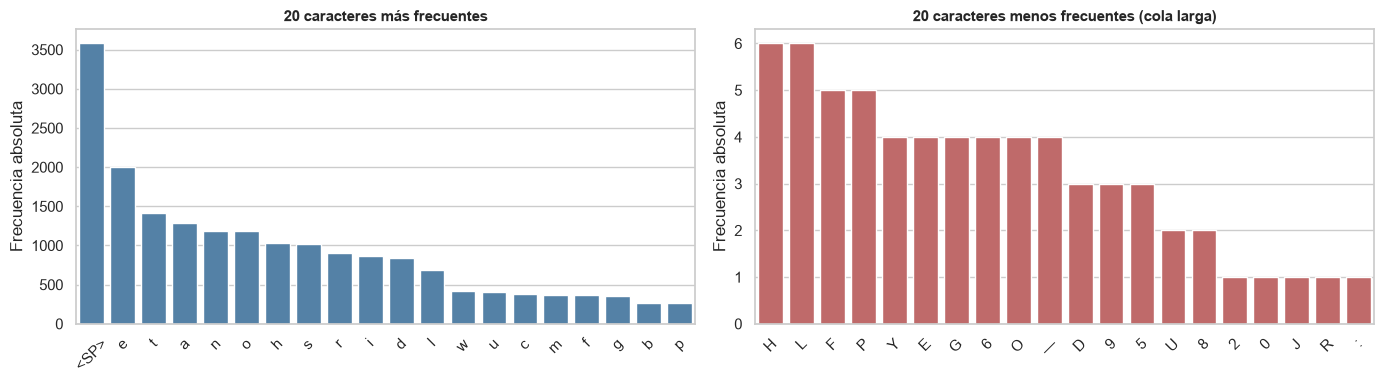

In [5]:
def vis(c):
    return {" ": "<SP>", "\n": "<NL>"}.get(str(c), str(c))

serie = pd.Series(char_counts).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

top20 = serie.head(20)
sns.barplot(x=[vis(c) for c in top20.index], y=top20.values, ax=axes[0], color="steelblue")
axes[0].set_title("20 caracteres más frecuentes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Frecuencia absoluta")
axes[0].tick_params(axis="x", rotation=45)

bottom20 = serie.tail(20)
sns.barplot(x=[vis(c) for c in bottom20.index], y=bottom20.values, ax=axes[1], color="indianred")
axes[1].set_title("20 caracteres menos frecuentes (cola larga)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Frecuencia absoluta")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### Gráfico 2: Distribución de longitud de palabras
Muestra cuán largas son las palabras que el modelo tiene que completar, un rasgo del estilo del texto.


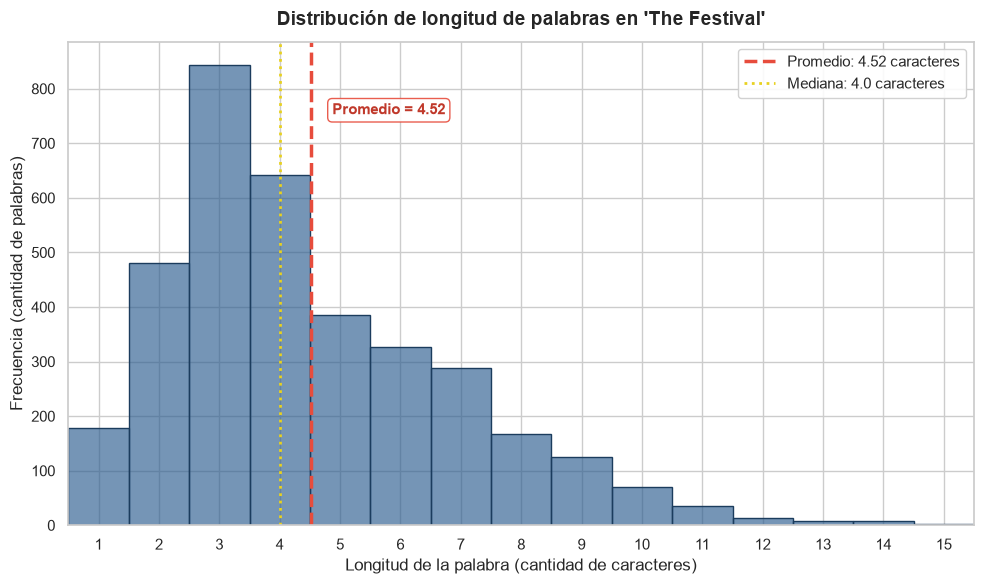

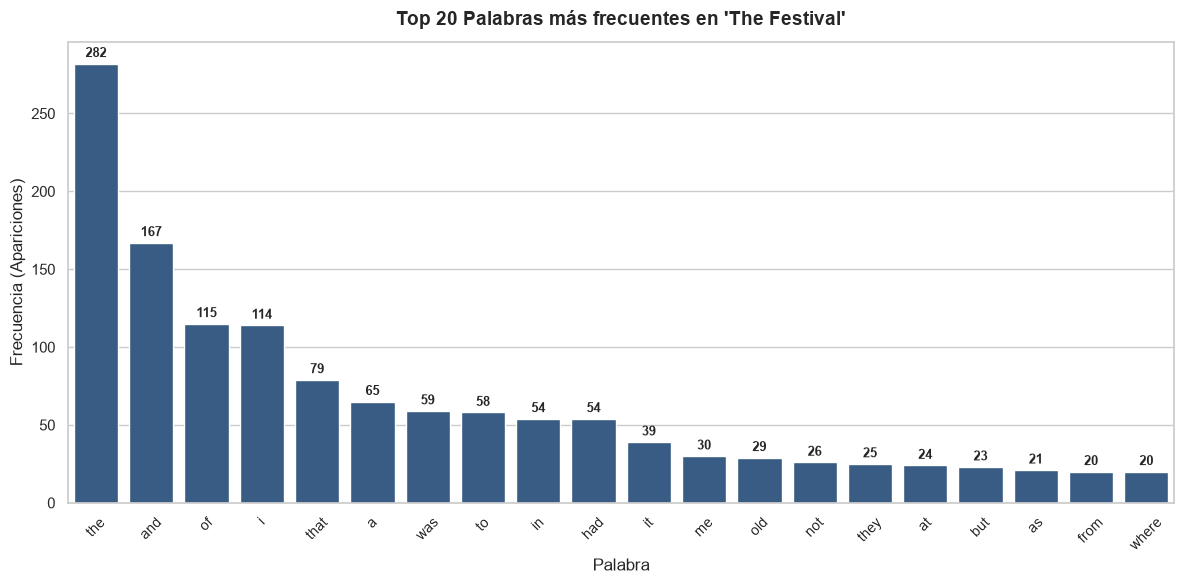

Palabras más largas del cuento: ['great-great-great-great-grandfather', 'phosphorescence', 'preternaturally', 'winter-whitened', 'night-marchers', 'spinning-wheel']


In [6]:
# 1. Distribución de longitud de palabras (promedio y mediana)
mean_val = float(np.mean(word_lengths))
median_val = float(np.median(word_lengths))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    word_lengths,
    discrete=True,
    color="#2b5c8f",
    edgecolor="#1b3c5d",
    alpha=0.65,
    kde=False,
)
ax.set_xticks(range(1, min(int(word_lengths.max()), 15) + 1))
ax.set_xlim(0.5, 15.5)
ax.axvline(
    mean_val,
    color="#e74c3c",
    linestyle="--",
    linewidth=2.5,
    label=f"Promedio: {mean_val:.2f} caracteres",
)
ax.axvline(
    median_val,
    color="#e8d120",
    linestyle=":",
    linewidth=2,
    label=f"Mediana: {median_val:.1f} caracteres",
)

y_max = ax.get_ylim()[1]
ax.text(
    mean_val + 0.35,
    y_max * 0.85,
    f"Promedio = {mean_val:.2f}",
    color="#c0392b",
    fontweight="bold",
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#e74c3c", alpha=0.9),
)

ax.set_title("Distribución de longitud de palabras en 'The Festival'", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Longitud de la palabra (cantidad de caracteres)", fontsize=12)
ax.set_ylabel("Frecuencia (cantidad de palabras)", fontsize=12)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()
plt.show()

# 2. Top 20 palabras más frecuentes
word_freq_counts = Counter(w.lower() for w in words)
common_words = word_freq_counts.most_common(20)
word_labels = [item[0] for item in common_words]
word_frequencies = [item[1] for item in common_words]

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.barplot(x=word_labels, y=word_frequencies, color="#2b5c8f")
ax.tick_params(axis="x", rotation=45, labelsize=10)

y_offset = max(word_frequencies) * 0.015
for i, freq in enumerate(word_frequencies):
    ax.text(i, freq + y_offset, str(freq), ha="center", fontsize=9, fontweight="bold")

ax.set_title("Top 20 Palabras más frecuentes en 'The Festival'", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Palabra", fontsize=12)
ax.set_ylabel("Frecuencia (Apariciones)", fontsize=12)

plt.tight_layout()
plt.show()

largas = sorted({w for w in words if len(w) >= 14}, key=len, reverse=True)
print("Palabras más largas del cuento:", largas[:6])

### Gráfico 3: Frecuencia de signos de puntuación
Muestra qué signos aparecen y cuánto, porque el modelo también tiene que predecirlos.


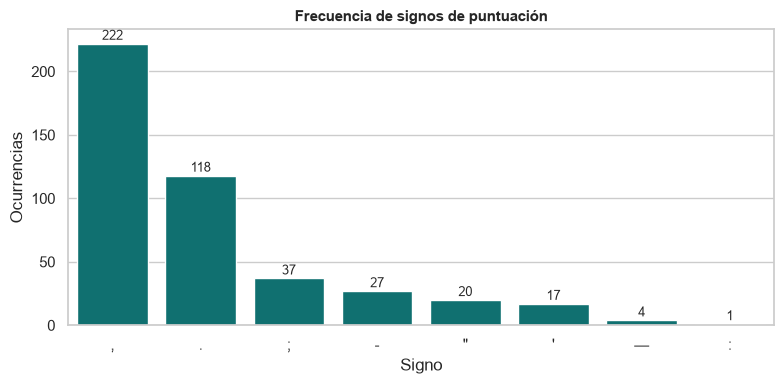

In [7]:
signos = set(".,;:!?'\"—-")
punct_counts = pd.Series([c for c in text if c in signos]).value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=list(punct_counts.index), y=list(punct_counts.values), color="teal")
for i, n in enumerate(punct_counts.values):
    plt.text(i, n + 3, str(n), ha="center", fontsize=9)
plt.title("Frecuencia de signos de puntuación", fontsize=11, fontweight="bold")
plt.xlabel("Signo")
plt.ylabel("Ocurrencias")
plt.tight_layout()
plt.show()


### Diagnóstico de problemas potenciales: desbalance, outliers y estabilidad (data mismatch)
Revisamos cuatro problemas posibles (consigna 4.1.1):
1. **Desbalance de clases:** el espacio y algunas vocales, como la `'e'`, dominan el texto; otros caracteres aparecen muy poco.
2. **Predominio de palabras cortas:** la longitud más frecuente es de **3 caracteres** (846 palabras), lo que se refleja también en el gráfico de frecuencia: **7 de las 20 palabras más repetidas** (*the, and, was, had, old, not, but*) tienen longitud 3, aumentando la frecuencia del espacio `' '` como cierre de palabra. 
3. **Clases raras (outliers):** caracteres con menos de 10 apariciones en todo el texto.
4. **Posible data mismatch:** comparamos la distribución de caracteres de la primera y la segunda mitad del cuento para ver si el estilo cambia.


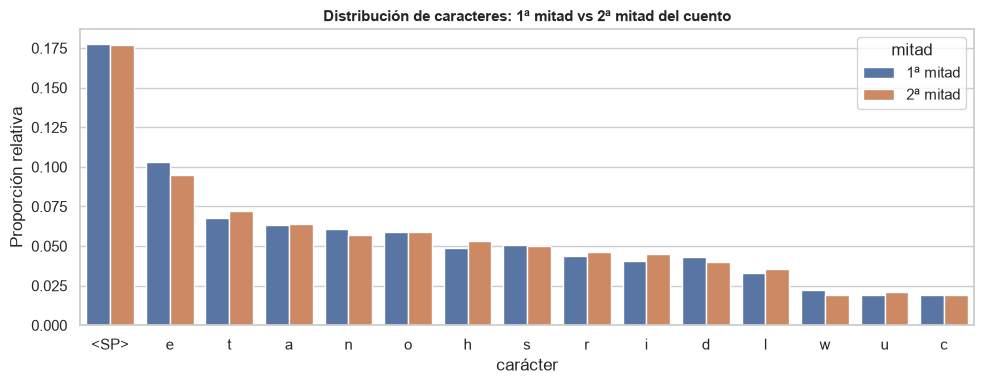

DIAGNÓSTICO DEL DATASET:
  • Desbalance: La clase mayoritaria '<SP>' representa el 17.7% del texto, mientras que ':' aparece solo 1 vez.
  • Longitud de palabras: La longitud modal es 3 caracteres (844 palabras) y 7/20 de las palabras más frecuentes tienen longitud 3.
  • Outliers / Clases raras: 28 de 64 caracteres tienen menos de 10 apariciones: ['0', '1', '2', '5', '6', '8', '9', ':', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'U', 'W', 'Y', 'j', '—']
  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.


In [ ]:
# Comparación de la 1ª mitad vs 2ª mitad del texto
mitad = len(text) // 2
c1, c2 = Counter(text[:mitad]), Counter(text[mitad:])
top15 = serie.index[:15]

df_mitades = pd.DataFrame({
    "carácter": [vis(c) for c in top15] * 2,
    "proporción": [c1[c] / mitad for c in top15] + [c2[c] / (len(text) - mitad) for c in top15],
    "mitad": ["1ª mitad"] * 15 + ["2ª mitad"] * 15
})

plt.figure(figsize=(10, 4))
sns.barplot(data=df_mitades, x="carácter", y="proporción", hue="mitad")
plt.title("Distribución de caracteres: 1ª mitad vs 2ª mitad del cuento", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

raros = [c for c, n in char_counts.items() if n < 10]
moda_len, moda_cnt = Counter(int(x) for x in word_lengths).most_common(1)[0]
len3_top20 = sum(1 for w, _ in Counter(w.lower() for w in words).most_common(20) if len(w) == moda_len)

print("DIAGNÓSTICO DEL DATASET:")
print(f"  • Desbalance: La clase mayoritaria '{vis(serie.index[0])}' representa el {serie.iloc[0]/len(text)*100:.1f}% del texto, mientras que '{vis(serie.index[-1])}' aparece solo {serie.iloc[-1]} vez.")
print(f"  • Longitud de palabras: La longitud modal es {moda_len} caracteres ({moda_cnt} palabras) y {len3_top20}/20 de las palabras más frecuentes tienen longitud {moda_len}.")
print(f"  • Outliers / Clases raras: {len(raros)} de {vocab_size} caracteres tienen menos de 10 apariciones: {sorted(vis(c) for c in raros)}")
print("  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.")

---
# 2. Consigna 4.1.2: Partición de datos (Train / Dev / Test)

## 2.1 Por qué partimos por bloques
Las ventanas se generan con paso de 1 carácter, así que dos ventanas vecinas comparten 39 de sus 40 caracteres. Si las repartiéramos al azar con `train_test_split`, Dev tendría ejemplos casi idénticos a los de Train (**fuga de datos**).

**Estrategia: bloques contiguos (70% Train / 15% Dev / 15% Test)**
1. Dividimos el texto en bloques de ~400 caracteres.
2. Asignamos cada bloque completo al azar a Train, Dev o Test, con semilla fija.
3. Generamos las ventanas solo dentro de cada bloque.

Así no hay solapamiento entre conjuntos y los tres cubren todo el relato.


In [9]:
# ==============================================================================
# PARTICIÓN POR BLOQUES CONTIGUOS (70% Train / 15% Dev / 15% Test)
# ==============================================================================
L = 40        # Longitud de la ventana de contexto
BLOQUE = 400  # Caracteres por bloque contiguo

limites = [(i, min(i + BLOQUE, len(text))) for i in range(0, len(text), BLOQUE)]
if limites[-1][1] - limites[-1][0] < BLOQUE // 2:
    ini_prev = limites[-2][0]
    limites = limites[:-2] + [(ini_prev, len(text))]

n_bloques = len(limites)
rng = np.random.default_rng(SEED)
orden = rng.permutation(n_bloques)

n_tr = round(0.70 * n_bloques)
n_dev = round(0.15 * n_bloques)

bloques_split = {
    "train": sorted(orden[:n_tr].tolist()),
    "dev":   sorted(orden[n_tr:n_tr + n_dev].tolist()),
    "test":  sorted(orden[n_tr + n_dev:].tolist()),
}

def ventanas_de_bloques(ids):
    X, y = [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
    return X, y

X_train, y_train = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev   = ventanas_de_bloques(bloques_split["dev"])
X_test,  y_test  = ventanas_de_bloques(bloques_split["test"])

n_total = len(X_train) + len(X_dev) + len(X_test)
print(f"Bloques totales: {n_bloques} (~{BLOQUE} caracteres c/u) -> Train: {len(bloques_split['train'])} | Dev: {len(bloques_split['dev'])} | Test: {len(bloques_split['test'])}")
print(f"  • Train: {len(X_train):>6,} muestras ({len(X_train)/n_total*100:4.1f}%)")
print(f"  • Dev:   {len(X_dev):>6,} muestras ({len(X_dev)/n_total*100:4.1f}%)")
print(f"  • Test:  {len(X_test):>6,} muestras ({len(X_test)/n_total*100:4.1f}%)")
print(f"\nEjemplo extraído:\n  Contexto X: {X_train[0]!r}\n  Objetivo y: {y_train[0]!r}")


Bloques totales: 50 (~400 caracteres c/u) -> Train: 35 | Dev: 8 | Test: 7
  • Train: 12,780 muestras (70.3%)
  • Dev:    2,880 muestras (15.8%)
  • Test:   2,520 muestras (13.9%)

Ejemplo extraído:
  Contexto X: 'e tongue of the blue-eyed fishers. And n'
  Objetivo y: 'o'


## 2.2 Verificación de la distribución de clases en los tres conjuntos
Comprobamos que las proporciones de los caracteres objetivo sean parecidas en Train, Dev y Test.


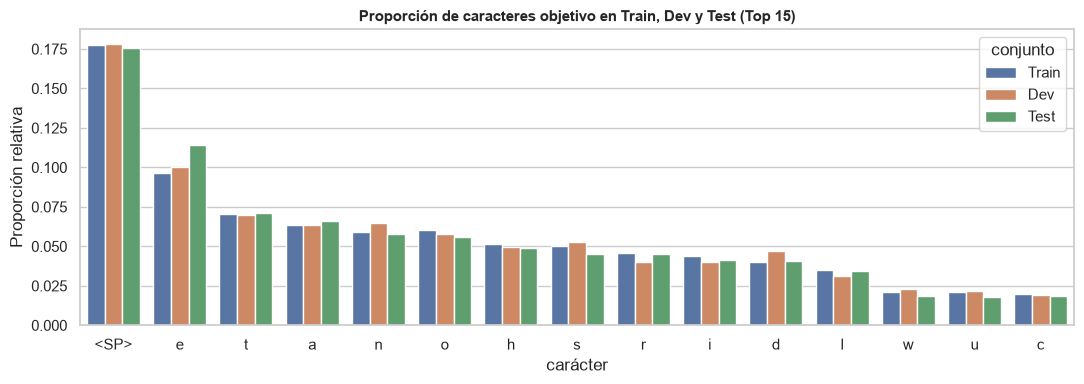

Caracteres en Dev/Test pero ausentes en Train: ['2']


In [10]:
conteos = {
    "Train": Counter(y_train),
    "Dev":   Counter(y_dev),
    "Test":  Counter(y_test),
}

freq = pd.DataFrame({s: pd.Series(c).reindex(vocabulary, fill_value=0) for s, c in conteos.items()})
prop = freq / freq.sum()

top15 = serie.index[:15]
df_p = prop.loc[top15].reset_index(names="carácter").melt(id_vars="carácter", var_name="conjunto", value_name="proporción")
df_p["carácter"] = df_p["carácter"].map(vis)

plt.figure(figsize=(11, 4))
sns.barplot(data=df_p, x="carácter", y="proporción", hue="conjunto")
plt.title("Proporción de caracteres objetivo en Train, Dev y Test (Top 15)", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

sin_train = [vis(c) for c in vocabulary if freq.loc[c, "Train"] == 0 and (freq.loc[c, "Dev"] + freq.loc[c, "Test"]) > 0]
print(f"Caracteres en Dev/Test pero ausentes en Train: {sin_train}")


---
# 3. Consigna 4.1.3: Preprocesamiento y modelo baseline

## 3.1 Codificación numérica y persistencia de particiones
Definimos el mapeo entre caracteres y enteros (`char2idx` e `idx2char`) y guardamos el texto limpio y las particiones en `data/processed/`, para que todas las etapas usen exactamente los mismos datos.


In [11]:
# ==============================================================================
# CODIFICACIÓN NUMÉRICA Y PERSISTENCIA
# ==============================================================================
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
V = len(vocabulary)

OUT_DIR = BASE_DIR / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

(OUT_DIR / "The_Festival_clean.txt").write_text(text, encoding="utf-8")
with open(OUT_DIR / "splits_bloques.json", "w", encoding="utf-8") as f:
    json.dump({
        "L": L,
        "BLOQUE": BLOQUE,
        "SEED": SEED,
        "limites_bloques": limites,
        "bloques": bloques_split,
        "vocabulario": "".join(vocabulary)
    }, f, ensure_ascii=False)

print(f"Vocabulario (|V| = {V}) y particiones guardados exitosamente en {OUT_DIR.relative_to(BASE_DIR)}/")


Vocabulario (|V| = 64) y particiones guardados exitosamente en data\processed/


## 3.2 Métrica de número único
**Métrica elegida: accuracy top-1 en Dev** (proporción de caracteres acertados).

- **Por qué:** es fácil de interpretar y se compara directamente con la referencia trivial de predecir siempre el carácter más frecuente (el espacio).
- Es el número que tienen que superar los modelos de las etapas siguientes.


In [12]:
# ==============================================================================
# REFERENCIA TRIVIAL: PREDICCIÓN DE LA CLASE MAYORITARIA
# ==============================================================================
clase_mayoritaria = serie.index[0]
acc_dummy_dev = np.mean([y == clase_mayoritaria for y in y_dev])

print(f"Clase mayoritaria en el texto: '{vis(clase_mayoritaria)}'")
print(f"Accuracy de referencia trivial en Dev: {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")


Clase mayoritaria en el texto: '<SP>'
Accuracy de referencia trivial en Dev: 0.1785 (17.85%)


## 3.3 Baseline: regresión logística sobre los últimos $K$ caracteres
Los caracteres justo anteriores son los que más informan sobre el siguiente, así que el baseline usa solo esos:
1. Tomamos los últimos $K$ caracteres de la ventana.
2. Los codificamos con `OneHotEncoder`.
3. Entrenamos una `LogisticRegression` multinomial (equivale a una red de una sola capa densa con softmax).

Probamos $K \in \{1, 3, 5\}$ y elegimos el mejor según Dev.


   Accuracy Train  Accuracy Dev  Tiempo (s)
K                                          
1          0.3005        0.3122      1.1965
3          0.4026        0.4069      1.6221
5          0.4297        0.4083      1.9188

Mejor K seleccionado con Dev: K = 5


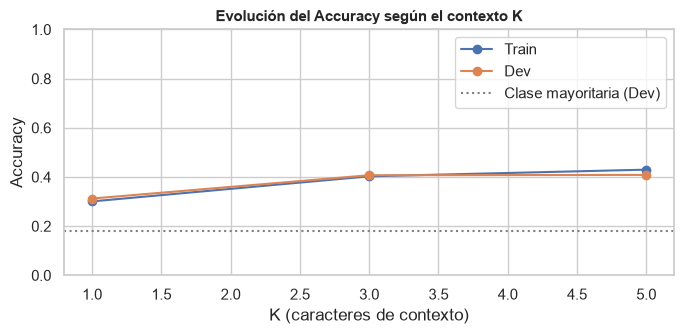

In [13]:
# ==============================================================================
# ENTRENAMIENTO DEL BASELINE CON VARIACIÓN DE CONTEXTO K
# ==============================================================================
def ultimos(X, k):
    return np.array([list(x[-k:]) for x in X])

resultados_k = []
modelos_k = {}
tiempos_k = {}

for k in [1, 3, 5]:
    pipe = Pipeline([
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ("clf", LogisticRegression(max_iter=500, random_state=SEED)),
    ])
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(ultimos(X_train, k), y_train)
    tiempos_k[k] = time.perf_counter() - t0
    
    modelos_k[k] = pipe
    acc_tr = accuracy_score(y_train, pipe.predict(ultimos(X_train, k)))
    acc_dev = accuracy_score(y_dev, pipe.predict(ultimos(X_dev, k)))
    resultados_k.append({"K": k, "Accuracy Train": acc_tr, "Accuracy Dev": acc_dev, "Tiempo (s)": tiempos_k[k]})

df_k = pd.DataFrame(resultados_k).set_index("K")
print(df_k.round(4))

K_OPTIMO = int(df_k["Accuracy Dev"].idxmax())
print(f"\nMejor K seleccionado con Dev: K = {K_OPTIMO}")

plt.figure(figsize=(7, 3.5))
plt.plot(df_k.index, df_k["Accuracy Train"], marker="o", label="Train")
plt.plot(df_k.index, df_k["Accuracy Dev"], marker="o", label="Dev")
plt.axhline(acc_dummy_dev, color="gray", linestyle=":", label="Clase mayoritaria (Dev)")
plt.xlabel("K (caracteres de contexto)")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Evolución del Accuracy según el contexto K", fontsize=11, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

## 3.4 Resultado del baseline en Dev
Reportamos el resultado del baseline en Dev (consigna 4.1.3): es la referencia que tienen que superar los modelos de las etapas siguientes. También medimos la accuracy en Train, la pérdida, la perplejidad, los parámetros y el tiempo de entrenamiento, que se usan en la Etapa 2 y en la tabla final de la Etapa 5.


In [14]:
# ==============================================================================
# REPORTE OFICIAL DEL BASELINE EN DEV (Consigna 4.1.3)
# ==============================================================================
baseline_final = modelos_k[K_OPTIMO]
Xdev_opt = ultimos(X_dev, K_OPTIMO)
y_pred_dev = baseline_final.predict(Xdev_opt)

acc_base_dev = accuracy_score(y_dev, y_pred_dev)

# Métricas complementarias, medidas aquí para no fijarlas a mano en etapas posteriores
acc_base_train = accuracy_score(y_train, baseline_final.predict(ultimos(X_train, K_OPTIMO)))

def perdida_log(pipe, X_k, y_real):
    """Entropía cruzada media. Si un carácter real no está entre las clases del modelo, recibe probabilidad 1e-15."""
    proba = pipe.predict_proba(X_k)
    col = {c: j for j, c in enumerate(pipe.classes_)}
    p_real = np.array([proba[i, col[c]] if c in col else 1e-15 for i, c in enumerate(y_real)])
    return float(-np.mean(np.log(np.clip(p_real, 1e-15, 1.0))))

loss_base_dev = perdida_log(baseline_final, Xdev_opt, y_dev)
perp_base_dev = float(np.exp(loss_base_dev))
clf_base = baseline_final.named_steps["clf"]
params_base = int(clf_base.coef_.size + clf_base.intercept_.size)
tiempo_base = tiempos_k[K_OPTIMO]

print("=" * 70)
print(f"BASELINE OFICIAL — One-Hot últimos {K_OPTIMO} caracteres + Regresión Logística:")
print(f"  • Accuracy en Dev: {acc_base_dev:.4f} ({acc_base_dev*100:.2f}%)")
print(f"  • Referencia trivial (clase mayoritaria): {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")
print(f"  • Ganancia sobre la referencia trivial: +{(acc_base_dev - acc_dummy_dev)*100:.2f} puntos porcentuales")
print(f"  • Muestras evaluadas en Dev: {len(y_dev)}")
print(f"  • Accuracy en Train: {acc_base_train*100:.2f}% (brecha Train - Dev: {(acc_base_train - acc_base_dev)*100:.2f} pp)")
print(f"  • Pérdida (entropía cruzada) en Dev: {loss_base_dev:.4f} | Perplejidad en Dev: {perp_base_dev:.2f}")
print(f"  • Parámetros entrenables: {params_base:,} | Tiempo de entrenamiento: {tiempo_base:.2f} s")
print("=" * 70)

# Guardar en disco para referencia futura en Etapa 2 y 5
with open(OUT_DIR / "baseline_dev.json", "w", encoding="utf-8") as f:
    json.dump({
        "modelo": f"OneHot_ultimos_{K_OPTIMO}_chars + LogisticRegression",
        "K": K_OPTIMO,
        "metrica_principal": "accuracy_dev",
        "accuracy_dev": float(acc_base_dev),
        "accuracy_train": float(acc_base_train),
        "loss_dev": loss_base_dev,
        "perplejidad_dev": perp_base_dev,
        "parametros_entrenables": params_base,
        "tiempo_entrenamiento_s": tiempo_base,
        "accuracy_dummy_dev": float(acc_dummy_dev),
        "n_dev": len(y_dev)
    }, f, indent=2)
print("Métrica oficial guardada en data/processed/baseline_dev.json")


BASELINE OFICIAL — One-Hot últimos 5 caracteres + Regresión Logística:
  • Accuracy en Dev: 0.4083 (40.83%)
  • Referencia trivial (clase mayoritaria): 0.1785 (17.85%)
  • Ganancia sobre la referencia trivial: +22.99 puntos porcentuales
  • Muestras evaluadas en Dev: 2880
  • Accuracy en Train: 42.97% (brecha Train - Dev: 2.13 pp)
  • Pérdida (entropía cruzada) en Dev: 2.0853 | Perplejidad en Dev: 8.05
  • Parámetros entrenables: 19,908 | Tiempo de entrenamiento: 1.92 s
Métrica oficial guardada en data/processed/baseline_dev.json


## 3.5 Matriz de confusión del baseline
Miramos la matriz de confusión normalizada de los 20 caracteres más frecuentes para ver con qué se confunde el modelo.


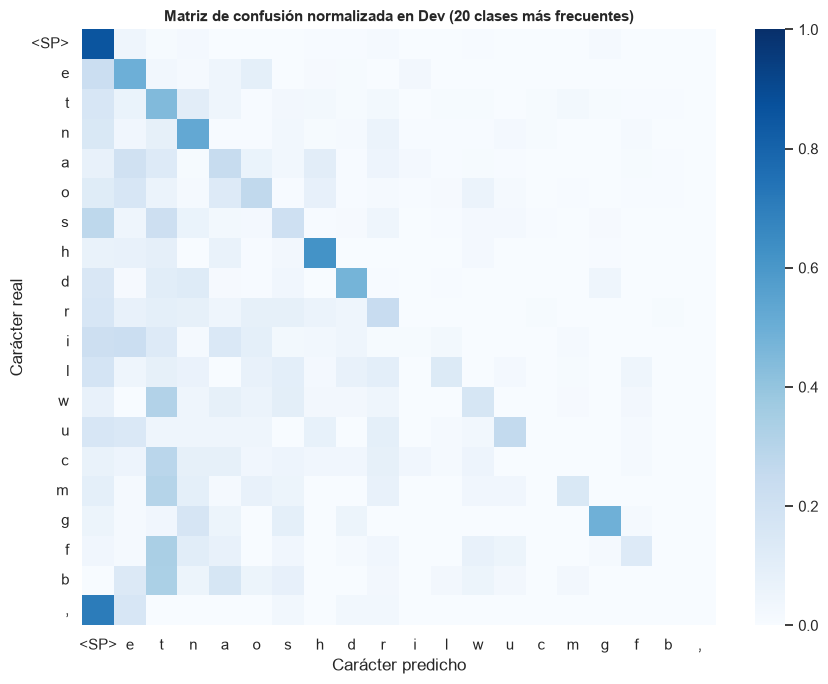

Total de errores en Dev: 1704 de 2880

Pares de caracteres más confundidos (real -> predicho):
Real Predicho  Ocurrencias
   e     <SP>           65
   s     <SP>           42
   a        e           37
   t     <SP>           33
   s        t           33
   n     <SP>           28
   e        o           28
   o        e           27


In [15]:
# ==============================================================================
# MATRIZ DE CONFUSIÓN Y ANÁLISIS DE ERRORES EN DEV
# ==============================================================================
labels_all = sorted(set(y_dev) | set(y_pred_dev))
cm = confusion_matrix(y_dev, y_pred_dev, labels=labels_all, normalize="true")

top20 = [c for c, _ in Counter(y_dev).most_common(20)]
ix = [labels_all.index(c) for c in top20]

plt.figure(figsize=(9, 7))
sns.heatmap(cm[np.ix_(ix, ix)], cmap="Blues", vmin=0, vmax=1,
            xticklabels=[vis(c) for c in top20], yticklabels=[vis(c) for c in top20])
plt.title("Matriz de confusión normalizada en Dev (20 clases más frecuentes)", fontsize=11, fontweight="bold")
plt.xlabel("Carácter predicho")
plt.ylabel("Carácter real")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

errores = [(r, p) for r, p in zip(y_dev, y_pred_dev) if r != p]
top_errores = Counter(errores).most_common(8)
print(f"Total de errores en Dev: {len(errores)} de {len(y_dev)}")
print("\nPares de caracteres más confundidos (real -> predicho):")
df_err = pd.DataFrame([(vis(r), vis(p), n) for (r, p), n in top_errores], columns=["Real", "Predicho", "Ocurrencias"])
print(df_err.to_string(index=False))


---
# 4. Síntesis y checklist de la Etapa 1
Estado de cada requisito de la consigna.


In [16]:
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 1")
print(f"  [x] 4.1.1 Carga y EDA: {len(text):,} caracteres, |V| = {vocab_size}, 3 gráficos descriptivos y diagnóstico de problemas.")
print(f"  [x] 4.1.2 Partición: Train ({len(X_train):,}) / Dev ({len(X_dev):,}) / Test ({len(X_test):,}) mediante bloques contiguos sin data leakage.")
print("  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.")
print(f"  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos {K_OPTIMO} caracteres + Regresión Logística multinomial.")
print(f"  [x] 4.1.3 Métrica de número único: Accuracy en Dev = {acc_base_dev:.4f} (referencia trivial = {acc_dummy_dev:.4f}).")
print("  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.")
print("  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.")


CHECKLIST DE CUMPLIMIENTO - ETAPA 1
  [x] 4.1.1 Carga y EDA: 20,180 caracteres, |V| = 64, 3 gráficos descriptivos y diagnóstico de problemas.
  [x] 4.1.2 Partición: Train (12,780) / Dev (2,880) / Test (2,520) mediante bloques contiguos sin data leakage.
  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.
  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos 5 caracteres + Regresión Logística multinomial.
  [x] 4.1.3 Métrica de número único: Accuracy en Dev = 0.4083 (referencia trivial = 0.1785).
  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.
  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.


---
---
# ETAPA 2: Análisis de errores, MLP y regularización

---
# 5. Etapa 2: Red neuronal multicapa (MLP) y regularización

En esta etapa analizamos los errores del baseline, entrenamos un MLP para reducir su sesgo y aplicamos regularización para controlar el sobreajuste que aparece.

### Decisiones de la Etapa 2
1. **Misma entrada que el baseline ($K = 5$, 320 valores one-hot):** así la diferencia de rendimiento se debe principalmente a la red y no a tener más información.
2. **TensorFlow / Keras (`tf.keras`)** para todos los modelos neuronales del TP.
3. **5 semillas fijas** (`SEEDS = [42, 123, 456, 789, 2026]`): con 2.880 muestras en Dev, el margen de error de una medición es de unos $\pm 1,8$ pp, así que una sola corrida no alcanza para comparar modelos. Reportamos media ± desvío.
4. **Errores clasificados con reglas fijas:** para que la asignación de causas sea reproducible y no dependa de quién mira el caso.
5. **Grilla + ablación:** elegimos los hiperparámetros con una grilla en Dev y entrenamos cada técnica por separado y combinada, para saber cuánto aporta cada una.
6. **Test intacto** hasta la Etapa 5.


In [17]:
# ==============================================================================
# 5.1 CONFIGURACIÓN DE TENSORFLOW/KERAS Y PREPARACIÓN DE TENSORES
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Ocultar mensajes de bajo nivel de C++

import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")

# Semillas fijas para la evaluación multi-semilla
SEEDS = [42, 123, 456, 789, 2026]

# ------------------------------------------------------------------------------
# Transformación a tensores densos One-Hot aplanados (N, K * |V|) = (N, 320)
# Cada posición se codifica en un vector binario de dimensión |V| = 64
# ------------------------------------------------------------------------------
def extraer_tensores_onehot(X_raw, y_raw, k, c2i, v_size):
    # Índice de cada uno de los últimos k caracteres: (N, k)
    indices = np.array([[c2i[c] for c in seq[-k:]] for seq in X_raw])
    # One-hot de cada posición (N, k, |V|), aplanado a (N, k * |V|)
    X_oh = keras.utils.to_categorical(indices, num_classes=v_size).reshape(len(X_raw), -1).astype("float32")
    y_idx = np.array([c2i[c] for c in y_raw], dtype=np.int32)
    return X_oh, y_idx

X_train_oh, y_train_idx = extraer_tensores_onehot(X_train, y_train, K_OPTIMO, char2idx, vocab_size)
X_dev_oh, y_dev_idx     = extraer_tensores_onehot(X_dev, y_dev, K_OPTIMO, char2idx, vocab_size)

print("\nDimensiones de los tensores generados para Keras:")
print(f"  • X_train_oh: {X_train_oh.shape}  | y_train_idx: {y_train_idx.shape}")
print(f"  • X_dev_oh:   {X_dev_oh.shape}   | y_dev_idx:   {y_dev_idx.shape}")
print(f"  • Features por muestra: {X_train_oh.shape[1]} ({K_OPTIMO} caracteres * {vocab_size} clases)")


TensorFlow Version: 2.21.0
Keras Version:      3.15.1

Dimensiones de los tensores generados para Keras:
  • X_train_oh: (12780, 320)  | y_train_idx: (12780,)
  • X_dev_oh:   (2880, 320)   | y_dev_idx:   (2880,)
  • Features por muestra: 320 (5 caracteres * 64 clases)


---
# 6. Consigna 4.2.1: Análisis manual de errores del baseline

Separamos los errores según su causa que se corrige con una acción distinta:
- **Ruido irreducible:** con 5 caracteres de contexto a veces hay varias continuaciones válidas (por ejemplo, después de `"the "`). Ningún modelo con ese contexto las acierta siempre.
- **Sesgo (underfitting):** el modelo no aprende patrones que están en los datos. Se corrige con un modelo más expresivo.
- **Varianza (overfitting):** el modelo aprende detalles de Train que no se repiten en Dev. Se corrige con más datos o con regularización.
- **Data mismatch:** Train y Dev vienen de distribuciones distintas. En la Etapa 1 la distribución de caracteres es estable entre las dos mitades del cuento y las proporciones son parecidas en los tres conjuntos (solo el carácter `2` aparece en Dev/Test y no en Train), así que no esperamos errores de este tipo.

### Reglas para asignar la causa (en orden de precedencia)
Para cada error de Dev miramos su contexto de 5 caracteres y aplicamos la primera regla que se cumpla:
1. **Falta de cobertura:** el contexto nunca aparece en Train. El modelo no vio esa combinación.
2. **Ruido irreducible:** el contexto aparece en Train seguido de varios caracteres distintos y el real no es el más frecuente. Incluso eligiendo siempre el más frecuente se fallaría.
3. **Sesgo:** el contexto aparece en Train y el baseline también falla ahí la mayoría de las veces (acierto $\le 50\%$). Tiene datos, pero no aprendió el patrón.
4. **Varianza:** el contexto aparece en Train y el baseline acierta ahí (acierto $> 50\%$), pero falla en Dev.

Además registramos el tipo de error (espacio, vocales, mayúsculas, etc.) en una columna aparte.


Total de errores del baseline en Dev: 1704 de 2880 (Tasa de error = 59.17%)


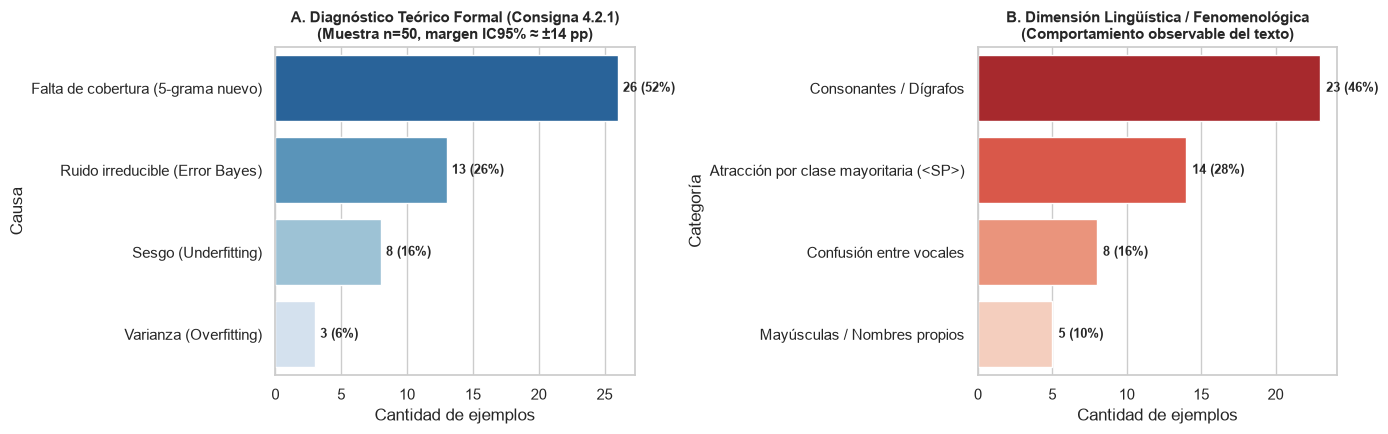

,Contexto (5 chars),Target Real,Pred. Baseline,Causa Teórica (ML),Categoría Lingüística
1046,g. Af,t,<SP>,Falta de cobertura (5-grama nuevo),Atracción por clase mayoritaria (<SP>)
745,and,a,t,Ruido irreducible (Error Bayes),Consonantes / Dígrafos
785,ied.,H,T,Falta de cobertura (5-grama nuevo),Mayúsculas / Nombres propios
367,old,P,m,Ruido irreducible (Error Bayes),Mayúsculas / Nombres propios
1029,e age,d,<SP>,Falta de cobertura (5-grama nuevo),Atracción por clase mayoritaria (<SP>)
1648,a na,s,t,Sesgo (Underfitting),Consonantes / Dígrafos
259,"692,",b,t,Falta de cobertura (5-grama nuevo),Consonantes / Dígrafos
1509,e I c,o,a,Sesgo (Underfitting),Confusión entre vocales
514,in m,e,a,Falta de cobertura (5-grama nuevo),Confusión entre vocales
1229,that,c,<SP>,Ruido irreducible (Error Bayes),Atracción por clase mayoritaria (<SP>)


In [18]:
# ==============================================================================
# 6.1 ANÁLISIS DE ERRORES DETERMINÍSTICO Y MUESTREO DE 50 CASOS (Consigna 4.2.1)
# ==============================================================================
# Predicciones del Baseline K=5 en Train y Dev
best_pipe = modelos_k[K_OPTIMO]
y_pred_tr_base  = best_pipe.predict(ultimos(X_train, K_OPTIMO))
y_pred_dev_base = best_pipe.predict(ultimos(X_dev, K_OPTIMO))

ctx_train_k = ["".join(x) for x in ultimos(X_train, K_OPTIMO)]
ctx_dev_k   = ["".join(x) for x in ultimos(X_dev, K_OPTIMO)]

from collections import defaultdict
ctx_train_stats = defaultdict(list)
for ctx, yr, yp in zip(ctx_train_k, y_train, y_pred_tr_base):
    ctx_train_stats[ctx].append((yr, yp))

# Filtrar todos los errores en Dev
errores_dev = []
for idx, (ctx, yr, yp) in enumerate(zip(ctx_dev_k, y_dev, y_pred_dev_base)):
    if yr != yp:
        errores_dev.append({
            "dev_idx": idx,
            "contexto": ctx,
            "y_real": yr,
            "y_pred": yp
        })

print(f"Total de errores del baseline en Dev: {len(errores_dev)} de {len(y_dev)} (Tasa de error = {len(errores_dev)/len(y_dev)*100:.2f}%)")

# Funciones de clasificación con orden de precedencia documentado
def clasificar_causa_teorica(ctx, yr, yp):
    if ctx not in ctx_train_stats:
        return "Falta de cobertura (5-grama nuevo)"
    ocurr = ctx_train_stats[ctx]
    targets = [t[0] for t in ocurr]
    conteo = Counter(targets)
    moda = conteo.most_common(1)[0][0]
    if len(conteo) > 1 and yr != moda:
        return "Ruido irreducible (Error Bayes)"
    aciertos = sum(1 for t, p in ocurr if t == p)
    if (aciertos / len(ocurr)) <= 0.5:
        return "Sesgo (Underfitting)"
    return "Varianza (Overfitting)"

def clasificar_fenomeno_linguistico(yr, yp):
    if yp == ' ':
        return "Atracción por clase mayoritaria (<SP>)"
    if yr == ' ':
        return "Fin de palabra no detectado (omisión <SP>)"
    if yr.lower() in "aeiou" and yp.lower() in "aeiou":
        return "Confusión entre vocales"
    if yr.isupper() or yp.isupper():
        return "Mayúsculas / Nombres propios"
    if yr in ".-,;:!?'\"—" or yp in ".-,;:!?'\"—":
        return "Puntuación / Delimitadores"
    return "Consonantes / Dígrafos"

for e in errores_dev:
    e["causa_teorica"] = clasificar_causa_teorica(e["contexto"], e["y_real"], e["y_pred"])
    e["categoria_ling"] = clasificar_fenomeno_linguistico(e["y_real"], e["y_pred"])

df_errores_all = pd.DataFrame(errores_dev)

# Muestra aleatoria de 50 errores con semilla fija
df_50_muestra = df_errores_all.sample(n=50, random_state=SEED).copy()
ruta_50 = OUT_DIR / "muestra_50_errores_dev.csv"
# Conservamos la revisión manual del grupo (columna causa_manual) si el archivo ya existe
df_50_muestra["causa_manual"] = ""
if os.path.exists(ruta_50):
    previo = pd.read_csv(ruta_50, encoding="utf-8", dtype={"causa_manual": str})
    if "causa_manual" in previo.columns:
        df_50_muestra["causa_manual"] = df_50_muestra["dev_idx"].map(previo.set_index("dev_idx")["causa_manual"]).fillna("")
df_50_muestra.to_csv(ruta_50, index=False, encoding="utf-8")

# Visualización de los 50 errores clasificados
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

causas_cnt = df_50_muestra["causa_teorica"].value_counts().reset_index()
causas_cnt.columns = ["Causa", "Casos"]
sns.barplot(data=causas_cnt, x="Casos", y="Causa", hue="Causa", legend=False, ax=axes[0], palette="Blues_r")
axes[0].set_title("A. Diagnóstico Teórico Formal (Consigna 4.2.1)\n(Muestra n=50, margen IC95% ≈ ±14 pp)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Cantidad de ejemplos")
for i, v in enumerate(causas_cnt["Casos"]):
    axes[0].text(v + 0.4, i, f"{v} ({v*2}%)", va="center", fontsize=9, fontweight="bold")

ling_cnt = df_50_muestra["categoria_ling"].value_counts().reset_index()
ling_cnt.columns = ["Categoría", "Casos"]
sns.barplot(data=ling_cnt, x="Casos", y="Categoría", hue="Categoría", legend=False, ax=axes[1], palette="Reds_r")
axes[1].set_title("B. Dimensión Lingüística / Fenomenológica\n(Comportamiento observable del texto)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Cantidad de ejemplos")
for i, v in enumerate(ling_cnt["Casos"]):
    axes[1].text(v + 0.4, i, f"{v} ({v*2}%)", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# Mostrar primeros 10 casos en tabla formateada
def vis_c(c): return "<SP>" if c == " " else str(c)
df_disp = df_50_muestra[["contexto", "y_real", "y_pred", "causa_teorica", "categoria_ling"]].head(10).copy()
df_disp["y_real"] = df_disp["y_real"].map(vis_c)
df_disp["y_pred"] = df_disp["y_pred"].map(vis_c)
df_disp.columns = ["Contexto (5 chars)", "Target Real", "Pred. Baseline", "Causa Teórica (ML)", "Categoría Lingüística"]
df_disp


### 6.1.1 Qué muestran los 50 errores

| Causa asignada por reglas | Casos | % | Categoría de la consigna | Qué la corregiría |
|---|---|---|---|---|
| Falta de cobertura (5-grama nuevo) | 26 | 52 % | Sesgo y varianza mezclados (ver abajo) | un modelo que combine posiciones (MLP) o más datos |
| Ruido irreducible | 13 | 26 % | Ninguna: error irreducible con 5 caracteres de contexto | solo más contexto |
| Sesgo | 8 | 16 % | Sesgo | un modelo más expresivo (MLP) |
| Varianza | 3 | 6 % | Varianza | más datos o regularización |
| Data mismatch | 0 | 0 % | Data mismatch | — |

Con 50 casos el margen es de $\pm 14$ pp, así que los porcentajes son orientativos.

- **La mitad de los errores son 5-gramas que no aparecen en Train.** Esta categoría no es una de las tres de la consigna porque mezcla dos causas: faltan datos (varianza, que según Ng se corrige con más datos) y el modelo lineal no aprovecha contextos parecidos, porque suma el aporte de cada posición por separado (sesgo). La sección 8.4 muestra que buena parte es sesgo: en `g. Af` → `t`, el baseline apuesta al espacio ($0,503$) y el MLP acierta con $0,922$, con los mismos datos.
- **Cobertura y sesgo suman el 68 % y apuntan a la misma acción: un modelo no lineal.** Es coherente con el diagnóstico global de la sección 6.2: error de Train de $57,03\%$ y brecha de $2,13$ pp.
- **La varianza pura es rara (3 casos):** contextos para los que Train vio una sola continuación y Dev trae otra. Es lo esperable en un modelo lineal con una brecha de $2,13$ pp.
- **Un cuarto de los errores es ruido irreducible:** contextos como `" and "`, que admiten muchas continuaciones. Ningún modelo con 5 caracteres los resuelve siempre; solo un contexto más largo podría reducirlos, y eso lo probamos en la Etapa 3.
- **Data mismatch: 0 casos**, como anticipaba la Etapa 1 (frecuencias estables entre las dos mitades del cuento).
- **Por tipo de carácter** (gráfico B): consonantes 23, atracción al espacio 14, confusión entre vocales 8 y mayúsculas 5.

**Revisión manual.** Las causas se asignan con reglas para que la clasificación sea reproducible. Después clasificamos a mano los 50 errores con las categorías de la consigna (columna `causa_manual` de `data/processed/muestra_50_errores_dev.csv`): ruido irreducible 24 (48 %), sesgo 22 (44 %), varianza 4 (8 %) y *data mismatch* 0.
- De los 26 casos de falta de cobertura, 17 son sesgo, 8 ruido irreducible y 1 varianza: esa categoría es sobre todo sesgo.
- En los 24 casos que las reglas ubican en una categoría de la consigna, coincidimos en 14 (58 %). Los 3 de varianza y 3 de sesgo resultan ruido irreducible al mirarlos (`ust w` → `h` puede ser *was*, *with* o *which*).
- El diagnóstico no cambia: el sesgo es la causa corregible principal, y casi la mitad de los errores no se puede evitar con 5 caracteres de contexto.

### 6.2 Diagnóstico de sesgo y varianza del baseline

| Conjunto | Accuracy | Error |
|---|---|---|
| Train | $42,97\%$ | $57,03\%$ |
| Dev | $40,83\%$ | $59,17\%$ |

La brecha Train–Dev es chica ($2,13$ pp), pero el error es alto en los dos conjuntos: el baseline tiene **sesgo alto (underfitting)**, no sobreajuste. Un modelo lineal sobre one-hot no puede capturar interacciones entre las posiciones del contexto.

**Acción:** pasar a un MLP, que sí puede capturarlas. Como tiene $53.536$ parámetros para $12.780$ muestras, esperamos que aparezca **varianza**, y por eso en la sección 8 agregamos regularización.

**Cuánto sesgo se puede corregir:** lo estimamos en la sección 8.5 con los MLP ya entrenados. No usamos el MLP sin regularizar como referencia porque memoriza Train: su error de Train puede quedar por debajo del mínimo posible y exagerar la estimación.


### 6.3 Accuracy por tipo de carácter
Separamos la accuracy según el tipo del carácter real: **espacio**, **vocal** minúscula, **consonante** minúscula, **mayúscula** y **puntuación/dígito**. Así vemos dónde se concentran los errores del baseline y, en la sección 8.4, dónde mejora el MLP.


In [19]:
# ==============================================================================
# 6.3 ACCURACY POR TIPO DE CARÁCTER EN DEV
# ==============================================================================
TIPOS_CHAR = ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"]

def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

tipos_dev = np.array([tipo_caracter(c) for c in y_dev])

def accuracy_por_tipo(y_pred, y_real=y_dev, tipos=tipos_dev):
    """Accuracy separada por tipo de carácter real, más la accuracy global."""
    y_pred, y_real = np.asarray(y_pred), np.asarray(y_real)
    res = {t: (y_pred[tipos == t] == y_real[tipos == t]).mean() for t in TIPOS_CHAR}
    res["global"] = (y_pred == y_real).mean()
    return res

soporte_tipos = pd.Series(tipos_dev).value_counts().reindex(TIPOS_CHAR)
df_tipos_base = pd.DataFrame({
    "Casos en Dev": soporte_tipos,
    "% de Dev": (soporte_tipos / len(y_dev) * 100).round(1),
    "Accuracy Baseline": pd.Series(accuracy_por_tipo(y_pred_dev_base)).reindex(TIPOS_CHAR).round(4),
})
df_tipos_base


,Casos en Dev,% de Dev,Accuracy Baseline
espacio,514,17.8,0.8580
vocal,817,28.4,0.3060
consonante,1451,50.4,0.3280
mayúscula,38,1.3,0.1842
puntuación/dígito,60,2.1,0.0333


**Interpretación.** El baseline acierta el $85,8\%$ de los espacios, pero solo el $30,6\%$ de las vocales y el $32,8\%$ de las consonantes, que juntas son el $78,8\%$ de Dev. Lo difícil no es saber cuándo termina una palabra sino elegir la letra dentro de ella, y ahí es donde tiene que mejorar el MLP. Parte del acierto en espacios se explica porque el baseline tiende a predecirlos: en 14 de los 50 errores de la muestra predijo un espacio que no correspondía. En mayúsculas ($18,4\%$) y puntuación/dígitos ($3,3\%$) casi no acierta, pero son pocos casos (38 y 60).


### 6.4 Explicación de predicciones individuales
La función `explicar_prediccion` muestra los 5 caracteres más probables para un contexto y en qué puesto quedó el real. La aplicamos a un error de cada causa. Sirve para distinguir causas: si el real queda 2.º con una probabilidad parecida a la del 1.º, apunta a ruido irreducible; si tiene probabilidad casi nula, el modelo no aprendió el patrón.


In [20]:
# ==============================================================================
# 6.4 EXPLICACIÓN DE PREDICCIONES
# ==============================================================================
def proba_baseline(contextos):
    """Matriz (n, |V|) de probabilidades del baseline, en el orden de char2idx."""
    proba = best_pipe.predict_proba(ultimos(contextos, K_OPTIMO))
    salida = np.zeros((len(contextos), vocab_size))
    for j, c in enumerate(best_pipe.classes_):
        salida[:, char2idx[c]] = proba[:, j]
    return salida

def explicar_prediccion(proba_fn, contexto, y_real, nombre_modelo, top=5):
    """Imprime el top de caracteres más probables y el puesto que ocupa el carácter real."""
    p = proba_fn([contexto])[0]
    orden = np.argsort(p)[::-1]
    puesto_real = int(np.where(orden == char2idx[y_real])[0][0]) + 1
    print(f"  [{nombre_modelo}] contexto '...{contexto[-20:]}' | real '{vis_c(y_real)}' "
          f"en el puesto {puesto_real} (P = {p[char2idx[y_real]]:.3f})")
    print("     top-" + str(top) + ": " + " | ".join(f"'{vis_c(idx2char[j])}' {p[j]:.3f}" for j in orden[:top]))

# Un caso de cada causa (pre-etiqueta por reglas) de la muestra de 50 errores
casos_ejemplo = df_50_muestra.groupby("causa_teorica", sort=False).head(1)
for _, fila in casos_ejemplo.iterrows():
    print(f"Causa (pre-etiqueta por reglas): {fila['causa_teorica']}")
    explicar_prediccion(proba_baseline, X_dev[fila["dev_idx"]], fila["y_real"], "Baseline")
    print()


Causa (pre-etiqueta por reglas): Falta de cobertura (5-grama nuevo)
  [Baseline] contexto '...ad been striking. Af' | real 't' en el puesto 4 (P = 0.074)
     top-5: '<SP>' 0.503 | 'a' 0.102 | 'o' 0.100 | 't' 0.074 | 'l' 0.048

Causa (pre-etiqueta por reglas): Ruido irreducible (Error Bayes)
  [Baseline] contexto '... wrote a quaint and ' | real 'a' en el puesto 4 (P = 0.090)
     top-5: 't' 0.147 | 'w' 0.140 | 's' 0.095 | 'a' 0.090 | 'h' 0.059

Causa (pre-etiqueta por reglas): Sesgo (Underfitting)
  [Baseline] contexto '...tone above with a na' | real 's' en el puesto 3 (P = 0.088)
     top-5: 't' 0.160 | 'd' 0.127 | 's' 0.088 | 'l' 0.087 | '<SP>' 0.086

Causa (pre-etiqueta por reglas): Varianza (Overfitting)
  [Baseline] contexto '...ersons on the settle' | real ',' en el puesto 3 (P = 0.054)
     top-5: '<SP>' 0.708 | 'n' 0.055 | ',' 0.054 | 's' 0.045 | 'e' 0.019



**Interpretación.** En los cuatro casos el carácter real está entre los 4 más probables y nunca tiene probabilidad casi nula: el baseline no se equivoca por completo, sino que reparte mal la probabilidad.
- **Ruido irreducible** (`" and "` → `a`): la distribución es plana, con los 4 primeros entre $0,09$ y $0,15$. Ese contexto admite muchas continuaciones, así que el error es esperable.
- **Falta de cobertura** (`"g. Af"` → `t`): como no vio ese 5-grama, apuesta al espacio, la clase más frecuente ($0,503$).
- **Varianza** (`"ettle"` → `,`): pasa algo parecido, apuesta fuerte al espacio ($0,708$) y la coma queda 3.ª.
- **Sesgo** (`" a na"` → `s`): el real queda 3.º ($0,088$), cerca del 1.º (`t`, $0,160$).

Son 4 casos: sirven como ilustración, no como conteo.


---
# 7. Consigna 4.2.2: Arquitectura MLP

Usamos un MLP chico con **3 capas ocultas** decrecientes y la misma entrada que el baseline ($K = 5$), para que la comparación mida el efecto de la red.

### Arquitectura
| Componente | Elección |
|---|---|
| Entrada | $320$ valores ($5 \times 64$, one-hot aplanado) |
| Capas ocultas | Dense(128) → Dense(64) → Dense(32), activación ReLU |
| Salida | Dense(64) con softmax: una probabilidad por carácter |
| Pérdida | Entropía cruzada (`sparse_categorical_crossentropy`, con etiquetas enteras) |
| Optimizador | Adam, con el learning rate fijo elegido en la sección 7.1 |
| Batch size / épocas | $128$ / $100$ como máximo |

Usamos softmax con entropía cruzada porque la salida es una distribución de probabilidad sobre los 64 caracteres.

### Parámetros entrenables
* Capa 1: $(320 \times 128) + 128 = 40.960 + 128 = 41.088$
* Capa 2: $(128 \times 64) + 64 = 8.192 + 64 = 8.256$
* Capa 3: $(64 \times 32) + 32 = 2.048 + 32 = 2.080$
* Capa 4: $(32 \times 64) + 64 = 2.048 + 64 = 2.112$
* **Total de parámetros medidos (`model.count_params()`): $53.536$ parámetros**.

Son unos 4,2 parámetros por muestra de entrenamiento ($53.536 / 12.780$), así que esperamos sobreajuste.

Antes de regularizar ajustamos el **learning rate**. En la versión anterior usamos $0,001$ fijo: la pérdida en Dev tocaba su mínimo en la época 14 y la accuracy seguía subiendo hasta la 35, así que Early Stopping (que mira la pérdida) cortaba antes de tiempo. Probamos valores fijos más chicos (sección 7.1) para ver si esas dos curvas se alinean. Con el learning rate elegido entrenamos el **MLP sin regularización** para ver el sobreajuste en las curvas (sección 7.2).

In [21]:
# ==============================================================================
# 7. CONSTRUCCIÓN Y ENTRENAMIENTO DEL MLP
# ==============================================================================
EPOCAS = 100
BATCH = 128

def construir_mlp(k=5, v_size=64, dropout_rate=0.0, l2_reg=0.0, batchnorm=False):
    """
    Construye una red neuronal densa (MLP) de 3 capas ocultas con tf.keras.
    Permite activar Dropout, regularización L2 y Batch Normalization para la sección 8.
    """
    reg = regularizers.l2(l2_reg) if l2_reg > 0 else None

    capas = [layers.Input(shape=(k * v_size,))]
    for units in [128, 64, 32]:
        if batchnorm:
            # Batch Normalization entre la capa densa y su activación
            capas += [layers.Dense(units, kernel_regularizer=reg), layers.BatchNormalization(), layers.Activation("relu")]
        else:
            capas.append(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout_rate > 0.0:
            capas.append(layers.Dropout(dropout_rate))

    capas.append(layers.Dense(v_size, activation="softmax", kernel_regularizer=reg))
    return keras.Sequential(capas)

def entrenar_mlp(seed, lr, dropout=0.0, l2=0.0, batchnorm=False, use_es=False, patience=0, epochs=EPOCAS):
    """Entrena un MLP con la configuración dada y devuelve (modelo, historial, tiempo en segundos)."""
    keras.utils.set_random_seed(seed)
    modelo = construir_mlp(k=K_OPTIMO, v_size=vocab_size, dropout_rate=dropout, l2_reg=l2, batchnorm=batchnorm)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    cbs = []
    if use_es:
        cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
    t0 = time.perf_counter()
    h = modelo.fit(X_train_oh, y_train_idx, validation_data=(X_dev_oh, y_dev_idx),
                   epochs=epochs, batch_size=BATCH, callbacks=cbs, verbose=0)
    return modelo, h, time.perf_counter() - t0

def evaluar_config(cfg):
    """Entrena una configuración con las 5 semillas y devuelve (resumen, historial y modelo de la semilla 42)."""
    corridas = []
    for s in SEEDS:
        modelo, h, t_run = entrenar_mlp(s, **cfg)
        if s == SEED:
            h42, m42 = h.history, modelo

        loss_tr, acc_tr   = [float(v) for v in modelo.evaluate(X_train_oh, y_train_idx, verbose=0)]
        loss_dev, acc_dev = [float(v) for v in modelo.evaluate(X_dev_oh, y_dev_idx, verbose=0)]
        va, vl = h.history["val_accuracy"], h.history["val_loss"]

        corridas.append({
            "seed": s, "tiempo": t_run, "epocas": len(h.history["loss"]),
            "train_acc": acc_tr, "dev_acc": acc_dev, "brecha": acc_tr - acc_dev,
            "train_loss": loss_tr, "dev_loss": loss_dev, "dev_perp": float(np.exp(loss_dev)),
            # Época (1-indexada) del pico de accuracy y del mínimo de pérdida en Dev
            "pico_acc": float(max(va)), "ep_pico_acc": int(np.argmax(va)) + 1,
            "min_loss": float(min(vl)), "ep_min_loss": int(np.argmin(vl)) + 1,
            "acc_en_min_loss": float(va[int(np.argmin(vl))]),
        })
        corridas[-1]["distancia"] = corridas[-1]["ep_pico_acc"] - corridas[-1]["ep_min_loss"]

    df_c = pd.DataFrame(corridas)
    resumen = {"config": cfg, "params": int(m42.count_params()), "dev_acc_min": float(df_c["dev_acc"].min())}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    resumen["corridas"] = corridas
    return resumen, h42, m42

# Verificación de la arquitectura sin regularización
keras.utils.set_random_seed(SEED)
mlp_demo = construir_mlp(k=K_OPTIMO, v_size=vocab_size)
print(f"Parámetros verificados del MLP: {mlp_demo.count_params():,}")
mlp_demo.summary()

Parámetros verificados del MLP: 53,536


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,536 (209.12 KB)

 Trainable params: 53,536 (209.12 KB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Ajuste del learning rate
Entrenamos el MLP sin regularizar con $\text{lr} \in \{10^{-3};\ 5 \cdot 10^{-4};\ 10^{-4};\ 5 \cdot 10^{-5}\}$, 5 semillas y 100 épocas, sin Early Stopping. Para cada valor medimos:
- **Pico de accuracy en Dev:** la mejor accuracy que alcanza en alguna época. Es lo que se podría conseguir cortando en el momento justo, que es el trabajo de Early Stopping.
- **Época del mínimo de `val_loss` y época del pico de accuracy:** si están lejos, Early Stopping corta cuando la accuracy todavía sube.
- **Accuracy en la época 100:** cuánto se pierde si no cortamos.

Elegimos el learning rate con **mayor pico medio de accuracy en Dev**.

  lr = 0.001 listo (26.5 s por corrida)


  lr = 0.0005 listo (25.0 s por corrida)


  lr = 0.0001 listo (25.6 s por corrida)


  lr = 5e-05 listo (25.7 s por corrida)


,Pico acc Dev (μ ± σ),Época del pico,Época mín. val_loss,Distancia (épocas),Mín. val_loss,Acc Dev época 100,Brecha época 100
lr,,,,,,,
0.001,47.26% ± 0.34%,37.0,13.8,23.2,1.9199,45.64%,31.07 pp
0.0005,47.56% ± 0.42%,63.8,26.4,37.4,1.9200,46.90%,24.17 pp
0.0001,44.88% ± 0.47%,98.8,100.0,-1.2,1.9375,44.84%,6.36 pp
5e-05,41.76% ± 0.47%,99.4,100.0,-0.6,2.0477,41.76%,2.14 pp



Learning rate elegido: 0.0005  |  ¿En el borde del rango probado? False


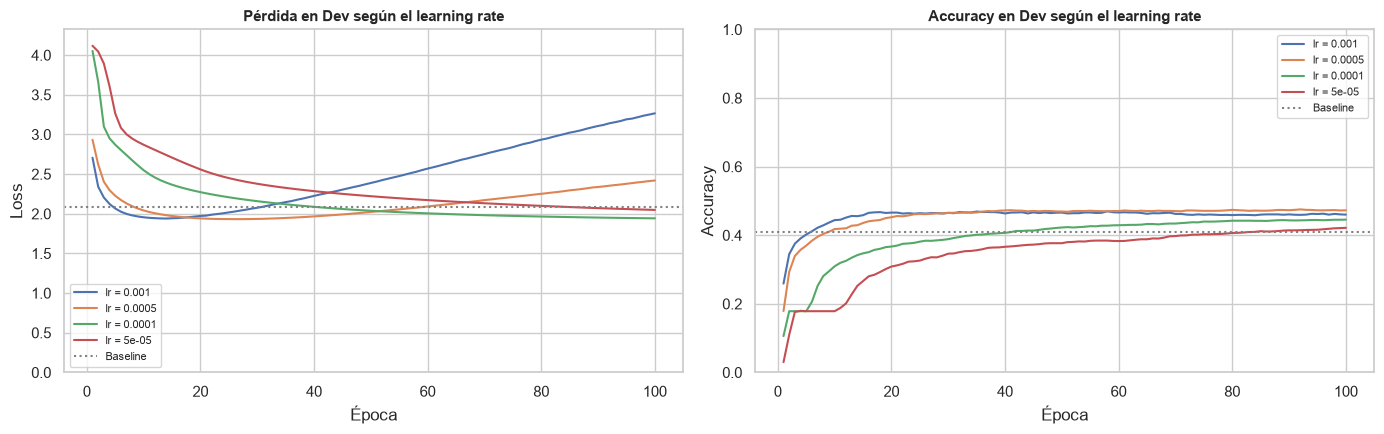

In [22]:
# ==============================================================================
# 7.1 AJUSTE DEL LEARNING RATE (MLP sin regularizar, 5 semillas, 100 épocas)
# ==============================================================================
LRS = [1e-3, 5e-4, 1e-4, 5e-5]
resultados_lr, historiales_lr, modelos_lr = {}, {}, {}

for lr in LRS:
    resultados_lr[lr], historiales_lr[lr], modelos_lr[lr] = evaluar_config({"lr": lr})
    print(f"  lr = {lr:g} listo ({resultados_lr[lr]['tiempo_mean']:.1f} s por corrida)")

df_lr = pd.DataFrame([{
    "lr": f"{lr:g}",
    "Pico acc Dev (μ ± σ)": f"{r['pico_acc_mean']*100:.2f}% ± {r['pico_acc_std']*100:.2f}%",
    "Época del pico": f"{r['ep_pico_acc_mean']:.1f}",
    "Época mín. val_loss": f"{r['ep_min_loss_mean']:.1f}",
    "Distancia (épocas)": f"{r['distancia_mean']:.1f}",
    "Mín. val_loss": f"{r['min_loss_mean']:.4f}",
    "Acc Dev época 100": f"{r['dev_acc_mean']*100:.2f}%",
    "Brecha época 100": f"{r['brecha_mean']*100:.2f} pp",
} for lr, r in resultados_lr.items()]).set_index("lr")
display(df_lr)

# Criterio declarado: mayor pico medio de accuracy en Dev
LR_OPT = max(LRS, key=lambda lr: resultados_lr[lr]["pico_acc_mean"])
print(f"\nLearning rate elegido: {LR_OPT:g}  |  ¿En el borde del rango probado? {LR_OPT in (min(LRS), max(LRS))}")

# Curvas de validación por learning rate (semilla 42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lr in LRS:
    h = historiales_lr[lr]
    ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], label=f"lr = {lr:g}")
    axes[1].plot(ep, h["val_accuracy"], label=f"lr = {lr:g}")
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline")
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline")
axes[0].set_ylim(0, max(max(h["val_loss"]) for h in historiales_lr.values()) * 1.05)
axes[1].set_ylim(0, 1)
axes[0].set_title("Pérdida en Dev según el learning rate", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy en Dev según el learning rate", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

MLP sin regularizar, lr = 0.0005, 100 épocas (5 semillas):
  • Accuracy Train: 71.07% ± 0.64%
  • Accuracy Dev:   46.90% ± 0.49%
  • Brecha Train - Dev: 24.17 pp


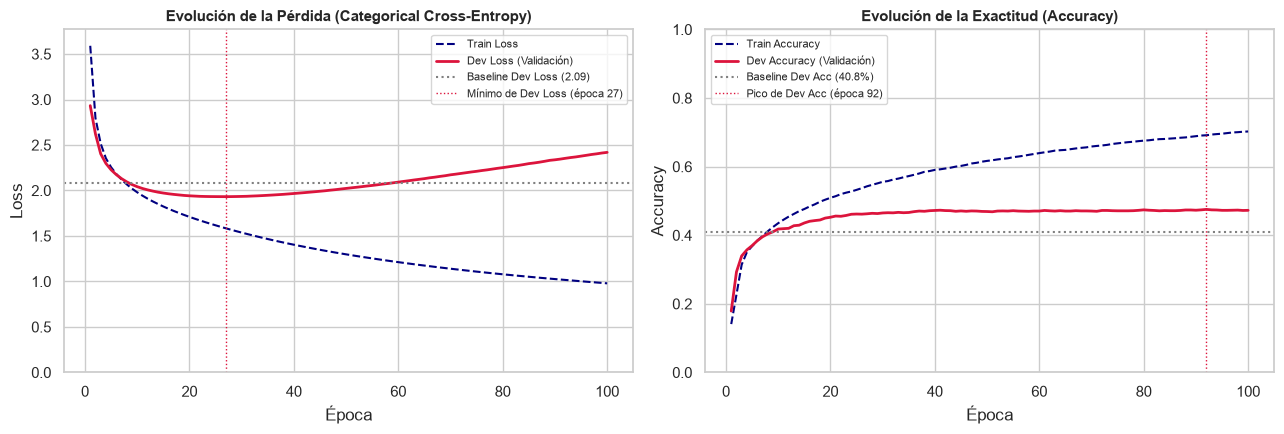

In [23]:
# ==============================================================================
# 7.2 CURVAS DE APRENDIZAJE DEL MLP SIN REGULARIZAR (Consigna 4.2.2)
# ==============================================================================
hist_mlp_base = historiales_lr[LR_OPT]
r_base = resultados_lr[LR_OPT]

print(f"MLP sin regularizar, lr = {LR_OPT:g}, {EPOCAS} épocas (5 semillas):")
print(f"  • Accuracy Train: {r_base['train_acc_mean']*100:.2f}% ± {r_base['train_acc_std']*100:.2f}%")
print(f"  • Accuracy Dev:   {r_base['dev_acc_mean']*100:.2f}% ± {r_base['dev_acc_std']*100:.2f}%")
print(f"  • Brecha Train - Dev: {r_base['brecha_mean']*100:.2f} pp")

epocas = range(1, len(hist_mlp_base["loss"]) + 1)
ep_min = int(np.argmin(hist_mlp_base["val_loss"])) + 1
ep_pico = int(np.argmax(hist_mlp_base["val_accuracy"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Curva de Pérdida (Loss)
axes[0].plot(epocas, hist_mlp_base["loss"], label="Train Loss", color="navy", linestyle="--")
axes[0].plot(epocas, hist_mlp_base["val_loss"], label="Dev Loss (Validación)", color="crimson", linewidth=2)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label=f"Baseline Dev Loss ({loss_base_dev:.2f})")
axes[0].axvline(ep_min, color="crimson", linestyle=":", lw=1, label=f"Mínimo de Dev Loss (época {ep_min})")
axes[0].set_ylim(0, max(hist_mlp_base["loss"] + hist_mlp_base["val_loss"]) * 1.05)
axes[0].set_title("Evolución de la Pérdida (Categorical Cross-Entropy)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

# Curva de Exactitud (Accuracy)
axes[1].plot(epocas, hist_mlp_base["accuracy"], label="Train Accuracy", color="navy", linestyle="--")
axes[1].plot(epocas, hist_mlp_base["val_accuracy"], label="Dev Accuracy (Validación)", color="crimson", linewidth=2)
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label=f"Baseline Dev Acc ({acc_base_dev*100:.1f}%)")
axes[1].axvline(ep_pico, color="crimson", linestyle=":", lw=1, label=f"Pico de Dev Acc (época {ep_pico})")
axes[1].set_ylim(0, 1)
axes[1].set_title("Evolución de la Exactitud (Accuracy)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Interpretación del learning rate (sección 7.1).**
- **$0,001$ y $0,0005$ llegan a lo mismo:** el mínimo de la pérdida en Dev es $1,92$ en los dos y el pico de accuracy es $47,26\%$ contra $47,56\%$, una diferencia menor al desvío entre semillas. La ventaja de $0,0005$ es que se degrada más lento: en la época 100 conserva $46,90\%$ (contra $45,64\%$) y la brecha es de $24,17$ pp (contra $31,07$ pp).
- **Alinear las curvas requiere un learning rate bastante más chico.** Con $0,0005$ la distancia entre el mínimo de la pérdida y el pico de accuracy no se achica: pasa de $23,2$ a $37,4$ épocas, porque el learning rate más chico estira las dos curvas. Con $0,0001$ y $0,00005$ sí quedan alineadas (distancia de una época), pero a las 100 épocas todavía siguen mejorando (pico en las épocas $98,8$ y $99,4$) y se quedan en $44,88\%$ y $41,76\%$. Para saber si con esos valores Early Stopping funciona bien hacen falta más épocas.

**Interpretación de las curvas (lr $= 0,0005$, semilla 42).** La pérdida en Train baja hasta $0,95$, mientras que la de Dev toca su mínimo en la época 27 ($1,93$) y después sube hasta $2,42$. La accuracy en Dev, en cambio, sigue subiendo despacio hasta la época 92. Con 5 semillas, el modelo llega a $71,07\%$ en Train y $46,90\%$ en Dev: **varianza alta**, con una brecha de $24,17$ pp. Además, su perplejidad en Dev ($11,11$) es peor que la del baseline ($8,05$): en las últimas épocas la red se vuelve sobreconfiada.

---
# 8. Consigna 4.2.3: Regularización

Las curvas de la sección 7.2 muestran **varianza alta**: la pérdida en Train baja hasta $0,95$, mientras que la de Dev llega a su mínimo en la época 27 ($1,93$) y después sube hasta $2,42$. La brecha Train–Dev es de $24,17$ pp en promedio con 5 semillas.

Probamos 4 técnicas de regularización para combatir la varianza:
- **Dropout:** apaga neuronas al azar durante el entrenamiento, así la red no se apoya en combinaciones puntuales de Train.
- **L2:** penaliza los pesos grandes, lo que vuelve al modelo más suave y menos dependiente del ruido.
- **Early Stopping:** corta el entrenamiento cuando la pérdida en Dev deja de mejorar y se queda con los mejores pesos.
- **Batch Normalization:** normaliza la salida de cada capa oculta en cada mini-batch (la justificamos en la celda siguiente).

### Cómo las evaluamos
No las probamos todas juntas de entrada, sino de a una:
1. **Cada técnica sola (sección 8.1):** con el learning rate de la sección 7.1, probamos varios valores de cada técnica con 5 semillas y nos quedamos con el mejor de cada una.
2. **Combinación incremental (sección 8.2):** partimos del MLP sin regularizar y en cada paso probamos sumarle cada técnica que falta, con su mejor valor de la sección 8.1. Nos quedamos con el agregado que más mejora, solo si la accuracy media en Dev sube más que el desvío entre semillas del modelo actual. Si ninguno lo logra, paramos.

Así, si al combinar dos técnicas el resultado empeora, sabemos cuál lo causa. El **modelo ganador de la Etapa 2** es el último que acepta este procedimiento.

### Qué esperamos al combinarlas
- **Early Stopping y L2:** las dos frenan el crecimiento de los pesos de forma parecida; cortar el entrenamiento antes equivale aproximadamente a penalizar los pesos con L2. Juntas pueden ser redundantes.
- **Dropout y L2:** Dropout también funciona como una penalización sobre los pesos, adaptada a cada entrada. Sumarle L2 puede quitar capacidad sin mejorar la generalización.
- **Dropout y Batch Normalization:** Dropout cambia la varianza de las activaciones entre el entrenamiento y la predicción, y Batch Normalization usa en la predicción estadísticas calculadas durante el entrenamiento. Combinadas, pueden chocar.

Lo comprobamos con los resultados de la sección 8.2.

> **Aclaración:** como elegimos hiperparámetros y ganador mirando Dev, y Early Stopping usa Dev para decidir cuándo parar, el resultado en Dev es levemente optimista. La medición sin sesgo es la de Test, en la Etapa 5.

### ¿Por qué sumamos Batch Normalization?
La consigna la acepta como técnica de regularización, y en este problema tiene sentido por dos motivos:
1. **Hace al entrenamiento menos sensible al learning rate.** Normaliza la entrada de cada activación en cada mini-batch, así que los pasos del optimizador quedan de un tamaño más parejo entre capas. Como ajustar el learning rate fue el primer paso de esta etapa, nos interesa ver si Batch Normalization estabiliza el entrenamiento.
2. **Regulariza un poco.** La media y el desvío se calculan sobre cada mini-batch de 128 muestras, lo que agrega un ruido leve durante el entrenamiento, parecido al de Dropout.

La ubicamos entre cada capa densa y su ReLU. Es la técnica que esperamos que choque con Dropout, así que su resultado sola y combinada nos sirve para ver si esa expectativa se cumple.

### 8.1 Cada técnica por separado
Todas usan el learning rate fijo de la sección 7.1, 100 épocas como máximo y 5 semillas. El MLP Base de esta sección es el de la sección 7.2.

| Técnica | Valores probados |
|---|---|
| Dropout | $0,05;\ 0,1;\ 0,2;\ 0,3$ |
| L2 | $10^{-6};\ 10^{-5};\ 10^{-4}$ |
| Early Stopping (mira `val_loss` y recupera los mejores pesos) | paciencia $5;\ 10;\ 20$ |
| Batch Normalization | después de cada capa densa |

Para cada técnica elegimos el valor con **mayor accuracy media en Dev** y revisamos si quedó en el borde del rango probado.

In [24]:
# ==============================================================================
# 8.1 CADA TÉCNICA DE REGULARIZACIÓN POR SEPARADO (5 semillas)
# ==============================================================================
GRILLA_IND = {
    "Dropout": [{"dropout": d} for d in [0.05, 0.1, 0.2, 0.3]],
    "L2": [{"l2": v} for v in [1e-6, 1e-5, 1e-4]],
    "Early Stopping": [{"use_es": True, "patience": p} for p in [5, 10, 20]],
    "Batch Normalization": [{"batchnorm": True}],
}

def nombre_config(cfg):
    """Nombre legible de una configuración de regularización."""
    partes = []
    if cfg.get("dropout"):
        partes.append(f"Dropout {cfg['dropout']:g}")
    if cfg.get("l2"):
        partes.append(f"L2 {cfg['l2']:g}")
    if cfg.get("batchnorm"):
        partes.append("BatchNorm")
    if cfg.get("use_es"):
        partes.append(f"ES (paciencia {cfg['patience']})")
    return " + ".join(partes) if partes else "MLP Base"

# El MLP Base es el MLP sin regularizar con el learning rate fijo de la sección 7.1
CFG_ENTRENAMIENTO = {"lr": LR_OPT}
resultados_ablacion = {"MLP Base": resultados_lr[LR_OPT]}
historiales_seed42  = {"MLP Base": historiales_lr[LR_OPT]}
modelos_seed42      = {"MLP Base": modelos_lr[LR_OPT]}

def correr(cfg):
    """Entrena la configuración (si no se entrenó antes) y devuelve su nombre."""
    nombre = nombre_config(cfg)
    if nombre not in resultados_ablacion:
        resultados_ablacion[nombre], historiales_seed42[nombre], modelos_seed42[nombre] = evaluar_config({**CFG_ENTRENAMIENTO, **cfg})
    return nombre

def fila_resumen(nombre, **extra):
    r, base = resultados_ablacion[nombre], resultados_ablacion["MLP Base"]
    return {**extra, "Configuración": nombre,
            "Dev Acc (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
            "Peor semilla": f"{r['dev_acc_min']*100:.2f}%",
            "Δ vs MLP Base": f"{(r['dev_acc_mean'] - base['dev_acc_mean'])*100:+.2f} pp",
            "Train Acc": f"{r['train_acc_mean']*100:.2f}%",
            "Brecha": f"{r['brecha_mean']*100:.2f} pp",
            "Dev Loss": f"{r['dev_loss_mean']:.4f}",
            "Perplejidad": f"{r['dev_perp_mean']:.2f}",
            "Épocas": f"{r['epocas_mean']:.1f}"}

MEJOR_POR_TECNICA = {}
filas_ind = [fila_resumen("MLP Base", Técnica="Ninguna")]

for tecnica, cfgs in GRILLA_IND.items():
    nombres = [correr(c) for c in cfgs]
    filas_ind += [fila_resumen(n, Técnica=tecnica) for n in nombres]
    i_mejor = max(range(len(cfgs)), key=lambda i: resultados_ablacion[nombres[i]]["dev_acc_mean"])
    MEJOR_POR_TECNICA[tecnica] = cfgs[i_mejor]
    borde = len(cfgs) > 1 and i_mejor in (0, len(cfgs) - 1)
    print(f"  {tecnica:<20} mejor: {nombres[i_mejor]:<22} | ¿En el borde del rango? {borde}")

display(pd.DataFrame(filas_ind).set_index(["Técnica", "Configuración"]))

  Dropout              mejor: Dropout 0.05           | ¿En el borde del rango? True


  L2                   mejor: L2 0.0001              | ¿En el borde del rango? True


  Early Stopping       mejor: ES (paciencia 5)       | ¿En el borde del rango? True


  Batch Normalization  mejor: BatchNorm              | ¿En el borde del rango? False


Dev Acc (μ ± σ) Peor semilla  \
Técnica             Configuración                                    
Ninguna             MLP Base           46.90% ± 0.49%       46.42%   
Dropout             Dropout 0.05       48.71% ± 0.52%       48.16%   
                    Dropout 0.1        48.61% ± 0.40%       48.12%   
                    Dropout 0.2        48.14% ± 0.73%       47.15%   
                    Dropout 0.3        46.90% ± 0.38%       46.42%   
L2                  L2 1e-06           46.66% ± 0.49%       45.97%   
                    L2 1e-05           46.72% ± 0.49%       46.11%   
                    L2 0.0001          47.08% ± 0.35%       46.77%   
Early Stopping      ES (paciencia 5)   45.75% ± 0.50%       45.14%   
                    ES (paciencia 10)  45.75% ± 0.50%       45.14%   
                    ES (paciencia 20)  45.75% ± 0.50%       45.14%   
Batch Normalization BatchNorm          43.10% ± 0.71%       42.22%   

                                      Δ vs MLP Base Train Acc    Brecha  \
Técnica             Configuración                                         
Ninguna             MLP Base               +0.00 pp    71.07%  24.17 pp   
Dropout             Dropout 0.05           +1.81 pp    69.43%  20.72 pp   
                    Dropout 0.1            +1.71 pp    66.63%  18.01 pp   
                    Dropout 0.2            +1.24 pp    61.60%  13.46 pp   
                    Dropout 0.3            -0.01 pp    57.04%  10.15 pp   
L2                  L2 1e-06               -0.24 pp    70.66%  24.00 pp   
                    L2 1e-05               -0.19 pp    70.72%  24.01 pp   
                    L2 0.0001              +0.18 pp    69.75%  22.67 pp   
Early Stopping      ES (paciencia 5)       -1.15 pp    54.94%   9.19 pp   
                    ES (paciencia 10)      -1.15 pp    54.94%   9.19 pp   
                    ES (paciencia 20)      -1.15 pp    54.94%   9.19 pp   
Batch Normalization BatchNorm              -3.80 pp    73.91%  30.81 pp   

                                      Dev Loss Perplejidad Épocas  
Técnica             Configuración                                  
Ninguna             MLP Base            2.4070       11.11  100.0  
Dropout             Dropout 0.05        2.0363        7.66  100.0  
                    Dropout 0.1         1.9557        7.07  100.0  
                    Dropout 0.2         1.9097        6.75  100.0  
                    Dropout 0.3         1.9226        6.84  100.0  
L2                  L2 1e-06            2.4076       11.11  100.0  
                    L2 1e-05            2.3952       10.98  100.0  
                    L2 0.0001           2.4049       11.08  100.0  
Early Stopping      ES (paciencia 5)    1.9200        6.82   31.4  
                    ES (paciencia 10)   1.9200        6.82   36.4  
                    ES (paciencia 20)   1.9200        6.82   46.4  
Batch Normalization BatchNorm           5.5251      252.28  100.0

**Interpretación.**
- **Dropout es la única técnica que mejora con claridad.** Con $0,05$ llega a $48,71\% \pm 0,52\%$ ($+1,81$ pp sobre el MLP Base) y con $0,1$ a $48,61\%$, dos valores equivalentes. Cuanto más Dropout, menor la brecha (de $24,17$ pp sin Dropout a $10,15$ pp con $0,3$), pero desde $0,2$ también baja la accuracy en Train, y con $0,3$ la de Dev vuelve al nivel del MLP Base ($46,90\%$). La perplejidad mejora con todos los valores (de $11,11$ a entre $6,75$ y $7,66$).
- **L2 casi no cambia nada.** Los tres valores quedan a menos de $0,25$ pp del MLP Base, dentro del desvío, y la brecha apenas baja a $22,67$ pp con $10^{-4}$.
- **Early Stopping empeora la accuracy ($45,75\%$, $-1,15$ pp)**, como anticipaba la sección 7.1: corta en el mínimo de `val_loss` (época $26,4$ en promedio), cuando la accuracy todavía sube. Las tres paciencias dan exactamente el mismo resultado porque, con `restore_best_weights`, todas recuperan los pesos de esa misma época; solo cambia cuántas épocas de más se entrenan ($31,4$, $36,4$ y $46,4$). Su perplejidad ($6,82$) es de las mejores de la tabla.
- **Batch Normalization es la peor:** $43,10\%$ ($-3,80$ pp), con más brecha que el MLP Base ($30,81$ pp) y una perplejidad de $252,28$, es decir, predicciones muy sobreconfiadas. En este modelo no regulariza: acelera el ajuste a Train ($73,91\%$).
- **Bordes del rango:** Dropout ($0,05$), L2 ($10^{-4}$) y Early Stopping (paciencia 5) quedaron en el borde. En Early Stopping la paciencia no cambia el resultado. En Dropout, $0,05$ y $0,1$ son equivalentes; valores menores no los probamos. En L2, un valor mayor que $10^{-4}$ podría rendir más y queda como experimento pendiente.

### 8.2 Combinación incremental
Cada fila es un candidato: el modelo actual más una técnica con su mejor valor de la sección 8.1. El umbral es el desvío entre semillas del modelo actual; un candidato se acepta si es el mejor del paso y su ganancia supera ese umbral.

In [25]:
# ==============================================================================
# 8.2 COMBINACIÓN INCREMENTAL DE TÉCNICAS (Consigna 4.2.3)
# ==============================================================================
actual_cfg, actual = {}, "MLP Base"
restantes = list(GRILLA_IND)
pasos = []
paso = 1

while restantes:
    candidatos = [(t, {**actual_cfg, **MEJOR_POR_TECNICA[t]}) for t in restantes]
    candidatos = [(t, cfg, correr(cfg)) for t, cfg in candidatos]
    t_mejor, cfg_mejor, n_mejor = max(candidatos, key=lambda c: resultados_ablacion[c[2]]["dev_acc_mean"])

    umbral = resultados_ablacion[actual]["dev_acc_std"]
    ganancia = resultados_ablacion[n_mejor]["dev_acc_mean"] - resultados_ablacion[actual]["dev_acc_mean"]
    acepta = ganancia > umbral

    for t, cfg, n in candidatos:
        g = resultados_ablacion[n]["dev_acc_mean"] - resultados_ablacion[actual]["dev_acc_mean"]
        pasos.append({"Paso": paso, "Modelo actual": actual, "Se agrega": t, "Candidato": n,
                      "Dev Acc (μ ± σ)": f"{resultados_ablacion[n]['dev_acc_mean']*100:.2f}% ± {resultados_ablacion[n]['dev_acc_std']*100:.2f}%",
                      "Ganancia": f"{g*100:+.2f} pp", "Umbral": f"{umbral*100:.2f} pp",
                      "¿Se acepta?": "Sí" if (n == n_mejor and acepta) else "No"})
    if not acepta:
        break
    actual_cfg, actual = cfg_mejor, n_mejor
    restantes.remove(t_mejor)
    paso += 1

GANADOR = actual
display(pd.DataFrame(pasos).set_index(["Paso", "Candidato"]))
print(f"\nModelo ganador de la Etapa 2: {GANADOR}")

# Persistencia oficial en disco para la Etapa 5
registro_etapa2 = {
    "baseline": {
        "params": params_base, "tiempo": tiempo_base,
        "train_acc": float(acc_base_train), "dev_acc": float(acc_base_dev),
        "brecha": float(acc_base_train - acc_base_dev),
        "dev_loss": loss_base_dev, "dev_perp": perp_base_dev
    },
    "learning_rate": {"valores": LRS, "elegido": LR_OPT, "epocas": EPOCAS,
                      "resultados": {f"{lr:g}": r for lr, r in resultados_lr.items()}},
    "mejor_por_tecnica": MEJOR_POR_TECNICA,
    "pasos_incrementales": pasos,
    "configuraciones": resultados_ablacion,
    "ganador": GANADOR
}
with open(OUT_DIR / "resultados_modelos.json", "w", encoding="utf-8") as f:
    json.dump(registro_etapa2, f, indent=2, default=float, ensure_ascii=False)

print("Resultados persistidos en data/processed/resultados_modelos.json")

Modelo actual            Se agrega  \
Paso Candidato                                                            
1    Dropout 0.05                         MLP Base              Dropout   
     L2 0.0001                            MLP Base                   L2   
     ES (paciencia 5)                     MLP Base       Early Stopping   
     BatchNorm                            MLP Base  Batch Normalization   
2    Dropout 0.05 + L2 0.0001         Dropout 0.05                   L2   
     Dropout 0.05 + ES (paciencia 5)  Dropout 0.05       Early Stopping   
     Dropout 0.05 + BatchNorm         Dropout 0.05  Batch Normalization   

                                     Dev Acc (μ ± σ)  Ganancia   Umbral  \
Paso Candidato                                                            
1    Dropout 0.05                     48.71% ± 0.52%  +1.81 pp  0.49 pp   
     L2 0.0001                        47.08% ± 0.35%  +0.18 pp  0.49 pp   
     ES (paciencia 5)                 45.75% ± 0.50%  -1.15 pp  0.49 pp   
     BatchNorm                        43.10% ± 0.71%  -3.80 pp  0.49 pp   
2    Dropout 0.05 + L2 0.0001         48.70% ± 0.55%  -0.01 pp  0.52 pp   
     Dropout 0.05 + ES (paciencia 5)  47.00% ± 0.49%  -1.71 pp  0.52 pp   
     Dropout 0.05 + BatchNorm         48.32% ± 0.47%  -0.39 pp  0.52 pp   

                                     ¿Se acepta?  
Paso Candidato                                    
1    Dropout 0.05                             Sí  
     L2 0.0001                                No  
     ES (paciencia 5)                         No  
     BatchNorm                                No  
2    Dropout 0.05 + L2 0.0001                 No  
     Dropout 0.05 + ES (paciencia 5)          No  
     Dropout 0.05 + BatchNorm                 No


Modelo ganador de la Etapa 2: Dropout 0.05
Resultados persistidos en data/processed/resultados_modelos.json


**Interpretación.**
- **Paso 1:** se acepta Dropout $0,05$ ($+1,81$ pp, con un umbral de $0,49$ pp). Es el único candidato que supera el umbral.
- **Paso 2: ninguna combinación mejora.** Se cumplen las dos expectativas que se podían comprobar (la de Early Stopping con L2 no, porque ninguna de las dos entró en el paso 1):
  - **Dropout + L2** queda igual ($48,70\%$, $-0,01$ pp): son redundantes.
  - **Dropout + Batch Normalization** baja a $48,32\%$ ($-0,39$ pp) y la brecha sube de $20,72$ a $28,73$ pp: las dos técnicas chocan.
  - **Dropout + Early Stopping** baja a $47,00\%$ ($-1,71$ pp), por el mismo motivo que Early Stopping solo: corta antes del pico de accuracy. A cambio, tiene la mejor perplejidad de la etapa ($6,57$) y una brecha de $10,57$ pp.
- **El ganador de la Etapa 2 es el MLP con Dropout $0,05$:** $48,71\% \pm 0,52\%$ en Dev (peor semilla: $48,16\%$), $+7,88$ pp sobre el baseline.

TABLA COMPARATIVA DE MODELOS - ETAPA 2 (learning rate fijo: 0.0005; evaluación en Dev con 5 semillas; ★ = ganador)



,Parámetros,Tiempo Train (s),Train Accuracy,Dev Accuracy (μ ± σ),Dev Accuracy (peor semilla),Brecha Train-Dev,Dev Loss,Dev Perplejidad
Modelo,,,,,,,,
Baseline K=5 (Logística),"19,908",1.92,42.97%,40.83%,—,2.13 pp,2.0853,8.05
MLP Base,"53,536",24.98,71.07%,46.90% ± 0.49%,46.42%,24.17 pp,2.4070,11.11
Dropout 0.05 ★,"53,536",28.44,69.43%,48.71% ± 0.52%,48.16%,20.72 pp,2.0363,7.66
L2 0.0001,"53,536",30.35,69.75%,47.08% ± 0.35%,46.77%,22.67 pp,2.4049,11.08
ES (paciencia 5),"53,536",8.48,54.94%,45.75% ± 0.50%,45.14%,9.19 pp,1.9200,6.82
BatchNorm,"54,432",32.73,73.91%,43.10% ± 0.71%,42.22%,30.81 pp,5.5251,252.28
Dropout 0.05 + L2 0.0001,"53,536",31.15,68.32%,48.70% ± 0.55%,48.16%,19.62 pp,2.0890,8.08
Dropout 0.05 + ES (paciencia 5),"53,536",13.16,57.57%,47.00% ± 0.49%,46.42%,10.57 pp,1.8825,6.57
Dropout 0.05 + BatchNorm,"54,432",35.03,77.05%,48.32% ± 0.47%,47.50%,28.73 pp,2.3907,10.92


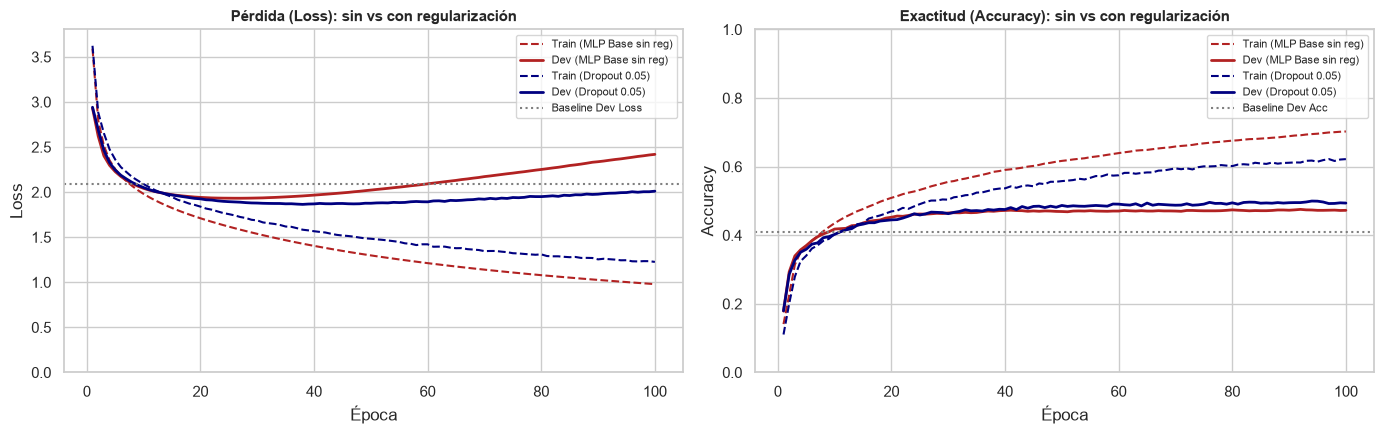

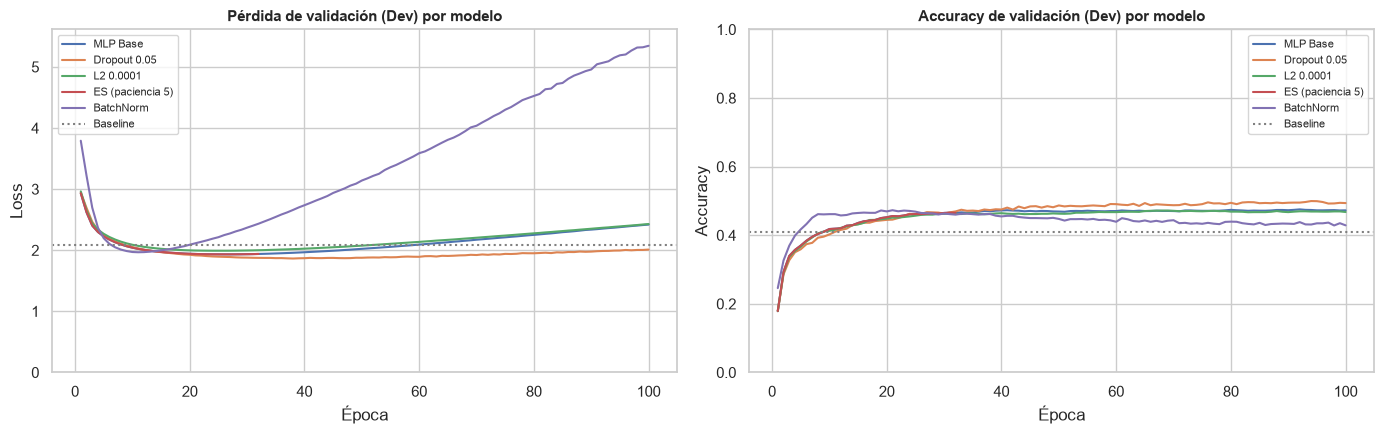

In [26]:
# ==============================================================================
# 8.3 TABLA SÍNTESIS Y CURVAS COMPARATIVAS (Consigna 4.2.3)
# ==============================================================================
mejores_ind = [nombre_config(c) for c in MEJOR_POR_TECNICA.values()]
combinados = [p["Candidato"] for p in pasos if p["Candidato"] not in mejores_ind]
en_tabla = list(dict.fromkeys(["MLP Base"] + mejores_ind + combinados))

filas_tabla = [{
    "Modelo": "Baseline K=5 (Logística)",
    "Parámetros": f"{params_base:,}",
    "Tiempo Train (s)": f"{tiempo_base:.2f}",
    "Train Accuracy": f"{acc_base_train*100:.2f}%",
    "Dev Accuracy (μ ± σ)": f"{acc_base_dev*100:.2f}%",
    "Dev Accuracy (peor semilla)": "—",
    "Brecha Train-Dev": f"{(acc_base_train - acc_base_dev)*100:.2f} pp",
    "Dev Loss": f"{loss_base_dev:.4f}",
    "Dev Perplejidad": f"{perp_base_dev:.2f}"
}]
for n in en_tabla:
    v_m = resultados_ablacion[n]
    filas_tabla.append({
        "Modelo": n + (" ★" if n == GANADOR else ""),
        "Parámetros": f"{v_m['params']:,}",
        "Tiempo Train (s)": f"{v_m['tiempo_mean']:.2f}",
        "Train Accuracy": f"{v_m['train_acc_mean']*100:.2f}%",
        "Dev Accuracy (μ ± σ)": f"{v_m['dev_acc_mean']*100:.2f}% ± {v_m['dev_acc_std']*100:.2f}%",
        "Dev Accuracy (peor semilla)": f"{v_m['dev_acc_min']*100:.2f}%",
        "Brecha Train-Dev": f"{v_m['brecha_mean']*100:.2f} pp",
        "Dev Loss": f"{v_m['dev_loss_mean']:.4f}",
        "Dev Perplejidad": f"{v_m['dev_perp_mean']:.2f}"
    })

df_sintesis = pd.DataFrame(filas_tabla).set_index("Modelo")
print(f"TABLA COMPARATIVA DE MODELOS - ETAPA 2 (learning rate fijo: {LR_OPT:g}; evaluación en Dev con 5 semillas; ★ = ganador)\n")
display(df_sintesis)

# Figura 1: con vs sin regularización, Train y Dev (semilla 42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
h_base = historiales_seed42["MLP Base"]
h_opt  = historiales_seed42[GANADOR]
ep_b = range(1, len(h_base["loss"]) + 1)
ep_o = range(1, len(h_opt["loss"]) + 1)

axes[0].plot(ep_b, h_base["loss"], label="Train (MLP Base sin reg)", color="firebrick", linestyle="--")
axes[0].plot(ep_b, h_base["val_loss"], label="Dev (MLP Base sin reg)", color="firebrick", linewidth=2)
axes[0].plot(ep_o, h_opt["loss"], label=f"Train ({GANADOR})", color="navy", linestyle="--")
axes[0].plot(ep_o, h_opt["val_loss"], label=f"Dev ({GANADOR})", color="navy", linewidth=2)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline Dev Loss")
axes[0].set_ylim(0, max(h_base["loss"] + h_base["val_loss"] + h_opt["loss"] + h_opt["val_loss"]) * 1.05)
axes[0].set_title("Pérdida (Loss): sin vs con regularización", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")

axes[1].plot(ep_b, h_base["accuracy"], label="Train (MLP Base sin reg)", color="firebrick", linestyle="--")
axes[1].plot(ep_b, h_base["val_accuracy"], label="Dev (MLP Base sin reg)", color="firebrick", linewidth=2)
axes[1].plot(ep_o, h_opt["accuracy"], label=f"Train ({GANADOR})", color="navy", linestyle="--")
axes[1].plot(ep_o, h_opt["val_accuracy"], label=f"Dev ({GANADOR})", color="navy", linewidth=2)
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline Dev Acc")
axes[1].set_ylim(0, 1)
axes[1].set_title("Exactitud (Accuracy): sin vs con regularización", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Figura 2: curvas de validación del MLP Base, la mejor versión de cada técnica y el ganador
a_graficar = list(dict.fromkeys(["MLP Base"] + mejores_ind + [GANADOR]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre in a_graficar:
    hist = historiales_seed42[nombre]
    ep = range(1, len(hist["loss"]) + 1)
    axes[0].plot(ep, hist["val_loss"], label=nombre)
    axes[1].plot(ep, hist["val_accuracy"], label=nombre)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline")
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline")
axes[0].set_ylim(0, max(max(historiales_seed42[n]["val_loss"]) for n in a_graficar) * 1.05)
axes[1].set_ylim(0, 1)
axes[0].set_title("Pérdida de validación (Dev) por modelo", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy de validación (Dev) por modelo", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.4 ¿Dónde mejora el MLP?
Volvemos a usar `accuracy_por_tipo` y `explicar_prediccion` (secciones 6.3 y 6.4) para comparar el baseline con el modelo ganador. Usamos el modelo de la semilla 42, así que diferencias por tipo de un par de puntos no son concluyentes.


,Casos en Dev,% de Dev,Accuracy Baseline,Accuracy Dropout 0.05,Δ (pp)
espacio,514,17.8,0.8580,0.8930,3.50
vocal,817,28.4,0.3060,0.4223,11.63
consonante,1451,50.4,0.3280,0.4197,9.17
mayúscula,38,1.3,0.1842,0.1579,-2.63
puntuación/dígito,60,2.1,0.0333,0.0500,1.67


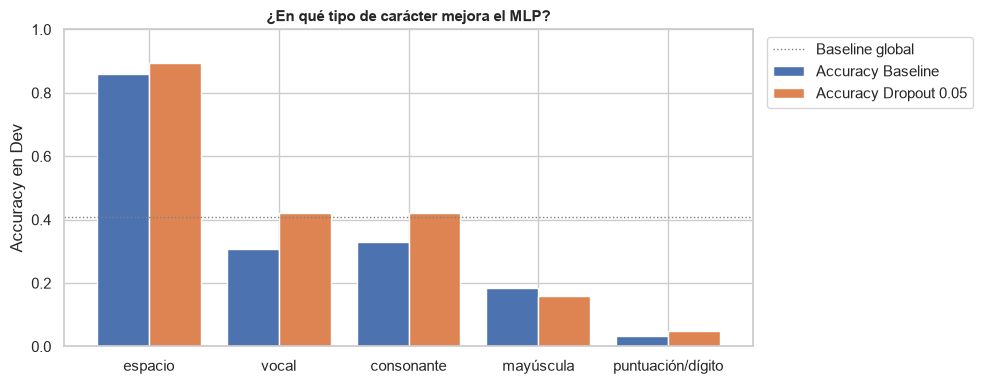

Causa (pre-etiqueta por reglas): Falta de cobertura (5-grama nuevo)
  [Baseline] contexto '...ad been striking. Af' | real 't' en el puesto 4 (P = 0.074)
     top-5: '<SP>' 0.503 | 'a' 0.102 | 'o' 0.100 | 't' 0.074 | 'l' 0.048
  [Dropout 0.05] contexto '...ad been striking. Af' | real 't' en el puesto 1 (P = 0.922)
     top-5: 't' 0.922 | 'f' 0.056 | 'a' 0.011 | 'h' 0.003 | '<SP>' 0.002

Causa (pre-etiqueta por reglas): Ruido irreducible (Error Bayes)
  [Baseline] contexto '... wrote a quaint and ' | real 'a' en el puesto 4 (P = 0.090)
     top-5: 't' 0.147 | 'w' 0.140 | 's' 0.095 | 'a' 0.090 | 'h' 0.059
  [Dropout 0.05] contexto '... wrote a quaint and ' | real 'a' en el puesto 5 (P = 0.054)
     top-5: 't' 0.205 | 's' 0.140 | 'w' 0.117 | 'm' 0.057 | 'a' 0.054

Causa (pre-etiqueta por reglas): Sesgo (Underfitting)
  [Baseline] contexto '...tone above with a na' | real 's' en el puesto 3 (P = 0.088)
     top-5: 't' 0.160 | 'd' 0.127 | 's' 0.088 | 'l' 0.087 | '<SP>' 0.086


  [Dropout 0.05] contexto '...tone above with a na' | real 's' en el puesto 6 (P = 0.058)
     top-5: 'r' 0.245 | 'l' 0.195 | 'm' 0.110 | 'w' 0.087 | 'n' 0.068

Causa (pre-etiqueta por reglas): Varianza (Overfitting)
  [Baseline] contexto '...ersons on the settle' | real ',' en el puesto 3 (P = 0.054)
     top-5: '<SP>' 0.708 | 'n' 0.055 | ',' 0.054 | 's' 0.045 | 'e' 0.019
  [Dropout 0.05] contexto '...ersons on the settle' | real ',' en el puesto 2 (P = 0.043)
     top-5: '<SP>' 0.905 | ',' 0.043 | 's' 0.012 | '.' 0.010 | '-' 0.007



In [27]:
# ==============================================================================
# 8.4 BASELINE VS MODELO GANADOR: ACCURACY POR TIPO Y EXPLICACIÓN DE CASOS
# ==============================================================================
modelo_ganador = modelos_seed42[GANADOR]

def proba_mlp(contextos, modelo=modelo_ganador):
    """Matriz (n, |V|) de probabilidades del MLP, en el orden de char2idx."""
    X_oh, _ = extraer_tensores_onehot(contextos, [" "] * len(contextos), K_OPTIMO, char2idx, vocab_size)
    return modelo.predict(X_oh, verbose=0)

y_pred_dev_mlp = [idx2char[i] for i in proba_mlp(X_dev).argmax(axis=1)]

df_tipos = df_tipos_base.copy()
df_tipos[f"Accuracy {GANADOR}"] = pd.Series(accuracy_por_tipo(y_pred_dev_mlp)).reindex(TIPOS_CHAR).round(4)
df_tipos["Δ (pp)"] = ((df_tipos[f"Accuracy {GANADOR}"] - df_tipos["Accuracy Baseline"]) * 100).round(2)
display(df_tipos)

# Gráfico de barras agrupadas por tipo
ax = df_tipos[["Accuracy Baseline", f"Accuracy {GANADOR}"]].plot.bar(figsize=(10, 4), width=0.8, rot=0)
ax.axhline(acc_base_dev, color="gray", ls=":", lw=1, label="Baseline global")
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy en Dev")
ax.set_xlabel("")
ax.set_title("¿En qué tipo de carácter mejora el MLP?", fontsize=11, fontweight="bold")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

# Mismos casos de la sección 6.4, ahora con ambos modelos
for _, fila in casos_ejemplo.iterrows():
    print(f"Causa (pre-etiqueta por reglas): {fila['causa_teorica']}")
    explicar_prediccion(proba_baseline, X_dev[fila["dev_idx"]], fila["y_real"], "Baseline")
    explicar_prediccion(proba_mlp, X_dev[fila["dev_idx"]], fila["y_real"], GANADOR)
    print()


In [28]:
# ==============================================================================
# 8.5 ESTIMACIÓN DEL SESGO EVITABLE DEL BASELINE (ver advertencia de la sección 6.2)
# ==============================================================================
err_tr_base    = 1 - acc_base_train
err_tr_mlpbase = 1 - resultados_ablacion["MLP Base"]["train_acc_mean"]
err_tr_ganador = 1 - resultados_ablacion[GANADOR]["train_acc_mean"]
mejora_dev     = resultados_ablacion[GANADOR]["dev_acc_mean"] - acc_base_dev

print(f"Error de Train del baseline:                 {err_tr_base*100:.2f}%")
print(f"Error de Train del MLP sin regularizar:      {err_tr_mlpbase*100:.2f}%  (memoriza: no sirve como cota)")
print(f"Error de Train del modelo ganador:           {err_tr_ganador*100:.2f}%")
print(f"\nReducción del error de Train con el ganador: {(err_tr_base - err_tr_ganador)*100:.2f} pp")
print(f"Mejora en Dev del ganador sobre el baseline: {mejora_dev*100:.2f} pp")

Error de Train del baseline:                 57.03%
Error de Train del MLP sin regularizar:      28.93%  (memoriza: no sirve como cota)
Error de Train del modelo ganador:           30.57%

Reducción del error de Train con el ganador: 26.46 pp
Mejora en Dev del ganador sobre el baseline: 7.88 pp


### 8.6 Conclusiones de la Etapa 2

1. **Mejora sobre la Etapa 1:** el MLP 128-64-32 con Dropout $0,05$ llega a $48,71\% \pm 0,52\%$ en Dev, contra $40,83\%$ del baseline: **$+7,88$ pp**. Los dos usan los mismos 5 caracteres de contexto; la mejora viene de que la regresión logística suma el aporte de cada posición por separado, mientras que el MLP puede combinar posiciones.
2. **Diagnóstico:** el baseline tenía **sesgo alto** (error de Train de $57,03\%$, brecha de $2,13$ pp). El MLP baja el error de Train a $30,57\%$ ($-26,46$ pp), pero pasa a tener **varianza alta**: brecha de $24,17$ pp sin regularizar y de $20,72$ pp con Dropout. Con 12.780 ventanas de Train, la red memoriza combinaciones que no se repiten en Dev.
3. **Regularización:** de las 4 técnicas, solo Dropout mejora la accuracy en Dev más que el desvío entre semillas. Early Stopping mejora la perplejidad, pero no la accuracy, porque la pérdida en Dev toca su mínimo antes que la accuracy. Batch Normalization empeora, sola y combinada.
4. **Dónde mejora:** en la sección 8.4 (semilla 42), la ganancia está en las vocales ($+11,63$ pp) y las consonantes ($+9,17$ pp). En mayúsculas y puntuación, con 38 y 60 casos, no hay mejora clara.
5. **Límite:** las diferencias entre las mejores configuraciones de esta etapa son del orden del desvío entre semillas. Con un solo cuento de 20.180 caracteres, el MLP con 5 caracteres de contexto parece estar cerca de su techo. La Etapa 3 prueba si los embeddings y un contexto más largo lo mueven.

### 8.7 Registro de experimentos que no funcionaron

| Experimento | Resultado en Dev | Por qué no funcionó |
|---|---|---|
| Learning rate $0,001$ | pico $47,26\%$; $45,64\%$ en la época 100 | aprende más rápido y sobreajusta antes (brecha de $31,07$ pp) |
| Learning rate $0,0001$ y $0,00005$, 100 épocas | $44,88\%$ y $41,76\%$ | no llegan a converger en 100 épocas |
| Dropout $0,3$ | $46,90\%$ | regulariza de más: la accuracy en Train baja a $57,04\%$ |
| L2 ($10^{-6}$, $10^{-5}$, $10^{-4}$) | entre $46,66\%$ y $47,08\%$ | efecto dentro del desvío entre semillas |
| Early Stopping (paciencia 5, 10 y 20) | $45,75\%$ | corta en el mínimo de `val_loss`, antes del pico de accuracy |
| Batch Normalization | $43,10\%$, perplejidad $252,28$ | acelera el sobreajuste y vuelve al modelo sobreconfiado |
| Dropout $0,05$ + L2 $10^{-4}$ | $48,70\%$ | redundante con Dropout |
| Dropout $0,05$ + Early Stopping | $47,00\%$ | el mismo corte temprano de Early Stopping solo |
| Dropout $0,05$ + Batch Normalization | $48,32\%$ | las dos técnicas chocan (brecha de $28,73$ pp) |

---
# 9. Síntesis y checklist de la Etapa 2
Estado de cada requisito de la consigna antes de pasar a la Etapa 3.


In [29]:
# ==============================================================================
# 9.1 CHECKLIST OFICIAL DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)
# ==============================================================================
r_gan = resultados_ablacion[GANADOR]
delta_gan = (r_gan["dev_acc_mean"] - acc_base_dev) * 100

print("=" * 80)
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)")
print("=" * 80)
print(f"  [x] 4.2.1 Análisis de errores manual: 50 errores clasificados por reglas y revisados a mano por el grupo (coinciden 14 de 24).")
print(f"  [x] 4.2.1 Diagnóstico de sesgo vs varianza del baseline (brecha Train - Dev = {(acc_base_train - acc_base_dev)*100:.2f} pp).")
print(f"  [x] 4.2.1 Accuracy por tipo de carácter y explicación de predicciones.")
print(f"  [x] 4.2.2 Arquitectura MLP en tf.keras: 3 capas ocultas (128-64-32, {resultados_ablacion['MLP Base']['params']:,} parámetros).")
print(f"  [x] 4.2.2 Funciones documentadas: ReLU, Softmax, Loss Categorical Cross-Entropy y Adam (lr fijo = {LR_OPT:g}, sección 7.1).")
print(f"  [x] 4.2.2 Curvas de aprendizaje (Loss y Accuracy) en Train y Dev.")
print(f"  [x] 4.2.3 Regularización: 4 técnicas probadas de a una (mejores: {', '.join(mejores_ind)}).")
print(f"  [x] 4.2.3 Combinación incremental con 5 semillas por configuración, curvas con y sin regularización.")
print(f"  [x] 4.2.3 Mejora sobre el Baseline en Dev: {GANADOR} = {r_gan['dev_acc_mean']*100:.2f}% ± {r_gan['dev_acc_std']*100:.2f}% ({delta_gan:+.2f} pp).")
print(f"  [x] Parámetros y tiempos registrados en resultados_modelos.json para la Etapa 5.")
print(f"  [x] Conjunto Test estrictamente preservado sin evaluar hasta la Etapa 5.")
print("=" * 80)

CHECKLIST DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)
  [x] 4.2.1 Análisis de errores manual: 50 errores clasificados por reglas y revisados a mano por el grupo (coinciden 14 de 24).
  [x] 4.2.1 Diagnóstico de sesgo vs varianza del baseline (brecha Train - Dev = 2.13 pp).
  [x] 4.2.1 Accuracy por tipo de carácter y explicación de predicciones.
  [x] 4.2.2 Arquitectura MLP en tf.keras: 3 capas ocultas (128-64-32, 53,536 parámetros).
  [x] 4.2.2 Funciones documentadas: ReLU, Softmax, Loss Categorical Cross-Entropy y Adam (lr fijo = 0.0005, sección 7.1).
  [x] 4.2.2 Curvas de aprendizaje (Loss y Accuracy) en Train y Dev.
  [x] 4.2.3 Regularización: 4 técnicas probadas de a una (mejores: Dropout 0.05, L2 0.0001, ES (paciencia 5), BatchNorm).
  [x] 4.2.3 Combinación incremental con 5 semillas por configuración, curvas con y sin regularización.
  [x] 4.2.3 Mejora sobre el Baseline en Dev: Dropout 0.05 = 48.71% ± 0.52% (+7.88 pp).
  [x] Parámetros y tiempos registrados en resultados_modelos.json pa

---
---
# ETAPA 3: Embeddings y modelo de lenguaje

### Punto de partida
En la Etapa 2 el mejor modelo fue un MLP con Dropout que recibe los últimos 5 caracteres en one-hot. Ninguna técnica de regularización lo sacó de la zona del 48–49 % en Dev, y la brecha con Train quedó por encima de 20 pp. En esta etapa cambiamos la **representación de la entrada** y, después, el **tipo de modelo**:
1. **Red densa sobre embeddings (sección 2):** el mismo MLP de la Etapa 2, pero cada carácter entra como un vector denso aprendido en lugar de un one-hot. Comparamos embeddings de dos tamaños, **entrenados desde cero**.
2. **Modelo de lenguaje simple (sección 3):** una LSTM, que lee el contexto en orden y puede usar los 40 caracteres de la ventana, no solo los últimos 5.
3. **Embeddings de palabras pre-entrenados vs desde cero (sección 8):** la comparación que pide la consigna 4.3.B, con GloVe.

### Decisiones generales
1. **Embeddings de caracteres, no de palabras.** La tarea predice el siguiente carácter, así que cada token de entrada es un carácter.
2. **Los pre-entrenados se comparan con palabras.** GloVe y Word2Vec, los que menciona la consigna, tienen vectores de palabras, no de caracteres. Por eso la comparación entre pre-entrenados y desde cero se hace en la sección 8, prediciendo la siguiente palabra.
3. **Mismos datos y misma métrica:** la partición por bloques de la Etapa 1 y la accuracy en Dev. Test sigue sin usarse hasta la Etapa 5.
4. **Misma configuración de entrenamiento que el ganador de la Etapa 2** (learning rate, Dropout, batch y épocas), para que la diferencia se deba a la representación o al modelo. R3 y R4 suman Early Stopping y `clipnorm` (sección 3.2).
5. **5 semillas por modelo**, con media ± desvío.

---
# 1. Configuración y datos

In [1]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import time
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
SEEDS = [42, 123, 456, 789, 2026]
np.random.seed(SEED)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
# ==============================================================================
# 1.2 CARGA DEL TEXTO LIMPIO Y DE LA PARTICIÓN DE LA ETAPA 1
# ==============================================================================
PROC = BASE_DIR / "data" / "processed"

text = (PROC / "The_Festival_clean.txt").read_text(encoding="utf-8")
splits = json.load(open(PROC / "splits_bloques.json", encoding="utf-8"))

L = splits["L"]
limites = splits["limites_bloques"]
bloques_split = splits["bloques"]
vocabulary = list(splits["vocabulario"])
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
# Muestra el espacio y el salto de línea de forma legible en tablas y gráficos
vis = lambda c: {" ": "<SP>", "\n": "<NL>"}.get(c, c)
V = len(vocabulary)

def ventanas_de_bloques(ids):
    X, y = [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
    return X, y

X_train, y_train = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev   = ventanas_de_bloques(bloques_split["dev"])

# Entrada como índices enteros: (N, L)
a_indices = lambda X: np.array([[char2idx[c] for c in x] for x in X], dtype=np.int32)
Xi_train, Xi_dev = a_indices(X_train), a_indices(X_dev)
yi_train = np.array([char2idx[c] for c in y_train], dtype=np.int32)
yi_dev   = np.array([char2idx[c] for c in y_dev], dtype=np.int32)

print(f"|V| = {V} | L = {L}")
print(f"Train: {len(X_train):,} muestras | Dev: {len(X_dev):,} muestras")

|V| = 64 | L = 40
Train: 12,780 muestras | Dev: 2,880 muestras


In [3]:
# ==============================================================================
# 1.3 REFERENCIAS DE LAS ETAPAS 1 Y 2
# ==============================================================================
ref_base = json.load(open(PROC / "baseline_dev.json", encoding="utf-8"))
reg2 = json.load(open(PROC / "resultados_modelos.json", encoding="utf-8"))
ref2 = reg2["configuraciones"][reg2["ganador"]]

# Configuración de entrenamiento heredada del ganador de la Etapa 2
CFG2 = ref2["config"]
LR = CFG2["lr"]
DROPOUT = CFG2.get("dropout", 0.0)
EPOCAS = reg2["learning_rate"]["epocas"]
BATCH = 128
K = ref_base["K"]

print(f"Baseline (Etapa 1): {ref_base['accuracy_dev']*100:.2f}% en Dev")
print(f"Ganador Etapa 2 ({reg2['ganador']}): {ref2['dev_acc_mean']*100:.2f}% ± {ref2['dev_acc_std']*100:.2f}% en Dev")
print(f"Configuración heredada: lr = {LR:g} | Dropout = {DROPOUT} | {EPOCAS} épocas | batch {BATCH} | K = {K}")

Baseline (Etapa 1): 40.83% en Dev
Ganador Etapa 2 (Dropout 0.05): 48.71% ± 0.52% en Dev
Configuración heredada: lr = 0.0005 | Dropout = 0.05 | 100 épocas | batch 128 | K = 5


---
# 2. Consigna 4.3.B: Red densa sobre embeddings
Mantenemos la red de la Etapa 2 (Dense 128 → 64 → 32 con ReLU, Dropout y salida softmax) y los mismos últimos $K = 5$ caracteres. Solo cambia cómo entra cada carácter:

| Modelo | Representación de cada carácter |
|---|---|
| **E0 — One-hot (Etapa 2)** | vector one-hot de 64 posiciones; repetimos el ganador de la Etapa 2 en las mismas condiciones |
| **E1 — Desde cero, 16 dim.** | embedding de 16 dimensiones aprendido junto con la red |
| **E2 — Desde cero, 300 dim.** | embedding de 300 dimensiones aprendido junto con la red |

E0 contra E1 y E2 muestra qué cambia al pasar del one-hot a un embedding aprendido; E1 contra E2, el efecto de la dimensión.

In [4]:
# ==============================================================================
# 2.1 CONSTRUCCIÓN, ENTRENAMIENTO Y EVALUACIÓN CON 5 SEMILLAS
# ==============================================================================
def construir_modelo(tipo, k=K, emb_dim=16, emb_init=None, emb_trainable=True, dropout=DROPOUT, unidades_lstm=128):
    """
    tipo = "onehot": MLP de la Etapa 2 sobre one-hot aplanado.
    tipo = "densa":  Embedding -> Flatten -> MLP 128-64-32.
    tipo = "lstm":   Embedding -> LSTM -> Dropout -> softmax.
    """
    entrada = layers.Input(shape=(k,), dtype="int32")
    if tipo == "onehot":
        # One-hot exacto: embedding fijo con la matriz identidad
        x = layers.Embedding(V, V, embeddings_initializer=keras.initializers.Identity(), trainable=False)(entrada)
    else:
        init = keras.initializers.Constant(emb_init) if emb_init is not None else "uniform"
        x = layers.Embedding(V, emb_dim, embeddings_initializer=init, trainable=emb_trainable, name="embedding")(entrada)

    if tipo in ("onehot", "densa"):
        x = layers.Flatten()(x)
        for u in [128, 64, 32]:
            x = layers.Dense(u, activation="relu")(x)
            if dropout > 0:
                x = layers.Dropout(dropout)(x)
    else:
        x = layers.LSTM(unidades_lstm)(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)

    salida = layers.Dense(V, activation="softmax")(x)
    return keras.Model(entrada, salida)

def evaluar(constructor, k, epochs=EPOCAS, seeds=SEEDS, lr=None, clipnorm=None, use_es=False, patience=5):
    """Entrena con cada semilla y devuelve (resumen, historial y modelo de la semilla 42)."""
    Xtr, Xdv = Xi_train[:, -k:], Xi_dev[:, -k:]
    corridas = []
    for s in seeds:
        keras.utils.set_random_seed(s)
        modelo = constructor()
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr or LR, clipnorm=clipnorm),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cbs = []
        if use_es:
            cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
        t0 = time.perf_counter()
        h = modelo.fit(Xtr, yi_train, validation_data=(Xdv, yi_dev), epochs=epochs, batch_size=BATCH,
                       callbacks=cbs, verbose=0)
        t_run = time.perf_counter() - t0
        if s == SEED:
            h42, m42 = h.history, modelo
        loss_tr, acc_tr = [float(v) for v in modelo.evaluate(Xtr, yi_train, verbose=0)]
        loss_dv, acc_dv = [float(v) for v in modelo.evaluate(Xdv, yi_dev, verbose=0)]
        va = h.history["val_accuracy"]
        corridas.append({"seed": s, "tiempo": t_run, "train_acc": acc_tr, "dev_acc": acc_dv,
                         "brecha": acc_tr - acc_dv, "dev_loss": loss_dv, "dev_perp": float(np.exp(loss_dv)),
                         "pico_acc": float(max(va)), "ep_pico_acc": int(np.argmax(va)) + 1,
                         "epocas": len(h.history["loss"])})
    df_c = pd.DataFrame(corridas)
    resumen = {"params": int(sum(np.prod(w.shape) for w in m42.trainable_weights)), "k": k, "dev_acc_min": float(df_c["dev_acc"].min()), "corridas": corridas}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    return resumen, h42, m42

MODELOS_DENSOS = {
    "E0 — One-hot (Etapa 2)":       lambda: construir_modelo("onehot"),
    "E1 — Desde cero, 16 dim.":     lambda: construir_modelo("densa", emb_dim=16),
    "E2 — Desde cero, 300 dim.":    lambda: construir_modelo("densa", emb_dim=300),
}

resultados, historiales, modelos = {}, {}, {}
for nombre, constructor in MODELOS_DENSOS.items():
    resultados[nombre], historiales[nombre], modelos[nombre] = evaluar(constructor, k=K)
    r = resultados[nombre]
    print(f"  {nombre:<30} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | brecha {r['brecha_mean']*100:.2f} pp | {r['tiempo_mean']:.0f} s por corrida")

def tabla(nombres):
    filas = []
    for n in nombres:
        r = resultados[n]
        filas.append({"Modelo": n, "Parámetros entrenables": f"{r['params']:,}",
                      "Dev Acc (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
                      "Peor semilla": f"{r['dev_acc_min']*100:.2f}%",
                      "Δ vs Etapa 2": f"{(r['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp",
                      "Train Acc": f"{r['train_acc_mean']*100:.2f}%",
                      "Brecha": f"{r['brecha_mean']*100:.2f} pp",
                      "Dev Loss": f"{r['dev_loss_mean']:.4f}",
                      "Perplejidad": f"{r['dev_perp_mean']:.2f}",
                      "Pico Dev (época)": f"{r['pico_acc_mean']*100:.2f}% ({r['ep_pico_acc_mean']:.0f})",
                      "Épocas": f"{r['epocas_mean']:.0f}"})
    return pd.DataFrame(filas).set_index("Modelo")

display(tabla(MODELOS_DENSOS))

  E0 — One-hot (Etapa 2)         Dev: 48.71% ± 0.52% | brecha 20.72 pp | 35 s por corrida


  E1 — Desde cero, 16 dim.       Dev: 47.88% ± 0.73% | brecha 10.11 pp | 25 s por corrida


  E2 — Desde cero, 300 dim.      Dev: 49.51% ± 0.81% | brecha 25.62 pp | 40 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E1 — Desde cero, 16 dim.","23,840",47.88% ± 0.73%,47.05%,-0.83 pp,57.99%,10.11 pp,1.8739,6.51,48.21% (95),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100


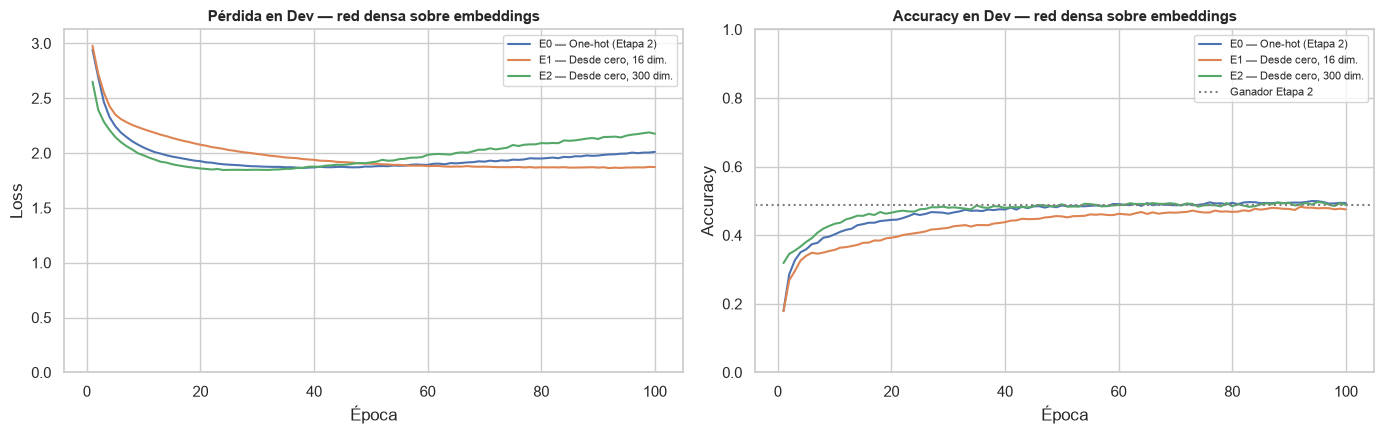

In [5]:
# ==============================================================================
# 2.2 CURVAS DE VALIDACIÓN (semilla 42)
# ==============================================================================
def graficar_curvas(nombres, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for n in nombres:
        h = historiales[n]
        ep = range(1, len(h["loss"]) + 1)
        axes[0].plot(ep, h["val_loss"], label=n)
        axes[1].plot(ep, h["val_accuracy"], label=n)
    axes[1].axhline(ref2["dev_acc_mean"], color="gray", linestyle=":", label="Ganador Etapa 2")
    axes[0].set_ylim(0, max(max(historiales[n]["val_loss"]) for n in nombres) * 1.05)
    axes[1].set_ylim(0, 1)
    axes[0].set_title(f"Pérdida en Dev — {titulo}", fontsize=11, fontweight="bold")
    axes[1].set_title(f"Accuracy en Dev — {titulo}", fontsize=11, fontweight="bold")
    axes[0].set_ylabel("Loss")
    axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

graficar_curvas(MODELOS_DENSOS, "red densa sobre embeddings")

**Interpretación.**
- **E0 reproduce exactamente el ganador de la Etapa 2** ($48,71\% \pm 0,52\%$), así que las comparaciones de esta etapa se hacen en las mismas condiciones.
- **Desde cero, la dimensión cambia el balance entre acierto y sobreajuste.** Con 16 dimensiones (E1) la accuracy baja a $47,88\%$, pero la brecha cae a $10,11$ pp y la perplejidad a $6,51$, la mejor de la sección: una representación chica funciona como regularización. Con 300 dimensiones (E2) la accuracy sube a $49,51\%$ ($+0,81$ pp sobre E0), pero la brecha crece a $25,62$ pp y la perplejidad empeora a $8,66$. La mejora de E2 sobre E0 es del tamaño del desvío entre semillas, así que es chica.

En resumen: pasar del one-hot a un embedding aprendido mejora poco la accuracy. El tamaño del embedding mueve sobre todo el balance entre acierto y sobreajuste.

---
# 3. Modelo de lenguaje simple: LSTM
La red densa mira los 5 caracteres como un bloque fijo. Una LSTM los lee en orden y mantiene un estado que resume lo que vino antes, así que puede aprovechar contextos más largos sin que crezca la cantidad de parámetros. Usamos la mejor representación de la sección 2 y probamos dos largos de contexto:

| Modelo | Contexto | Para qué |
|---|---|---|
| **R1 — LSTM, 5 caracteres** | los mismos $K = 5$ | separa el efecto de leer en orden del efecto de ver más contexto |
| **R2 — LSTM, 40 caracteres** | la ventana completa ($L = 40$) | mide cuánto aporta el contexto largo |

La LSTM tiene 128 unidades, seguida de Dropout y la capa de salida softmax.

Representación elegida para la LSTM: E2 — Desde cero, 300 dim.



  R1 — LSTM, 5 caracteres    Dev: 49.69% ± 0.12% | brecha 28.67 pp | 100 s por corrida


  R2 — LSTM, 40 caracteres   Dev: 45.06% ± 1.70% | brecha 27.41 pp | 583 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100


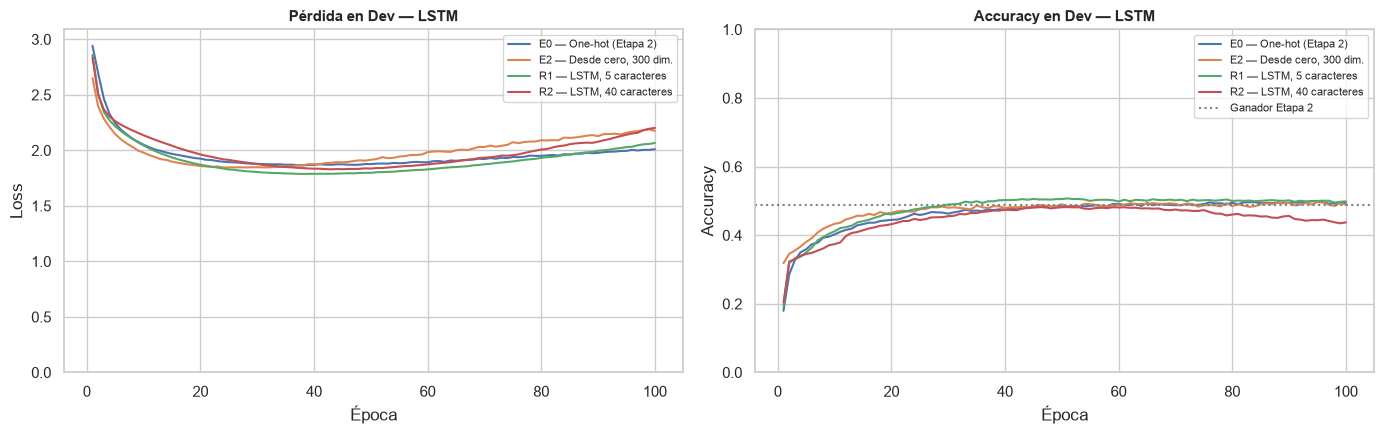

In [6]:
# ==============================================================================
# 3.1 LSTM CON LA MEJOR REPRESENTACIÓN DE LA SECCIÓN 2
# ==============================================================================
candidatos_emb = [n for n in MODELOS_DENSOS if not n.startswith("E0")]
MEJOR_EMB = max(candidatos_emb, key=lambda n: resultados[n]["dev_acc_mean"])
cfg_emb = {
    "E1 — Desde cero, 16 dim.":     dict(emb_dim=16),
    "E2 — Desde cero, 300 dim.":    dict(emb_dim=300),
}[MEJOR_EMB]
print(f"Representación elegida para la LSTM: {MEJOR_EMB}\n")

MODELOS_LSTM = {
    "R1 — LSTM, 5 caracteres":  (lambda: construir_modelo("lstm", k=K, **cfg_emb), K),
    "R2 — LSTM, 40 caracteres": (lambda: construir_modelo("lstm", k=L, **cfg_emb), L),
}
# R2 tarda unos 54 minutos (5 semillas). La primera corrida guarda sus resultados y curvas en un caché;
# las siguientes los cargan, salvo que cambie la configuración. Las semillas fijas dan los mismos números.
R2 = "R2 — LSTM, 40 caracteres"
CACHE_R2 = PROC / "cache_R2.json"
cfg_r2 = {"emb": cfg_emb, "lr": LR, "dropout": DROPOUT, "epocas": EPOCAS, "batch": BATCH, "seeds": SEEDS}
cache = json.load(open(CACHE_R2, encoding="utf-8")) if CACHE_R2.exists() else None

for nombre, (constructor, k) in MODELOS_LSTM.items():
    if nombre == R2 and cache is not None and cache["config"] == cfg_r2:
        resultados[nombre], historiales[nombre] = cache["resultado"], cache["historial"]
        print(f"  {nombre}: cargado de {CACHE_R2.name}")
    else:
        resultados[nombre], historiales[nombre], modelos[nombre] = evaluar(constructor, k=k)
        if nombre == R2:
            historial = {m: [float(v) for v in vals] for m, vals in historiales[nombre].items()}
            json.dump({"config": cfg_r2, "resultado": resultados[nombre], "historial": historial},
                      open(CACHE_R2, "w", encoding="utf-8"), ensure_ascii=False)
    r = resultados[nombre]
    print(f"  {nombre:<26} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | brecha {r['brecha_mean']*100:.2f} pp | {r['tiempo_mean']:.0f} s por corrida")

display(tabla(["E0 — One-hot (Etapa 2)", MEJOR_EMB] + list(MODELOS_LSTM)))
graficar_curvas(["E0 — One-hot (Etapa 2)", MEJOR_EMB] + list(MODELOS_LSTM), "LSTM")

**Interpretación.**
- **La LSTM con 5 caracteres (R1) es la mejor de esta sección:** $49,69\% \pm 0,12\%$, la más estable entre semillas. Frente a la red densa con la misma representación (E2) gana solo $0,18$ pp: con 5 caracteres, leerlos en orden aporta poco sobre verlos como bloque. Sobreajusta (brecha de $28,67$ pp): su accuracy toca un pico de $50,81\%$ en la época 61 y después baja un poco hasta la 100.
- **La LSTM con 40 caracteres (R2) rinde peor:** $45,06\% \pm 1,70\%$, con el mayor desvío entre semillas. Llega a su pico ($48,32\%$) en la época 51 y de ahí en adelante cae sin parar: sin Early Stopping, el contexto largo termina en sobreajuste. Además tarda $583$ s por corrida, casi 6 veces más que R1.

La configuración heredada se ajustó para el MLP, no para una LSTM. En la sección 3.2 corregimos cuándo parar.

### 3.2 La LSTM de 40 caracteres con Early Stopping
R2 llega a su mejor accuracy alrededor de la época 51 y después empeora: sobreajusta. Corregimos cuándo parar: Adam con `clipnorm=1.0` y Early Stopping (paciencia 5, mira `val_loss` y recupera los pesos de la mejor época). El learning rate es el elegido en la Etapa 2 ($0,0005$), el mismo para R3 y R4 (sección 3.3); también probamos $0,005$ (ver `experimentos/README.md`). `clipnorm` es *gradient clipping*: si la norma del gradiente supera 1, se recorta, lo que protege a la red recurrente de los gradientes explosivos. Este modelo es **R3**.

  R3 — LSTM 40 + ES          Dev: 47.76% ± 0.55% | brecha 9.20 pp | 53 épocas | 284 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100
R3 — LSTM 40 + ES,"247,104",47.76% ± 0.55%,47.22%,-0.94 pp,56.96%,9.20 pp,1.8174,6.16,48.01% (50),53


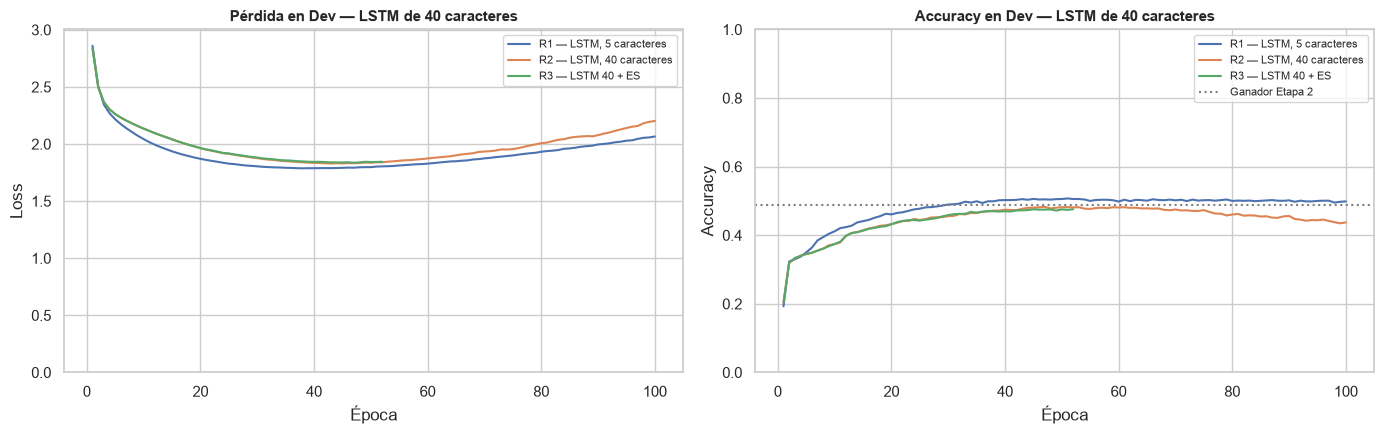

In [7]:
# ==============================================================================
# 3.2 LSTM DE 40 CARACTERES CON EARLY STOPPING (clipnorm y Early Stopping, 5 semillas)
# ==============================================================================
LR_LSTM = LR  # el learning rate elegido en la Etapa 2
CLIPNORM = 1.0
R3 = "R3 — LSTM 40 + ES"

if R3 not in resultados:
    resultados[R3], historiales[R3], modelos[R3] = evaluar(
        lambda: construir_modelo("lstm", k=L, **cfg_emb), k=L, lr=LR_LSTM, clipnorm=CLIPNORM, use_es=True, patience=5)
    resultados[R3]["config_lstm"] = {"emb": cfg_emb, "dropout": DROPOUT, "lr": LR_LSTM, "clipnorm": CLIPNORM, "es_patience": 5}
r = resultados[R3]
print(f"  {R3:<26} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
      f"brecha {r['brecha_mean']*100:.2f} pp | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.0f} s por corrida")

display(tabla(["R1 — LSTM, 5 caracteres", "R2 — LSTM, 40 caracteres", R3]))
graficar_curvas(["R1 — LSTM, 5 caracteres", "R2 — LSTM, 40 caracteres", R3], "LSTM de 40 caracteres")

**Interpretación.**
- **Cortar a tiempo recupera parte de lo que perdía R2.** R3 sube de $45,06\%$ a $47,76\% \pm 0,55\%$ ($+2,70$ pp), con un desvío entre semillas tres veces menor ($0,55$ contra $1,70$ pp), y la brecha cae de $27,41$ a $9,20$ pp. Entrena 53 épocas en promedio y tarda $284$ s por corrida, contra $583$ s de R2.
- **Pero no alcanza a la LSTM de 5 caracteres:** queda $1,93$ pp por debajo de R1. Como R1 y R3 no se entrenaron igual, todavía no sabemos si la diferencia viene del contexto o del esquema; eso lo separa la sección 3.3.

### 3.3 Control: la LSTM de 5 caracteres con el mismo esquema
R1 y R3 no se entrenaron igual: R1 usó la configuración heredada (learning rate fijo y 100 épocas) y R3, `clipnorm` y Early Stopping. Comparadas así, no se puede saber si la diferencia viene del largo del contexto o del esquema de entrenamiento. Para aislar el contexto, entrenamos la LSTM de 5 caracteres con el mismo esquema que R3 (Dropout $0,05$, embedding de 300 dimensiones, learning rate de $0,0005$, `clipnorm=1.0` y Early Stopping con paciencia 5). Este modelo es **R4**.

  R4 — LSTM 5 + ES               Dev: 50.07% ± 0.54% | brecha 10.43 pp | 47 épocas | 45 s por corrida
  Ganancia sobre R1: +0.38 pp (desvío de R1: 0.12 pp)
  Diferencia con R3 (40 caracteres, mismo esquema): +2.31 pp


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
R4 — LSTM 5 + ES,"247,104",50.07% ± 0.54%,49.34%,+1.36 pp,60.50%,10.43 pp,1.7774,5.91,50.49% (43),47
R3 — LSTM 40 + ES,"247,104",47.76% ± 0.55%,47.22%,-0.94 pp,56.96%,9.20 pp,1.8174,6.16,48.01% (50),53


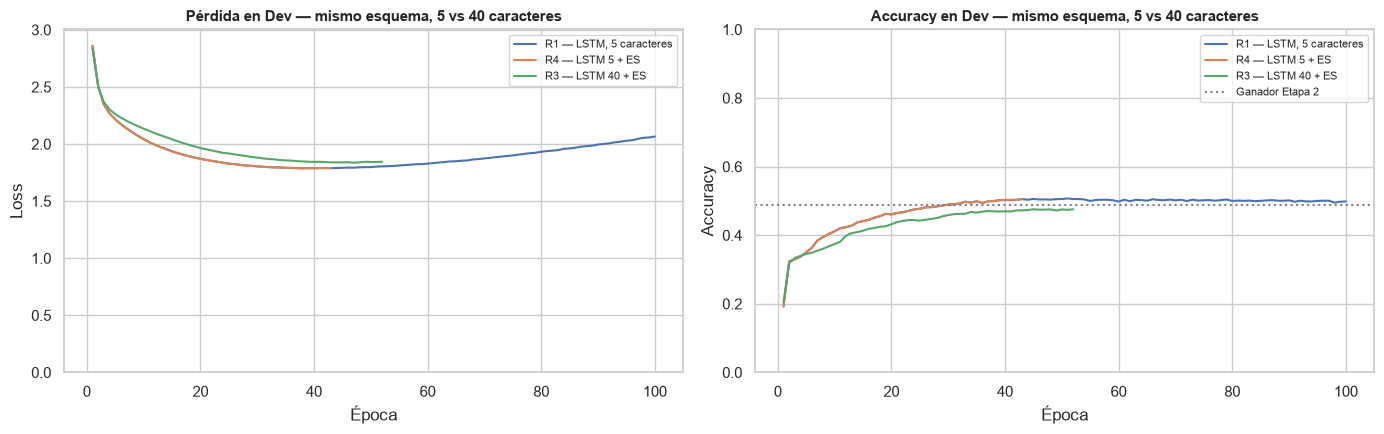

In [8]:
# ==============================================================================
# 3.3 CONTROL: LSTM DE 5 CARACTERES CON EL ESQUEMA DE R3 (5 semillas)
# ==============================================================================
R4 = "R4 — LSTM 5 + ES"
if R4 not in resultados:
    resultados[R4], historiales[R4], modelos[R4] = evaluar(
        lambda: construir_modelo("lstm", k=K, **cfg_emb), k=K, lr=LR_LSTM, clipnorm=CLIPNORM, use_es=True, patience=5)
    resultados[R4]["config_lstm"] = {"emb": {k: v for k, v in cfg_emb.items() if k != "emb_init"},
                                     "dropout": DROPOUT, "lr": LR_LSTM, "clipnorm": CLIPNORM, "es_patience": 5}
r = resultados[R4]
print(f"  {R4:<30} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
      f"brecha {r['brecha_mean']*100:.2f} pp | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.0f} s por corrida")
print(f"  Ganancia sobre R1: {(r['dev_acc_mean'] - resultados['R1 — LSTM, 5 caracteres']['dev_acc_mean'])*100:+.2f} pp "
      f"(desvío de R1: {resultados['R1 — LSTM, 5 caracteres']['dev_acc_std']*100:.2f} pp)")
print(f"  Diferencia con R3 (40 caracteres, mismo esquema): {(r['dev_acc_mean'] - resultados[R3]['dev_acc_mean'])*100:+.2f} pp")

comparadas_33 = ["R1 — LSTM, 5 caracteres", R4, R3]
display(tabla(comparadas_33))
graficar_curvas(comparadas_33, "mismo esquema, 5 vs 40 caracteres")

**Interpretación.**
- **R4 es R1 cortado a tiempo.** Es el mismo modelo con el mismo learning rate, y en las curvas de la semilla 42 los dos van casi superpuestos hasta que Early Stopping corta a R4 (47 épocas en promedio) y recupera los pesos de menor pérdida en Dev.
- **En accuracy, R4 y R1 empatan:** $50,07\% \pm 0,54\%$ contra $49,69\% \pm 0,12\%$. La diferencia ($+0,38$ pp) es menor que el desvío de R4.
- **En todo lo demás, R4 es mejor:** la brecha baja de $28,67$ a $10,43$ pp, la perplejidad de $7,64$ a $5,91$ (la mejor de la etapa) y el tiempo de $100$ a $45$ s por corrida. R1 llega a la época 100 con las probabilidades peor repartidas, aunque siga acertando el primer puesto casi igual.
- **Con el mismo esquema, el contexto corto gana:** R4 supera a R3 por $2,31$ pp. Con un learning rate de $0,005$ pasa lo mismo ($49,20\%$ contra $48,40\%$). Con unas 12.800 ventanas de Train, los 35 caracteres extra no se aprovechan.

---
# 4. Comparación con la Etapa 2
El **modelo ganador de la Etapa 3** es el de mayor accuracy media en Dev entre todos los de las secciones 2 y 3. Reportamos su mejora sobre el ganador de la Etapa 2 y sobre el baseline.

In [ ]:
# ==============================================================================
# 4.1 TABLA FINAL Y MEJORA SOBRE LA ETAPA 2
# ==============================================================================
GANADOR3 = max(resultados, key=lambda n: resultados[n]["dev_acc_mean"])
r3 = resultados[GANADOR3]

print(f"Ganador de la Etapa 3: {GANADOR3}")
print(f"  • Dev: {r3['dev_acc_mean']*100:.2f}% ± {r3['dev_acc_std']*100:.2f}% (peor semilla {r3['dev_acc_min']*100:.2f}%)")
print(f"  • Mejora sobre el ganador de la Etapa 2 ({ref2['dev_acc_mean']*100:.2f}%): {(r3['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp")
print(f"  • Mejora sobre el baseline ({ref_base['accuracy_dev']*100:.2f}%): {(r3['dev_acc_mean'] - ref_base['accuracy_dev'])*100:+.2f} pp\n")
display(tabla(list(resultados)))

with open(PROC / "resultados_etapa3.json", "w", encoding="utf-8") as f:
    json.dump({"config": {"lr": LR, "dropout": DROPOUT, "lr_lstm_es": LR_LSTM, "clipnorm": CLIPNORM, "epocas": EPOCAS, "batch": BATCH, "K": K, "L": L},
               "referencia_etapa2": {"modelo": reg2["ganador"], "dev_acc_mean": ref2["dev_acc_mean"]},
               "resultados": resultados, "mejor_embedding": MEJOR_EMB,
               "ganador": GANADOR3},
              f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_etapa3.json")

Ganador de la Etapa 3: R4 — LSTM 5 + ES
  • Dev: 50.07% ± 0.54% (peor semilla 49.34%)
  • Mejora sobre el ganador de la Etapa 2 (48.71%): +1.36 pp
  • Mejora sobre el baseline (40.83%): +9.24 pp



,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E1 — Desde cero, 16 dim.","23,840",47.88% ± 0.73%,47.05%,-0.83 pp,57.99%,10.11 pp,1.8739,6.51,48.21% (95),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100
R3 — LSTM 40 + ES,"247,104",47.76% ± 0.55%,47.22%,-0.94 pp,56.96%,9.20 pp,1.8174,6.16,48.01% (50),53
R4 — LSTM 5 + ES,"247,104",50.07% ± 0.54%,49.34%,+1.36 pp,60.50%,10.43 pp,1.7774,5.91,50.49% (43),47


Resultados guardados en data/processed/resultados_etapa3.json


---
# 5. Consigna 4.3.B: Qué ejemplos siguen siendo difíciles
Comparamos el ganador de la Etapa 3 con el modelo de la Etapa 2 (E0), ambos con la semilla 42, de tres formas:
1. **Accuracy por tipo de carácter**, con las mismas categorías de la Etapa 2.
2. **Accuracy según la posición dentro de la palabra:** cuántos caracteres de la palabra actual ya se vieron. La posición 0 es predecir la primera letra de una palabra nueva, justo después de un espacio.
3. **10 errores concretos** del ganador, dos por tipo de carácter, con sus 5 predicciones más probables.

,Casos en Dev,E0 — One-hot (Etapa 2),R4 — LSTM 5 + ES,Δ (pp)
espacio,514,0.8930,0.9066,1.3619
vocal,817,0.4223,0.4247,0.2448
consonante,1451,0.4197,0.4266,0.6892
mayúscula,38,0.1579,0.1579,0.0000
puntuación/dígito,60,0.0500,0.0333,-1.6667


,Casos en Dev,E0 — One-hot (Etapa 2),R4 — LSTM 5 + ES,Δ (pp)
0,511,0.1859,0.1977,1.1742
1,513,0.4834,0.5224,3.8986
2,487,0.5380,0.5339,-0.4107
3,429,0.6247,0.6247,0.0000
4,294,0.5748,0.5306,-4.4218
5+,646,0.5882,0.5991,1.0836


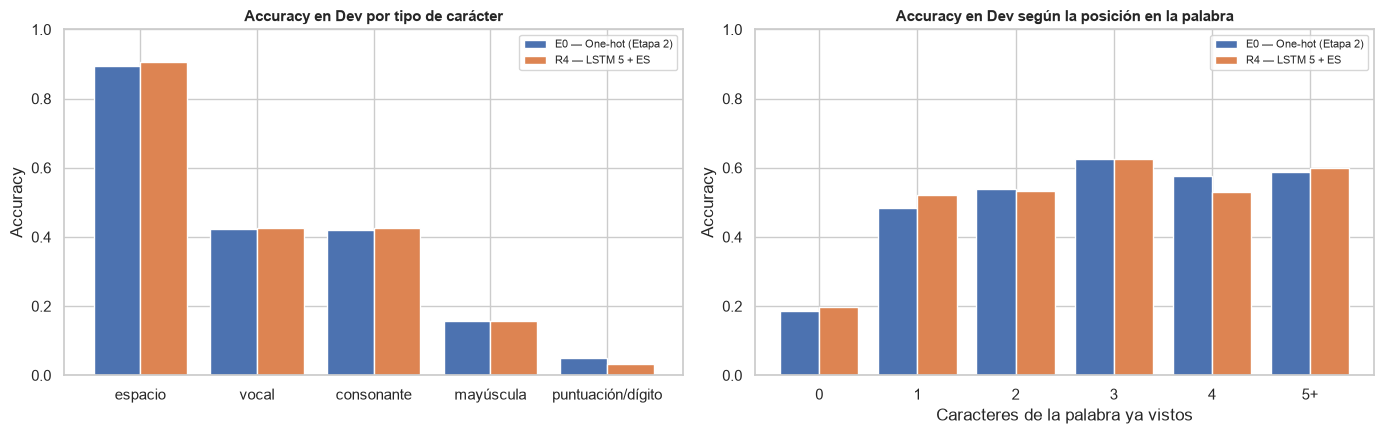

In [10]:
# ==============================================================================
# 5.1 ACCURACY POR TIPO DE CARÁCTER Y POR POSICIÓN EN LA PALABRA
# ==============================================================================
TIPOS_CHAR = ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"]

def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

def posicion_en_palabra(ctx):
    """Caracteres de la palabra actual ya vistos (0 = el contexto termina en espacio)."""
    p = len(ctx) - 1 - ctx.rfind(" ")
    return str(p) if p < 5 else "5+"

def proba(nombre):
    k = resultados[nombre]["k"]
    return modelos[nombre].predict(Xi_dev[:, -k:], verbose=0)

tipos_dev = np.array([tipo_caracter(c) for c in y_dev])
pos_dev = np.array([posicion_en_palabra(x) for x in X_dev])
POSICIONES = ["0", "1", "2", "3", "4", "5+"]

comparados = list(dict.fromkeys(["E0 — One-hot (Etapa 2)", GANADOR3]))
aciertos = {n: proba(n).argmax(axis=1) == yi_dev for n in comparados}

def acc_por_grupo(grupos, orden):
    df = pd.DataFrame({"Casos en Dev": pd.Series(grupos).value_counts().reindex(orden)})
    for n in comparados:
        df[n] = [aciertos[n][grupos == g].mean() for g in orden]
    if len(comparados) == 2:
        df["Δ (pp)"] = (df[comparados[1]] - df[comparados[0]]) * 100
    return df

df_tipo = acc_por_grupo(tipos_dev, TIPOS_CHAR)
df_pos = acc_por_grupo(pos_dev, POSICIONES)
display(df_tipo.round(4))
display(df_pos.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df_tipo[comparados].plot.bar(ax=axes[0], rot=0, width=0.8)
df_pos[comparados].plot.bar(ax=axes[1], rot=0, width=0.8)
axes[0].set_title("Accuracy en Dev por tipo de carácter", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy en Dev según la posición en la palabra", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Caracteres de la palabra ya vistos")
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Accuracy")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
# ==============================================================================
# 5.2 DIEZ ERRORES CONCRETOS DEL GANADOR (dos por tipo de carácter)
# ==============================================================================
P_gan = proba(GANADOR3)
pred_gan = P_gan.argmax(axis=1)
errores = np.where(pred_gan != yi_dev)[0]
rng_ej = np.random.default_rng(SEED)

filas_ej = []
for t in TIPOS_CHAR:
    idx_t = errores[tipos_dev[errores] == t]
    for i in rng_ej.choice(idx_t, size=min(2, len(idx_t)), replace=False):
        orden = np.argsort(P_gan[i])[::-1]
        filas_ej.append({
            "Tipo real": t,
            "Contexto (últimos 30)": "..." + X_dev[i][-30:],
            "Real": vis(y_dev[i]),
            "Predicho": vis(idx2char[pred_gan[i]]),
            "Puesto del real": int(np.where(orden == yi_dev[i])[0][0]) + 1,
            "P(real)": round(float(P_gan[i, yi_dev[i]]), 3),
            "Top-5": " | ".join(f"{vis(idx2char[j])} {P_gan[i, j]:.2f}" for j in orden[:5]),
        })

pd.set_option("display.max_colwidth", 60)
display(pd.DataFrame(filas_ej))
print(f"Errores del ganador en Dev: {len(errores)} de {len(yi_dev)} ({len(errores)/len(yi_dev)*100:.2f}%)")

,Tipo real,Contexto (últimos 30),Real,Predicho,Puesto del real,P(real),Top-5
0,espacio,...isting willows writhed against,<SP>,o,4,0.067,o 0.45 | r 0.12 | i 0.07 | <SP> 0.07 | a 0.05
1,espacio,"...bench, so that I could not see",<SP>,n,8,0.019,n 0.42 | m 0.17 | t 0.11 | p 0.08 | c 0.06
2,vocal,...e; and though he made signs th,a,e,2,0.242,e 0.59 | a 0.24 | o 0.07 | i 0.06 | r 0.03
3,vocal,...eassured me; and though he mad,e,<SP>,2,0.241,<SP> 0.41 | e 0.24 | k 0.04 | i 0.04 | n 0.04
4,consonante,...he blasphemous book in my hand,s,<SP>,4,0.041,"<SP> 0.57 | e 0.13 | , 0.10 | s 0.04 | i 0.03"
5,consonante,...had called me to the old town,b,s,6,0.051,s 0.14 | a 0.12 | w 0.11 | t 0.08 | d 0.06
6,mayúscula,...d the first stars of evening.,A,T,3,0.089,T 0.28 | I 0.21 | A 0.09 | W 0.08 | S 0.05
7,mayúscula,...us and wax tablet he carried.,H,T,14,0.009,T 0.34 | I 0.19 | A 0.11 | W 0.06 | B 0.04
8,puntuación/dígito,...sed in a loose antique costume,",",<SP>,6,0.043,<SP> 0.41 | d 0.24 | l 0.09 | n 0.08 | s 0.05
9,puntuación/dígito,... was certainly nervous waiting,",",<SP>,2,0.055,"<SP> 0.87 | , 0.06 | s 0.02 | . 0.01 | ; 0.01"


Errores del ganador en Dev: 1440 de 2880 (50.00%)


**Interpretación.** Los números por tipo y por posición son de un solo modelo (semilla 42), así que diferencias de un par de puntos no son concluyentes.
- **El primer carácter de cada palabra es el problema principal.** En la posición 0 los dos modelos aciertan menos del $20\%$ ($18,59\%$ y $19,77\%$); desde la segunda letra superan el $48\%$. Adivinar qué palabra viene es mucho más difícil que completar una palabra ya empezada.
- **R4 y E0 casi no se diferencian por tipo:** las diferencias van de $-1,67$ a $+1,36$ pp. En puntuación, $-1,67$ pp es un acierto menos sobre 60 casos. Por posición, R4 gana $3,90$ pp en la segunda letra y pierde $4,42$ pp en la quinta.
- **Mayúsculas y puntuación siguen casi sin resolverse:** $15,79\%$ y $3,33\%$, con 38 y 60 casos.
- **Los 10 errores muestran tres patrones:**
  1. **No saber si la palabra terminó.** En `against` y `see` el modelo apuesta a que la palabra sigue (`o`, `n`); en `mad` (de *made*) y `hand` (de *hands*) apuesta al espacio y la palabra seguía.
  2. **Elegir entre continuaciones posibles.** En `signs th` le da $59\%$ a `e` (*the*) y $24\%$ a la real, `a` (*that*). Al empezar la palabra que sigue a `old town`, reparte la probabilidad entre muchas letras y ninguna pasa del $14\%$. Con 5 caracteres, varias respuestas son razonables.
  3. **Mayúsculas y comas.** Después de un punto sabe que viene una mayúscula (`T`, `I` y `A` encabezan su top-5), pero no cuál. En `waiting` le da $87\%$ al espacio y $6\%$ a la coma: sin ver la estructura de la oración, el espacio es mucho más probable.
- **Diagnóstico:** el ganador falla en el $50,00\%$ de Dev. Los patrones 1 y 3 necesitan más contexto que 5 caracteres, que es lo que buscaba la LSTM de 40, pero con este volumen de datos no logró aprovecharlo (secciones 3.2 y 3.3). El patrón 2 no se resuelve con más contexto inmediato.

---
# 6. Qué aprendieron los embeddings
Proyectamos a 2 dimensiones (PCA) los vectores que aprendió para cada carácter el mejor modelo desde cero. Si los caracteres del mismo tipo quedan cerca, el embedding captura algo de su función en el texto.

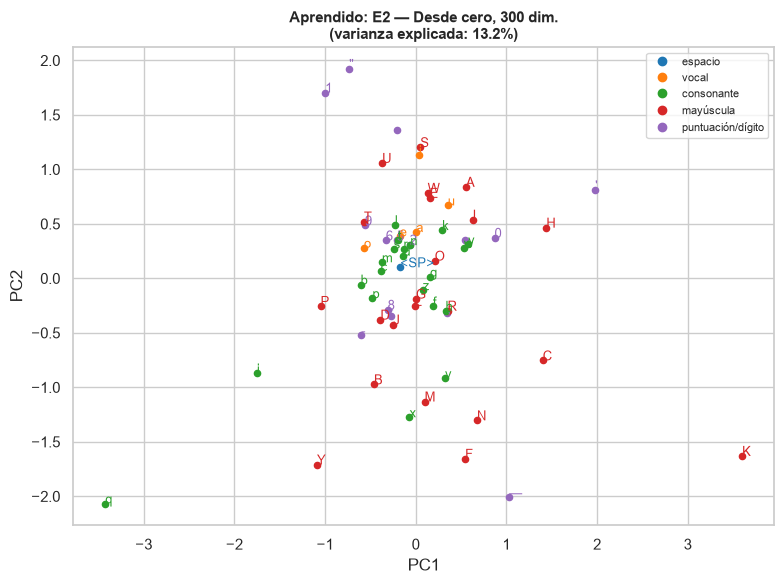

In [12]:
# ==============================================================================
# 6.1 PCA DE LOS EMBEDDINGS
# ==============================================================================
desde_cero = max(["E1 — Desde cero, 16 dim.", "E2 — Desde cero, 300 dim."], key=lambda n: resultados[n]["dev_acc_mean"])
M = modelos[desde_cero].get_layer("embedding").get_weights()[0]
colores = dict(zip(TIPOS_CHAR, sns.color_palette("tab10", len(TIPOS_CHAR))))

fig, ax = plt.subplots(figsize=(8, 6))
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(M)
for c, i in char2idx.items():
    t = tipo_caracter(c)
    ax.scatter(Z[i, 0], Z[i, 1], color=colores[t], s=20)
    ax.annotate(vis(c), (Z[i, 0], Z[i, 1]), fontsize=9, color=colores[t])
ax.set_title(f"Aprendido: {desde_cero}\n(varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)", fontsize=11, fontweight="bold")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
handles = [plt.Line2D([], [], marker="o", ls="", color=colores[t], label=t) for t in TIPOS_CHAR]
ax.legend(handles=handles, fontsize=8, loc="best")
plt.tight_layout()
plt.show()

**Interpretación.**
- **Aprendido desde cero (E2):** los 2 componentes explican solo el $13,2\%$ de la varianza, así que la información está repartida en muchas dimensiones y el gráfico muestra una parte chica. Aun así, las letras ya no se superponen: las minúsculas frecuentes se agrupan en el centro y las mayúsculas y los signos, que aparecen pocas veces en Train, quedan más dispersos.
- **Conclusión:** el embedding aprendido separa las letras entre sí; los caracteres poco frecuentes quedan lejos del grupo central.

---
# 7. Conclusiones de la Etapa 3

1. **Ganador: R4 — LSTM de 5 caracteres con Early Stopping**, con $50,07\% \pm 0,54\%$ en Dev (peor semilla: $49,34\%$): **$+1,36$ pp sobre la Etapa 2** ($48,71\%$) y $+9,24$ pp sobre el baseline. Es R1 cortado a tiempo: en accuracy empatan, pero R4 tiene menos brecha ($10,43$ contra $28,67$ pp), mejor perplejidad ($5,91$ contra $7,64$) y tarda la mitad.
2. **Embeddings de caracteres desde cero:** pasar del one-hot a un embedding aprendido mejora poco ($+0,81$ pp con 300 dimensiones). El tamaño del embedding mueve sobre todo el balance entre acierto y sobreajuste.
3. **Embeddings de palabras, pre-entrenados vs desde cero (sección 8):** GloVe mejora la predicción de la siguiente palabra en unos 3 pp de accuracy top-1 en promedio, aunque con mucho desvío entre semillas. Desde cero, con tan pocas palabras, el modelo casi no aprende más que la frecuencia.
4. **Contexto largo:** la LSTM de 40 caracteres sobreajusta con la configuración heredada (R2, $45,06\%$). Con Early Stopping (R3) sube a $47,76\%$, pero con el mismo esquema la de 5 caracteres la supera por $2,31$ pp.
5. **Dónde sigue fallando:** el primer carácter de cada palabra (menos del $20\%$), las mayúsculas y la puntuación.
6. **Para la Etapa 5:** R4 tiene 247.104 parámetros entrenables y tarda unos 45 s por corrida en CPU.

### 7.1 Registro de experimentos que no funcionaron

| Experimento | Resultado en Dev | Por qué no funcionó |
|---|---|---|
| E1 — Embedding desde cero de 16 dim. | $47,88\% \pm 0,73\%$ | menos capacidad que el one-hot ($-0,83$ pp), aunque con menos sobreajuste |
| R2 — LSTM de 40 caracteres | $45,06\% \pm 1,70\%$ | sobreajusta con la configuración heredada; tarda $583$ s por corrida |
| R3 — LSTM 40 + ES | $47,76\% \pm 0,55\%$ | corrige parte del sobreajuste, pero queda $2,31$ pp debajo de R4 con el mismo esquema |
| Sección 8 — Early Stopping en palabras | ver sección 8 | corta por pérdida antes de que la accuracy deje de subir |

Lo que probamos y sacamos del notebook (ReduceLROnPlateau, embeddings de caracteres pre-entrenados, variantes regularizadas de R3 y el learning rate de $0,005$) está registrado en `experimentos/README.md`.

In [13]:
# ==============================================================================
# 7.2 CHECKLIST DE CUMPLIMIENTO - ETAPA 3
# ==============================================================================
print("=" * 80)
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 3 (UNAB 2026)")
print("=" * 80)
print(f"  [x] 4.3.B Embeddings de caracteres desde cero (16 y 300 dim.) contra el one-hot de la Etapa 2.")
print(f"  [x] 4.3.B Red densa sobre embeddings (misma arquitectura que la Etapa 2).")
print(f"  [x] 4.3.B Modelo de lenguaje simple: LSTM con 5 y {L} caracteres de contexto; las dos con Early Stopping y clipnorm.")
print(f"  [x] 4.3.B Comparación pre-entrenados vs desde cero con embeddings de palabras (GloVe, sección 8; 5 semillas por modelo).")
print(f"  [x] 4.3.B Ejemplos difíciles: {len(filas_ej)} errores concretos, accuracy por tipo y por posición en la palabra.")
print(f"  [x] Mejora sobre la Etapa 2: {GANADOR3} = {r3['dev_acc_mean']*100:.2f}% ({(r3['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp).")
print(f"  [x] Conjunto Test sin evaluar hasta la Etapa 5.")
print("=" * 80)

CHECKLIST DE CUMPLIMIENTO - ETAPA 3 (UNAB 2026)
  [x] 4.3.B Embeddings de caracteres desde cero (16 y 300 dim.) contra el one-hot de la Etapa 2.
  [x] 4.3.B Red densa sobre embeddings (misma arquitectura que la Etapa 2).
  [x] 4.3.B Modelo de lenguaje simple: LSTM con 5 y 40 caracteres de contexto; las dos con Early Stopping y clipnorm.
  [x] 4.3.B Comparación pre-entrenados vs desde cero con embeddings de palabras (GloVe, sección 8; 5 semillas por modelo).
  [x] 4.3.B Ejemplos difíciles: 10 errores concretos, accuracy por tipo y por posición en la palabra.
  [x] Mejora sobre la Etapa 2: R4 — LSTM 5 + ES = 50.07% (+1.36 pp).
  [x] Conjunto Test sin evaluar hasta la Etapa 5.


---
# 8. Consigna 4.3.B: Embeddings de palabras pre-entrenados vs desde cero
La consigna 4.3.B pide **embeddings de palabras** y comparar **pre-entrenados vs entrenados desde cero**. Nuestra tarea principal es a nivel de carácter, y GloVe no tiene vectores de caracteres. Para hacer esa comparación sumamos un experimento aparte: **predecir la siguiente palabra** a partir de las palabras anteriores, con una red densa sobre embeddings de palabras.

**Este experimento no compite con el resto de la etapa.** Es otra tarea (otra salida, otra cantidad de clases), así que su accuracy no se compara con la de caracteres ni entra en la elección del ganador ni en la Etapa 5.

### Decisiones
1. **Tokens:** pasamos el texto limpio a minúsculas y lo cortamos en palabras, signos de puntuación y números. El posesivo se separa (`hill's` → `hill` + `'s`), igual que en el corpus con el que se entrenó GloVe, así más palabras encuentran su vector.
2. **Misma partición por bloques de la Etapa 1:** cortamos en palabras cada bloque por separado, y las ventanas se arman solo dentro de cada bloque. Una palabra que cruza el borde entre dos bloques queda partida en dos, un efecto mínimo con 50 bloques. Así no hay fuga entre Train y Dev, por la misma razón que en la Etapa 1.
3. **Contexto de $N = 3$ palabras:** el corpus tiene unos 4.000 tokens, así que contextos más largos casi no se repiten entre Train y Dev.
4. **Vocabulario de salida:** las palabras de Train más un token `<UNK>` para las que no aparecen en Train. Una palabra de Dev que no está en Train **cuenta siempre como error**, aunque el modelo prediga `<UNK>`: no tiene sentido premiar "acertar que no se sabe".
5. **Pre-entrenados:** GloVe 6B de 100 dimensiones (Wikipedia 2014 + Gigaword 5, 400.000 palabras en minúsculas; Pennington, Socher y Manning, 2014). Los tokens sin vector arrancan al azar, con la misma escala que el resto.
6. **Tres modelos con la misma red densa de las secciones anteriores** (Dense 128 → 64 → 32 con ReLU y Dropout), 5 semillas cada uno:

| Modelo | Embedding de cada palabra |
|---|---|
| **P0 — Desde cero** | 100 dim., aprendido junto con la red |
| **P1 — GloVe congelado** | vectores de GloVe fijos |
| **P2 — GloVe ajustable** | vectores de GloVe como punto de partida, ajustados durante el entrenamiento |

7. **Early Stopping en los tres** (paciencia 5 sobre `val_loss`, con los mejores pesos): con unas 2.800 ventanas de entrenamiento y 1.000 clases, sin cortar el entrenamiento los tres sobreajustan enseguida. Aplicarlo a todos mantiene la comparación pareja.
8. **Métricas:** accuracy top-1 en Dev, como en el resto del TP, y accuracy **top-5** (el real está entre las 5 palabras más probables), porque con tantas clases la top-1 es muy baja. Como referencia, predecir siempre la palabra más frecuente de Train.

In [14]:
# ==============================================================================
# 8.1 TOKENIZACIÓN EN PALABRAS Y VENTANAS POR BLOQUES
# ==============================================================================
import re
import zipfile

N_PAL = 3            # Palabras de contexto
DIM_PAL = 100        # Dimensión de los embeddings de palabras
UNK = "<UNK>"

# Palabras, sufijos con apóstrofo ('s), números o un signo suelto
patron = re.compile(r"[a-z]+|'[a-z]+|[0-9]+|[^\sa-z0-9]")

# Cada bloque de la Etapa 1 se corta en palabras por separado: así cada palabra queda en un solo conjunto
tokens_por_bloque = {b: patron.findall(text[ini:fin].lower()) for b, (ini, fin) in enumerate(limites)}
n_tokens = sum(len(t) for t in tokens_por_bloque.values())

def ventanas_palabras(ids):
    X, y = [], []
    for b in ids:
        toks = tokens_por_bloque.get(b, [])
        for i in range(N_PAL, len(toks)):
            X.append(toks[i - N_PAL:i])
            y.append(toks[i])
    return X, y

Xp_train, yp_train = ventanas_palabras(bloques_split["train"])
Xp_dev,   yp_dev   = ventanas_palabras(bloques_split["dev"])

# Vocabulario: palabras de Train (contexto y objetivo) más <UNK>
vocab_pal = [UNK] + sorted({t for b in bloques_split["train"] for t in tokens_por_bloque.get(b, [])})
pal2idx = {p: i for i, p in enumerate(vocab_pal)}
VP = len(vocab_pal)
a_idx = lambda toks: [pal2idx.get(t, 0) for t in toks]

Xpi_train = np.array([a_idx(x) for x in Xp_train], dtype=np.int32)
Xpi_dev   = np.array([a_idx(x) for x in Xp_dev], dtype=np.int32)
ypi_train = np.array(a_idx(yp_train), dtype=np.int32)
ypi_dev   = np.array(a_idx(yp_dev), dtype=np.int32)

frec_pal = Counter(yp_train)
mas_frec = frec_pal.most_common(1)[0][0]
oov_dev = float(np.mean(ypi_dev == 0))
acc_mayoritaria_pal = float(np.mean(np.array(yp_dev) == mas_frec))

print(f"Tokens en el texto: {n_tokens:,} | vocabulario de Train: {VP - 1:,} palabras + <UNK>")
print(f"Ventanas de {N_PAL} palabras -> Train: {len(Xp_train):,} | Dev: {len(Xp_dev):,}")
print(f"Palabras de Dev que no aparecen en Train: {oov_dev*100:.1f}% (techo de accuracy: {(1-oov_dev)*100:.1f}%)")
print(f"Referencia: predecir siempre '{mas_frec}' -> {acc_mayoritaria_pal*100:.2f}% en Dev")
print(f"Ejemplo: {Xp_train[0]} -> {yp_train[0]!r}")

Tokens en el texto: 4,087 | vocabulario de Train: 999 palabras + <UNK>
Ventanas de 3 palabras -> Train: 2,777 | Dev: 616
Palabras de Dev que no aparecen en Train: 25.2% (techo de accuracy: 74.8%)
Referencia: predecir siempre 'the' -> 7.63% en Dev
Ejemplo: ['e', 'tongue', 'of'] -> 'the'


In [15]:
# ==============================================================================
# 8.2 CARGA DE GLOVE 6B (100 dim.) Y COBERTURA DEL VOCABULARIO
# ==============================================================================
URL_GLOVE = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"  # mirror oficial de Stanford NLP
RUTA_GLOVE = BASE_DIR / "data" / "external" / "glove.6B.zip"
if not RUTA_GLOVE.exists():
    # Descarga única de unos 860 MB
    RUTA_GLOVE.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_GLOVE, RUTA_GLOVE)

# Leemos el archivo dentro del zip y guardamos solo los vectores de nuestro vocabulario
glove = {}
with zipfile.ZipFile(RUTA_GLOVE) as z, z.open(f"glove.6B.{DIM_PAL}d.txt") as f:
    for linea in f:
        partes = linea.decode("utf-8").rstrip().split(" ")
        if partes[0] in pal2idx:
            glove[partes[0]] = np.array(partes[1:], dtype=np.float32)

rng_pal = np.random.default_rng(SEED)
escala_pal = np.std(np.stack(list(glove.values())))
E_glove = np.zeros((VP, DIM_PAL), dtype=np.float32)
sin_vector_pal = []
for p, i in pal2idx.items():
    if p in glove:
        E_glove[i] = glove[p]
    else:
        E_glove[i] = rng_pal.normal(0, escala_pal, DIM_PAL)
        sin_vector_pal.append(p)

cubiertos = sum(frec_pal[p] for p in glove) / sum(frec_pal.values())
print(f"Palabras del vocabulario con vector de GloVe: {len(glove):,} de {VP - 1:,}")
print(f"Objetivos de Train cubiertos por GloVe: {cubiertos*100:.1f}%")
print(f"Sin vector (primeras 15): {[p for p in sin_vector_pal if p != UNK][:15]}")

Palabras del vocabulario con vector de GloVe: 959 de 999
Objetivos de Train cubiertos por GloVe: 98.9%
Sin vector (primeras 15): ["'clock", 'amorphously', 'chimneypots', 'creakin', 'daemonolatreia', 'eckoning', 'feastings', 'footworn', 'fungous', 'glanvil', 'hastes', 'hearthside', 'hispered', 'lichened', 'loathsomely']


  P0 — Desde cero        Dev top-1: 8.08% ± 1.02% | top-5: 23.54% | 11 épocas | 2.7 s por corrida


  P1 — GloVe congelado   Dev top-1: 10.81% ± 2.84% | top-5: 25.49% | 11 épocas | 2.6 s por corrida


  P2 — GloVe ajustable   Dev top-1: 11.72% ± 2.76% | top-5: 25.58% | 11 épocas | 2.7 s por corrida

Referencia (siempre 'the'): 7.63% | techo por palabras nuevas: 74.8%


,Parámetros entrenables,Dev top-1 (μ ± σ),Dev top-5 (μ ± σ),Train top-1,Brecha,Perplejidad,Épocas
Modelo,,,,,,,
P0 — Desde cero,"181,864",8.08% ± 1.02%,23.54% ± 0.00%,7.16%,-0.93 pp,443.4,11
P1 — GloVe congelado,"81,864",10.81% ± 2.84%,25.49% ± 1.57%,10.04%,-0.77 pp,516.2,11
P2 — GloVe ajustable,"181,864",11.72% ± 2.76%,25.58% ± 1.45%,10.79%,-0.93 pp,503.8,11


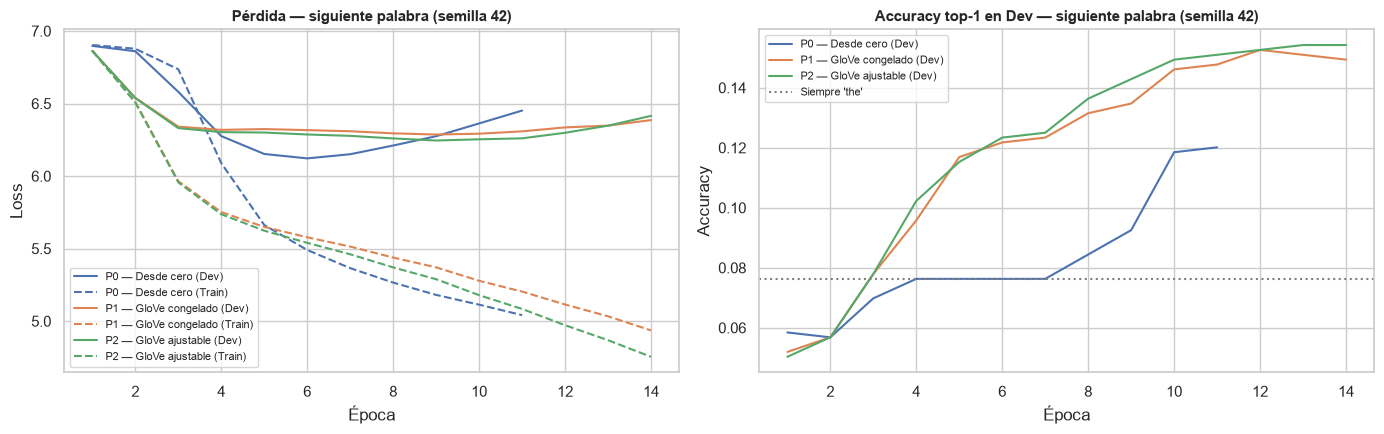

In [16]:
# ==============================================================================
# 8.3 RED DENSA SOBRE EMBEDDINGS DE PALABRAS (5 semillas)
# ==============================================================================
def construir_red_palabras(emb_init=None, emb_trainable=True, dropout=DROPOUT):
    """Embedding de palabras -> Flatten -> MLP 128-64-32 -> softmax sobre el vocabulario."""
    entrada = layers.Input(shape=(N_PAL,), dtype="int32")
    init = keras.initializers.Constant(emb_init) if emb_init is not None else "uniform"
    x = layers.Embedding(VP, DIM_PAL, embeddings_initializer=init, trainable=emb_trainable, name="embedding")(entrada)
    x = layers.Flatten()(x)
    for u in [128, 64, 32]:
        x = layers.Dense(u, activation="relu")(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    salida = layers.Dense(VP, activation="softmax")(x)
    return keras.Model(entrada, salida)

def acc_topk(P, y, k):
    """Accuracy top-k; una palabra fuera del vocabulario de Train (<UNK>) cuenta siempre como error."""
    # 1) En cada fila, las k columnas (palabras) de mayor probabilidad
    topk = np.argsort(P, axis=1)[:, ::-1][:, :k]
    # 2) ¿La palabra real está entre esas k? (y[:, None] la pone como columna para comparar fila por fila)
    en_topk = (topk == y[:, None]).any(axis=1)
    # 3) Una palabra que no está en Train (<UNK>, índice 0) cuenta siempre como error
    return float(np.mean(en_topk & (y != 0)))

def evaluar_palabras(constructor):
    corridas = []
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        modelo = constructor()
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        es = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        t0 = time.perf_counter()
        h = modelo.fit(Xpi_train, ypi_train, validation_data=(Xpi_dev, ypi_dev), epochs=EPOCAS,
                       batch_size=BATCH, callbacks=[es], verbose=0)
        t_run = time.perf_counter() - t0
        if s == SEED:
            h42, m42 = h.history, modelo
        P_tr, P_dv = modelo.predict(Xpi_train, verbose=0), modelo.predict(Xpi_dev, verbose=0)
        loss_dv = float(modelo.evaluate(Xpi_dev, ypi_dev, verbose=0)[0])
        corridas.append({"seed": s, "tiempo": t_run, "epocas": len(h.history["loss"]),
                         "train_acc": acc_topk(P_tr, ypi_train, 1), "dev_acc": acc_topk(P_dv, ypi_dev, 1),
                         "dev_top5": acc_topk(P_dv, ypi_dev, 5), "dev_loss": loss_dv, "dev_perp": float(np.exp(loss_dv))})
        corridas[-1]["brecha"] = corridas[-1]["train_acc"] - corridas[-1]["dev_acc"]
    df_c = pd.DataFrame(corridas)
    resumen = {"params": int(sum(np.prod(w.shape) for w in m42.trainable_weights)), "corridas": corridas}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    return resumen, h42, m42

MODELOS_PAL = {
    "P0 — Desde cero":       lambda: construir_red_palabras(),
    "P1 — GloVe congelado":  lambda: construir_red_palabras(emb_init=E_glove, emb_trainable=False),
    "P2 — GloVe ajustable":  lambda: construir_red_palabras(emb_init=E_glove, emb_trainable=True),
}
resultados_pal, historiales_pal, modelos_pal = {}, {}, {}
for nombre, constructor in MODELOS_PAL.items():
    resultados_pal[nombre], historiales_pal[nombre], modelos_pal[nombre] = evaluar_palabras(constructor)
    r = resultados_pal[nombre]
    print(f"  {nombre:<22} Dev top-1: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
          f"top-5: {r['dev_top5_mean']*100:.2f}% | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.1f} s por corrida")

df_pal = pd.DataFrame([{
    "Modelo": n, "Parámetros entrenables": f"{r['params']:,}",
    "Dev top-1 (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
    "Dev top-5 (μ ± σ)": f"{r['dev_top5_mean']*100:.2f}% ± {r['dev_top5_std']*100:.2f}%",
    "Train top-1": f"{r['train_acc_mean']*100:.2f}%", "Brecha": f"{r['brecha_mean']*100:.2f} pp",
    "Perplejidad": f"{r['dev_perp_mean']:.1f}", "Épocas": f"{r['epocas_mean']:.0f}",
} for n, r in resultados_pal.items()]).set_index("Modelo")
print(f"\nReferencia (siempre '{mas_frec}'): {acc_mayoritaria_pal*100:.2f}% | techo por palabras nuevas: {(1-oov_dev)*100:.1f}%")
display(df_pal)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n, h in historiales_pal.items():
    ep = range(1, len(h["loss"]) + 1)
    l = axes[0].plot(ep, h["val_loss"], label=f"{n} (Dev)")[0]
    axes[0].plot(ep, h["loss"], color=l.get_color(), linestyle="--", label=f"{n} (Train)")
    axes[1].plot(ep, h["val_accuracy"], color=l.get_color(), label=f"{n} (Dev)")
axes[1].axhline(acc_mayoritaria_pal, color="gray", linestyle=":", label=f"Siempre '{mas_frec}'")
axes[0].set_title("Pérdida — siguiente palabra (semilla 42)", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy top-1 en Dev — siguiente palabra (semilla 42)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
# ==============================================================================
# 8.4 VECINOS MÁS CERCANOS: QUÉ SABE CADA EMBEDDING
# ==============================================================================
def vecinos(E, palabra, n=5):
    """Las n palabras del vocabulario más parecidas (similitud coseno)."""
    En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    sim = En @ En[pal2idx[palabra]]
    orden = [j for j in np.argsort(sim)[::-1] if j not in (0, pal2idx[palabra])]
    return ", ".join(vocab_pal[j] for j in orden[:n])

E_cero = modelos_pal["P0 — Desde cero"].get_layer("embedding").get_weights()[0]
palabras_ej = [p for p in ["night", "old", "town", "sea", "dead", "candle"] if p in pal2idx]
display(pd.DataFrame({
    "GloVe (pre-entrenado)": {p: vecinos(E_glove, p) for p in palabras_ej},
    "Desde cero (P0, semilla 42)": {p: vecinos(E_cero, p) for p in palabras_ej},
}))

with open(PROC / "resultados_palabras.json", "w", encoding="utf-8") as f:
    json.dump({"config": {"N": N_PAL, "dim": DIM_PAL, "lr": LR, "dropout": DROPOUT, "batch": BATCH,
                          "epocas_max": EPOCAS, "es_patience": 5, "fuente_glove": URL_GLOVE},
               "datos": {"tokens": n_tokens, "vocabulario": VP - 1, "n_train": len(Xp_train), "n_dev": len(Xp_dev),
                         "oov_dev": oov_dev, "palabra_mas_frecuente": mas_frec, "acc_mayoritaria_dev": acc_mayoritaria_pal,
                         "con_vector_glove": len(glove)},
               "resultados": resultados_pal}, f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_palabras.json")

,GloVe (pre-entrenado),"Desde cero (P0, semilla 42)"
night,"before, time, last, when, on","back, at, its, be, squirming"
old,"man, father, one, woman, now","had, stuck, serpentine, the, outspread"
town,"near, where, outside, around, part","walls, founded, pillar, bare, table"
sea,"waters, water, fishing, shore, river","taverns, to, everything, not, remained"


Resultados guardados en data/processed/resultados_palabras.json


**Interpretación.**
- **Las palabras nuevas ponen un techo bajo.** El $25,2\%$ de las palabras de Dev no aparece en Train, así que ningún modelo puede pasar del $74,8\%$. La referencia de predecir siempre *the* da $7,63\%$.
- **P0, entrenado desde cero, casi no aprende:** $8,08\% \pm 1,02\%$. En 4 de las 5 semillas da exactamente $7,63\%$, lo mismo que predecir siempre *the*: Early Stopping recupera los pesos de una época en la que el modelo solo aprendió la palabra más frecuente. Con 2.777 ventanas y 999 palabras, la mayoría aparece pocas veces en Train. Sus vecinos no tienen relación de significado (*sea* → *taverns*, *to*, *everything*).
- **GloVe ayuda, pero con mucha variación.** P1 llega a $10,81\% \pm 2,84\%$ y P2 a $11,72\% \pm 2,76\%$ ($+2,73$ y $+3,64$ pp sobre P0), y el top-5 sube de $23,54\%$ a $25,49\%$ y $25,58\%$. Los desvíos son altos porque en algunas semillas también quedan cerca de *the*. GloVe tiene vector para 959 de las 999 palabras, y sus vecinos tienen sentido (*sea* → *waters*, *water*, *fishing*, *shore*, *river*).
- **Congelar o ajustar da lo mismo:** P2 supera a P1 por $0,91$ pp, dentro del desvío, y P1 entrena menos de la mitad de parámetros (81.864 contra 181.864).
- **Por qué con palabras sí:** una palabra tiene un significado que GloVe trae aprendido de un corpus de 6.000 millones de tokens; con pocos datos propios, eso es justo lo que falta.
- **Limitación: Early Stopping corta antes de tiempo.** Los tres modelos paran a las 11 épocas en promedio y recuperan la época de menor `val_loss`. En las curvas de la semilla 42, la pérdida en Dev toca su mínimo cerca de la época 6 (P0) y 9 (P1 y P2), pero la accuracy sigue subiendo: P1 y P2 llegan a cerca del $15\%$ entre las épocas 12 y 14, y P0 pasa de $7,6\%$ a $12\%$ entre las épocas 7 y 11. Por eso la accuracy en Train queda incluso por debajo de la de Dev, y las cifras de la tabla subestiman a los tres modelos.

---
---
# ETAPA 4: Modelo generativo (optativa)

No realizada. Es optativa y no entró en los tiempos del trabajo; queda como trabajo futuro (Etapa 5, sección 5).

---
---
# ETAPA 5: Cierre, evaluación final y análisis ético

**Plan de la etapa**
1. **Configuración y datos:** misma partición por bloques de la Etapa 1. Acá se arman por primera vez las ventanas de Test.
2. **Consigna 4.5.2, evaluación final en Test:** reentrenamos el ganador de la Etapa 3 con su misma configuración y las 5 semillas, verificamos que reproduce su accuracy en Dev y lo evaluamos en Test **una única vez**.
3. **Consigna 4.5.1, tabla comparativa:** todos los modelos del trabajo con arquitectura, parámetros, Dev, Test y tiempo. Va después de la sección 2 porque necesita el resultado en Test.
4. **Consigna 4.5.3, análisis ético y de sesgos:** sesgos del texto y desempeño por subgrupos en Test.
5. **Consigna 4.5.4, conclusiones.**

**Decisiones de diseño**
1. **Solo el ganador se evalúa en Test.** La consigna 4.5.2 pide evaluar *el mejor modelo* por primera y única vez. Los demás modelos de la tabla llevan solo su accuracy en Dev, leída de los resultados guardados de cada etapa.
2. **Reentrenar en lugar de guardar pesos.** Con las semillas fijas, el entrenamiento da exactamente los mismos números; lo verificamos contra el Dev de la Etapa 3 antes de mirar Test.
3. **Resultado en Test con 5 semillas:** media ± desvío, igual que en Dev, para que la comparación sea justa.

---
# 1. Configuración y datos

In [1]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import re
import json
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
SEEDS = [42, 123, 456, 789, 2026]
np.random.seed(SEED)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
# ==============================================================================
# 1.2 CARGA DEL TEXTO Y DE LA PARTICIÓN DE LA ETAPA 1 (incluye Test)
# ==============================================================================
PROC = BASE_DIR / "data" / "processed"

text = (PROC / "The_Festival_clean.txt").read_text(encoding="utf-8")
splits = json.load(open(PROC / "splits_bloques.json", encoding="utf-8"))

L = splits["L"]
limites = splits["limites_bloques"]
bloques_split = splits["bloques"]
vocabulary = list(splits["vocabulario"])
char2idx = {c: i for i, c in enumerate(vocabulary)}
V = len(vocabulary)

def ventanas_de_bloques(ids):
    """Ventanas de L caracteres con stride 1, solo dentro de cada bloque. Devuelve también el bloque de cada ventana."""
    X, y, b_de = [], [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
            b_de.append(b)
    return X, y, np.array(b_de)

X_train, y_train, _ = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev,   _ = ventanas_de_bloques(bloques_split["dev"])
X_test,  y_test, bloque_test = ventanas_de_bloques(bloques_split["test"])

a_indices = lambda X: np.array([[char2idx[c] for c in x] for x in X], dtype=np.int32)
Xi_train, Xi_dev, Xi_test = a_indices(X_train), a_indices(X_dev), a_indices(X_test)
yi_train, yi_dev, yi_test = [np.array([char2idx[c] for c in y], dtype=np.int32) for y in (y_train, y_dev, y_test)]

print(f"|V| = {V} | L = {L}")
print(f"Train: {len(X_train):,} | Dev: {len(X_dev):,} | Test: {len(X_test):,} ventanas ({len(bloques_split['test'])} bloques)")

|V| = 64 | L = 40
Train: 12,780 | Dev: 2,880 | Test: 2,520 ventanas (7 bloques)


In [3]:
# ==============================================================================
# 1.3 RESULTADOS GUARDADOS DE LAS ETAPAS 1 A 3
# ==============================================================================
ref_base = json.load(open(PROC / "baseline_dev.json", encoding="utf-8"))
reg2 = json.load(open(PROC / "resultados_modelos.json", encoding="utf-8"))
res3 = json.load(open(PROC / "resultados_etapa3.json", encoding="utf-8"))
ref2 = reg2["configuraciones"][reg2["ganador"]]

GANADOR = res3["ganador"]
rg = res3["resultados"][GANADOR]
cfg3 = res3["config"]

# Configuración de entrenamiento del ganador: la propia si la tiene (modelos con ES), si no la heredada de la Etapa 2
DIM_EMB = {"E1 — Desde cero, 16 dim.": 16, "E2 — Desde cero, 300 dim.": 300}[res3["mejor_embedding"]]
cfg_g = rg.get("config_lstm", {"dropout": cfg3["dropout"], "lr": cfg3["lr"]})
CFG_GANADOR = {"k": rg["k"], "emb_dim": DIM_EMB, "dropout": cfg_g["dropout"], "lr": cfg_g["lr"],
               "clipnorm": cfg_g.get("clipnorm"), "patience": cfg_g.get("es_patience"),
               "epocas": cfg3["epocas"], "batch": cfg3["batch"]}

print(f"Baseline (Etapa 1): {ref_base['accuracy_dev']*100:.2f}% en Dev")
print(f"Ganador Etapa 2 ({reg2['ganador']}): {ref2['dev_acc_mean']*100:.2f}% ± {ref2['dev_acc_std']*100:.2f}% en Dev")
print(f"Ganador Etapa 3 ({GANADOR}): {rg['dev_acc_mean']*100:.2f}% ± {rg['dev_acc_std']*100:.2f}% en Dev")
print(f"Configuración del ganador: {CFG_GANADOR}")

Baseline (Etapa 1): 40.83% en Dev
Ganador Etapa 2 (Dropout 0.05): 48.71% ± 0.52% en Dev
Ganador Etapa 3 (R4 — LSTM 5 + ES): 50.07% ± 0.54% en Dev
Configuración del ganador: {'k': 5, 'emb_dim': 300, 'dropout': 0.05, 'lr': 0.0005, 'clipnorm': 1.0, 'patience': 5, 'epocas': 100, 'batch': 128}


---
# 2. Consigna 4.5.2: Evaluación final en Test
Reentrenamos el ganador con las 5 semillas y la misma configuración de la Etapa 3. Primero comprobamos que su accuracy en Dev coincide con la guardada; recién después lo evaluamos en Test. **Es la única celda del trabajo que usa Test.**

Esta etapa se ejecutó dos veces: la segunda, solo para guardar también la probabilidad de cada ventana que usa la sección 4.3. Es el mismo modelo con las mismas semillas, y los resultados en Test son idénticos.

In [4]:
# ==============================================================================
# 2.1 REENTRENAMIENTO DEL GANADOR Y EVALUACIÓN ÚNICA EN TEST
# ==============================================================================
def construir_lstm(k, emb_dim, dropout, unidades=128):
    """La misma LSTM de la Etapa 3: Embedding -> LSTM -> Dropout -> softmax."""
    entrada = layers.Input(shape=(k,), dtype="int32")
    x = layers.Embedding(V, emb_dim, embeddings_initializer="uniform", name="embedding")(entrada)
    x = layers.LSTM(unidades)(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    return keras.Model(entrada, layers.Dense(V, activation="softmax")(x))

c = CFG_GANADOR
k = c["k"]
corridas, aciertos_dev, aciertos_test, p_real_test = [], [], [], []
for s in SEEDS:
    keras.utils.set_random_seed(s)
    modelo = construir_lstm(k, c["emb_dim"], c["dropout"])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=c["lr"], clipnorm=c["clipnorm"]),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=c["patience"], restore_best_weights=True)] if c["patience"] else []
    t0 = time.perf_counter()
    h = modelo.fit(Xi_train[:, -k:], yi_train, validation_data=(Xi_dev[:, -k:], yi_dev),
                   epochs=c["epocas"], batch_size=c["batch"], callbacks=cbs, verbose=0)
    t_run = time.perf_counter() - t0

    p_dev = modelo.predict(Xi_dev[:, -k:], verbose=0)
    p_test = modelo.predict(Xi_test[:, -k:], verbose=0)
    aciertos_dev.append(p_dev.argmax(axis=1) == yi_dev)
    aciertos_test.append(p_test.argmax(axis=1) == yi_test)
    p_real_test.append(p_test[np.arange(len(yi_test)), yi_test])
    corridas.append({"seed": s, "tiempo": t_run, "epocas": len(h.history["loss"]),
                     "dev_acc": float(aciertos_dev[-1].mean()), "test_acc": float(aciertos_test[-1].mean()),
                     "dev_loss": float(-np.mean(np.log(p_dev[np.arange(len(yi_dev)), yi_dev] + 1e-12))),
                     "test_loss": float(-np.mean(np.log(p_test[np.arange(len(yi_test)), yi_test] + 1e-12)))})
    print(f"  semilla {s:>4}: Dev {corridas[-1]['dev_acc']*100:.2f}% | Test {corridas[-1]['test_acc']*100:.2f}% | {t_run:.0f} s")

df_test = pd.DataFrame(corridas).set_index("seed")
aciertos_dev, aciertos_test, p_real_test = np.array(aciertos_dev), np.array(aciertos_test), np.array(p_real_test)

# Verificación: el reentrenamiento reproduce el Dev de la Etapa 3
dif = abs(df_test["dev_acc"].mean() - rg["dev_acc_mean"]) * 100
print(f"\nDev reproducido: {df_test['dev_acc'].mean()*100:.2f}% (Etapa 3: {rg['dev_acc_mean']*100:.2f}%, diferencia {dif:.2f} pp)")

  semilla   42: Dev 50.00% | Test 46.11% | 47 s


  semilla  123: Dev 50.07% | Test 45.63% | 54 s


  semilla  456: Dev 50.87% | Test 45.95% | 51 s


  semilla  789: Dev 50.07% | Test 45.12% | 47 s


  semilla 2026: Dev 49.34% | Test 45.67% | 51 s

Dev reproducido: 50.07% (Etapa 3: 50.07%, diferencia 0.00 pp)


In [5]:
# ==============================================================================
# 2.2 TEST CONTRA DEV
# ==============================================================================
resumen_dt = pd.DataFrame({
    "Accuracy (μ ± σ)": [f"{df_test[c].mean()*100:.2f}% ± {df_test[c].std()*100:.2f}%" for c in ("dev_acc", "test_acc")],
    "Peor semilla": [f"{df_test[c].min()*100:.2f}%" for c in ("dev_acc", "test_acc")],
    "Loss": [f"{df_test[c].mean():.4f}" for c in ("dev_loss", "test_loss")],
    "Perplejidad": [f"{np.exp(df_test[c].mean()):.2f}" for c in ("dev_loss", "test_loss")],
    "Ventanas": [f"{len(yi_dev):,}", f"{len(yi_test):,}"],
}, index=["Dev", "Test"])
display(resumen_dt)
brecha_dt = (df_test["test_acc"].mean() - df_test["dev_acc"].mean()) * 100
print(f"Test − Dev: {brecha_dt:+.2f} pp | desvío entre semillas en Dev: {df_test['dev_acc'].std()*100:.2f} pp")

# Accuracy en cada bloque de Test (media de las 5 semillas): muestra cuánto varía de una parte del cuento a otra
acc_bloque = pd.Series({b: aciertos_test[:, bloque_test == b].mean() for b in bloques_split["test"]}, name="Accuracy")
display(pd.DataFrame({"Ventanas": pd.Series(bloque_test).value_counts().reindex(acc_bloque.index), "Accuracy": acc_bloque.round(4)})
        .rename_axis("Bloque de Test"))

,Accuracy (μ ± σ),Peor semilla,Loss,Perplejidad,Ventanas
Dev,50.07% ± 0.54%,49.34%,1.7774,5.91,"2,880"
Test,45.70% ± 0.38%,45.12%,1.9595,7.10,"2,520"


Test − Dev: -4.37 pp | desvío entre semillas en Dev: 0.54 pp


,Ventanas,Accuracy
Bloque de Test,,
1,360,0.5044
2,360,0.4389
8,360,0.4572
13,360,0.4656
33,360,0.4617
36,360,0.4411
48,360,0.4300


**Interpretación.**
- **El reentrenamiento reproduce exactamente el Dev de la Etapa 3** ($50,07\%$), así que el modelo evaluado en Test es el mismo que elegimos.
- **En Test, R4 da $45,70\% \pm 0,38\%$** (peor semilla: $45,12\%$): $4,37$ pp menos que en Dev. Es unas 8 veces el desvío entre semillas, así que no es ruido del entrenamiento. La perplejidad sube de $5,91$ a $7,10$.
- **Hay dos explicaciones posibles, y con estos datos no podemos separarlas:**
  1. **Sobreajuste al Dev por selección.** Elegimos entre muchos modelos y configuraciones mirando Dev, así que el número del ganador en Dev tiene algo de optimismo.
  2. **Las partes del cuento son distintas entre sí.** En Test, la accuracy por bloque va de $43,00\%$ (bloque 48) a $50,44\%$ (bloque 1). Con 7 bloques en Test y 8 en Dev, qué bloques le tocaron a cada conjunto puede mover la media varios puntos.
- **La mejora de la Etapa 3 sobre la Etapa 2 en Dev ($+1,36$ pp) es más chica que esta brecha.** Como solo evaluamos el ganador en Test, no podemos asegurar que el orden entre los mejores modelos se mantenga fuera de Dev.

**Mejoras posibles con más tiempo y recursos.**
- **Más datos, ya probado** (`experimentos/04_mas_datos_Call_of_Cthulhu.ipynb`, a partir de la versión multi-cuento de Brian): con *The Call of Cthulhu* sumado solo a Train (de 12.780 a 79.992 ventanas), R4 sube de $50,31\%$ a $54,40\%$ en Dev con 3 semillas ($+4,09$ pp) y la perplejidad baja de $5,89$ a $4,92$. Es más que lo que sumaron las Etapas 2 y 3 después del MLP. Se midió solo en Dev, porque Test ya estaba usado. El paso siguiente es agregar más cuentos y graficar la accuracy en Dev contra la cantidad de datos (curva de aprendizaje).
- **Validación cruzada por bloques:** rotar qué bloques son Dev para medir cada modelo sobre todo el texto y no depender de qué bloques tocaron.
- **GPU:** para probar LSTM de 40 caracteres con más configuraciones; en CPU, cada una tardaba entre 5 y 10 minutos por semilla.
- **Otras ideas de la versión de Thiago:** tokenizar por subpalabras (BPE) para no armar cada palabra letra por letra; una capa de atención sobre la LSTM, para relacionar signos lejanos como la apertura y el cierre de comillas; y *label smoothing*, para que el modelo no le dé tanta confianza al espacio cuando sigue un signo de puntuación.

---
# 3. Consigna 4.5.1: Tabla comparativa de modelos
Un modelo representativo por etapa y todas las variantes de la Etapa 3. El tiempo se mide en la misma computadora, sin GPU: **por semilla** (un entrenamiento) y **en total** con las 5 semillas, que es lo que tarda en correr cada modelo en el notebook. El baseline es determinístico y se entrena una sola vez. Los modelos de palabras de la sección 8 de la Etapa 3 no entran: predicen otra cosa (la palabra siguiente) y su accuracy no es comparable.

,Etapa,Arquitectura,Parámetros,Dev,Test,Tiempo por semilla (s),Total con 5 semillas (min)
Modelo,,,,,,,
Baseline,1,One-hot de 5 caracteres → regresión logística,"19,908",40.83%,—,1.9,0.0
MLP + Dropout 0.05,2,One-hot → Dense 128-64-32 → softmax,"53,536",48.71% ± 0.52%,—,28.4,2.4
"E1 — Desde cero, 16 dim.",3,Embedding(16) → Dense 128-64-32 → softmax,"23,840",47.88% ± 0.73%,—,25.3,2.1
"E2 — Desde cero, 300 dim.",3,Embedding(300) → Dense 128-64-32 → softmax,"223,776",49.51% ± 0.81%,—,39.9,3.3
"R1 — LSTM, 5 caracteres",3,"Embedding(300) → LSTM(128) → softmax, 5 caract...","247,104",49.69% ± 0.12%,—,99.5,8.3
"R2 — LSTM, 40 caracteres",3,"Embedding(300) → LSTM(128) → softmax, 40 carac...","247,104",45.06% ± 1.70%,—,582.9,48.6
R3 — LSTM 40 + ES,3,"Embedding(300) → LSTM(128) → softmax, 40 carac...","247,104",47.76% ± 0.55%,—,283.9,23.7
R4 — LSTM 5 + ES,3,"Embedding(300) → LSTM(128) → softmax, 5 caract...","247,104",50.07% ± 0.54%,45.70% ± 0.38%,45.4,3.8


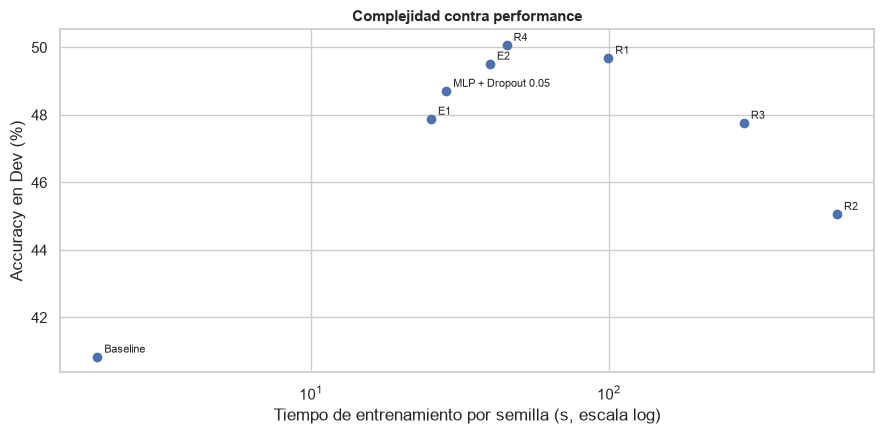

In [6]:
# ==============================================================================
# 3.1 TABLA COMPARATIVA
# ==============================================================================
ARQ = {
    "E1 — Desde cero, 16 dim.":  "Embedding(16) → Dense 128-64-32 → softmax",
    "E2 — Desde cero, 300 dim.": "Embedding(300) → Dense 128-64-32 → softmax",
    "R1 — LSTM, 5 caracteres":   "Embedding(300) → LSTM(128) → softmax, 5 caracteres",
    "R2 — LSTM, 40 caracteres":  "Embedding(300) → LSTM(128) → softmax, 40 caracteres",
    "R3 — LSTM 40 + ES":         "Embedding(300) → LSTM(128) → softmax, 40 caracteres, Early Stopping",
    "R4 — LSTM 5 + ES":          "Embedding(300) → LSTM(128) → softmax, 5 caracteres, Early Stopping",
}
filas = [
    {"Etapa": 1, "Modelo": "Baseline", "Arquitectura": f"One-hot de {ref_base['K']} caracteres → regresión logística",
     "Parámetros": ref_base["parametros_entrenables"], "Dev": f"{ref_base['accuracy_dev']*100:.2f}%",
     "Test": "—", "Tiempo por semilla (s)": ref_base["tiempo_entrenamiento_s"], "Corridas": 1},
    {"Etapa": 2, "Modelo": f"MLP + {reg2['ganador']}", "Arquitectura": "One-hot → Dense 128-64-32 → softmax",
     "Parámetros": ref2["params"], "Dev": f"{ref2['dev_acc_mean']*100:.2f}% ± {ref2['dev_acc_std']*100:.2f}%",
     "Test": "—", "Tiempo por semilla (s)": ref2["tiempo_mean"], "Corridas": 5},
]
for n, r in res3["resultados"].items():
    if n not in ARQ:
        continue  # E0 es el mismo modelo que el ganador de la Etapa 2
    filas.append({"Etapa": 3, "Modelo": n, "Arquitectura": ARQ[n], "Parámetros": r["params"],
                  "Dev": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
                  "Test": f"{df_test['test_acc'].mean()*100:.2f}% ± {df_test['test_acc'].std()*100:.2f}%" if n == GANADOR else "—",
                  "Tiempo por semilla (s)": r["tiempo_mean"], "Corridas": 5})

tabla_final = pd.DataFrame(filas).set_index("Modelo")
tabla_final["Parámetros"] = tabla_final["Parámetros"].map("{:,}".format)
# Total = tiempo por semilla × cantidad de corridas (el baseline es determinístico y se entrena una vez)
tabla_final["Total con 5 semillas (min)"] = (tabla_final["Tiempo por semilla (s)"] * tabla_final.pop("Corridas") / 60).round(1)
tabla_final["Tiempo por semilla (s)"] = tabla_final["Tiempo por semilla (s)"].round(1)
display(tabla_final)

# Complejidad contra performance: parámetros y tiempo frente a la accuracy en Dev
dev_num = [ref_base["accuracy_dev"], ref2["dev_acc_mean"]] + [res3["resultados"][n]["dev_acc_mean"] for n in tabla_final.index[2:]]
t_num = [ref_base["tiempo_entrenamiento_s"], ref2["tiempo_mean"]] + [res3["resultados"][n]["tiempo_mean"] for n in tabla_final.index[2:]]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(t_num, np.array(dev_num) * 100)
for n, t, a in zip(tabla_final.index, t_num, dev_num):
    ax.annotate(n.split(" — ")[0], (t, a * 100), textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Tiempo de entrenamiento por semilla (s, escala log)")
ax.set_ylabel("Accuracy en Dev (%)")
ax.set_title("Complejidad contra performance", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Trade-off entre complejidad y performance.**
- **El salto más grande es el primero:** del baseline al MLP, los parámetros pasan de 19.908 a 53.536 y la accuracy en Dev sube $7,88$ pp.
- **Después, cada punto cuesta mucho más:** del MLP a R4, los parámetros se multiplican por 4,6 (247.104) y la accuracy sube $1,36$ pp. El tiempo por corrida pasa de 28 a 45 s, gracias a que Early Stopping corta a R4 en unas 47 épocas.
- **El costo real es el total:** la Etapa 3 completa entrena unos 93 minutos, y solo R2 se lleva 49 (583 s por semilla). R4, el ganador, tarda 4 minutos con las 5 semillas.
- **Más complejidad no garantiza más acierto:** R2, el modelo más lento ($583$ s por corrida), es el peor de la Etapa 3. Del otro lado, E1 alcanza $47,88\%$ con 23.840 parámetros, menos de la mitad que el MLP.

---
# 4. Consigna 4.5.3: Análisis ético y de sesgos
### 4.1 Sesgos del texto
El dataset es un solo cuento de 1923, en inglés literario y narrado en primera persona por un hombre. Antes de opinar, medimos en el texto dos cosas que se pueden contar: el **género** de los pronombres y sustantivos de persona, y qué tan **arcaico o raro** es el vocabulario respecto del resto del cuento.

In [7]:
# ==============================================================================
# 4.1 SESGOS MEDIBLES EN EL TEXTO
# ==============================================================================
palabras = re.findall(r"[a-z]+", text.lower())
frec = Counter(palabras)

GENERO = {
    "masculino": ["he", "him", "his", "himself", "man", "men", "father", "fathers", "son", "sons", "brother", "grandfather", "sir"],
    "femenino":  ["she", "her", "hers", "herself", "woman", "women", "mother", "mothers", "daughter", "sister", "grandmother", "lady"],
}
df_gen = pd.DataFrame({g: {"Apariciones": sum(frec[w] for w in ws),
                           "Palabras presentes": ", ".join(f"{w} ({frec[w]})" for w in ws if frec[w])}
                       for g, ws in GENERO.items()}).T
display(df_gen)

n_unicas = len(frec)
hapax = sum(1 for w, n in frec.items() if n == 1)
print(f"Palabras en el texto: {len(palabras):,} | distintas: {n_unicas:,} | aparecen una sola vez: {hapax:,} ({hapax/n_unicas*100:.1f}% del vocabulario)")

,Apariciones,Palabras presentes
masculino,52,"he (18), him (3), his (9), himself (1), man (1..."
femenino,10,"her (2), woman (8)"


Palabras en el texto: 3,621 | distintas: 1,235 | aparecen una sola vez: 858 (69.5% del vocabulario)


**Interpretación.**
- **Género:** las palabras masculinas aparecen 52 veces y las femeninas 10. Del lado femenino solo hay *woman* (8) y *her* (2); *she* no aparece nunca. El narrador es un hombre, y *man* aparece 15 veces, 12 de ellas como *old man*, el anciano que lo guía. *woman* aparece sobre todo como *old woman* (5 de 8).
- **Idioma y época:** es inglés literario de 1923 de un solo autor. El $69,5\%$ de las palabras distintas aparece una sola vez, muchas de ellas arcaicas o propias del estilo de Lovecraft (*eldritch*, *daemonolatreia*). El modelo aprende ese estilo y nada más.
- **Lo que no podemos medir:** etnia o clase social no se reflejan en conteos simples de un cuento de 3.621 palabras. Lo dejamos como limitación, no como ausencia de sesgo.
- **Qué implica para el modelo:** no predice palabras sino caracteres, pero aprende las frecuencias de las secuencias del texto. Si generara texto, reproduciría estas proporciones y este registro.

### 4.2 Desempeño por subgrupos en Test
Medimos la accuracy del ganador en Test (media de las 5 semillas) en dos agrupaciones, y la comparamos con Dev:
1. **Tipo de carácter**, las mismas categorías de las Etapas 2 y 3.
2. **Frecuencia del carácter en Train:** los 10 más frecuentes, los puestos 11 a 30 y el resto. Muestra si el modelo trata peor a las clases poco representadas.

,Casos en Test,Accuracy Dev,Accuracy Test
espacio,443,0.9066,0.8628
vocal,745,0.4193,0.4046
consonante,1231,0.4310,0.3751
mayúscula,48,0.1579,0.1000
puntuación/dígito,53,0.0333,0.0264


,Casos en Test,Accuracy Dev,Accuracy Test
top 10,1817,0.5782,0.5334
puestos 11-30,670,0.3091,0.2710
puesto 31 o más,33,0.0952,0.0242


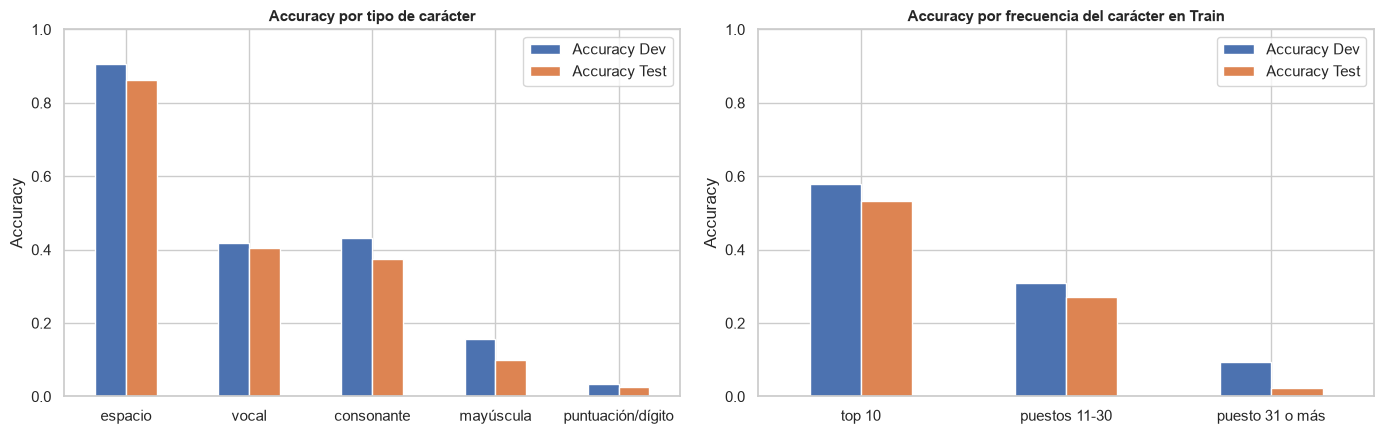

In [8]:
# ==============================================================================
# 4.2 ACCURACY POR SUBGRUPO EN TEST Y EN DEV
# ==============================================================================
def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

ranking = [c for c, _ in Counter(y_train).most_common()]
def grupo_frecuencia(c):
    p = ranking.index(c) if c in ranking else len(ranking)
    return "top 10" if p < 10 else ("puestos 11-30" if p < 30 else "puesto 31 o más")

def por_subgrupo(funcion, orden):
    g_dev = np.array([funcion(c) for c in y_dev])
    g_test = np.array([funcion(c) for c in y_test])
    return pd.DataFrame({"Casos en Test": [int((g_test == g).sum()) for g in orden],
                         "Accuracy Dev": [aciertos_dev[:, g_dev == g].mean() for g in orden],
                         "Accuracy Test": [aciertos_test[:, g_test == g].mean() for g in orden]}, index=orden).round(4)

df_tipo = por_subgrupo(tipo_caracter, ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"])
df_frec = por_subgrupo(grupo_frecuencia, ["top 10", "puestos 11-30", "puesto 31 o más"])
display(df_tipo)
display(df_frec)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df_tipo[["Accuracy Dev", "Accuracy Test"]].plot.bar(ax=axes[0], rot=0)
df_frec[["Accuracy Dev", "Accuracy Test"]].plot.bar(ax=axes[1], rot=0)
axes[0].set_title("Accuracy por tipo de carácter", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy por frecuencia del carácter en Train", fontsize=11, fontweight="bold")
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Accuracy")
plt.tight_layout()
plt.show()

**Interpretación.**
- **El modelo no rinde igual para todos los caracteres.** En Test acierta el $86,28\%$ de los espacios, alrededor del $40\%$ de las letras minúsculas, el $10,00\%$ de las mayúsculas y el $2,64\%$ de la puntuación. El orden es el mismo que en Dev.
- **La caída de Dev a Test no es pareja:** las consonantes pierden $5,59$ pp y el espacio $4,38$ pp, mientras que las vocales pierden $1,47$ pp. En mayúsculas y puntuación hay 48 y 53 casos, así que sus diferencias son de pocos aciertos.
- **Por frecuencia, la brecha es enorme:** acierta el $53,34\%$ de los 10 caracteres más frecuentes, el $27,10\%$ de los puestos 11 a 30 y el $2,42\%$ del resto (33 casos). Es el desbalance que vimos en la Etapa 1: el modelo aprende bien lo que aparece mucho en Train.
- **Los subgrupos peor servidos son los que más significado cargan:** las mayúsculas marcan nombres propios e inicios de oración, y la puntuación, la estructura del texto.

### 4.3 Desempeño según la función del carácter en el texto
Agrupación propuesta por Thiago en su versión de la Etapa 5: cada carácter de Test se clasifica según qué papel cumple (cerrar una palabra, empezarla, completarla, puntuar o abrir una oración) y se mide la accuracy y la perplejidad de cada grupo.

,Casos en Test,% del Test,Accuracy Dev,Accuracy Test,Perplejidad Test
cierre de palabra (espacio),443,17.6,0.9066,0.8628,1.8321
interior de palabra,1578,62.6,0.4899,0.4359,7.0855
inicio de palabra,398,15.8,0.1873,0.1894,17.1914
inicio de oración o nombre propio,48,1.9,0.1579,0.1000,116.5457
puntuación,53,2.1,0.0000,0.0264,62.9634


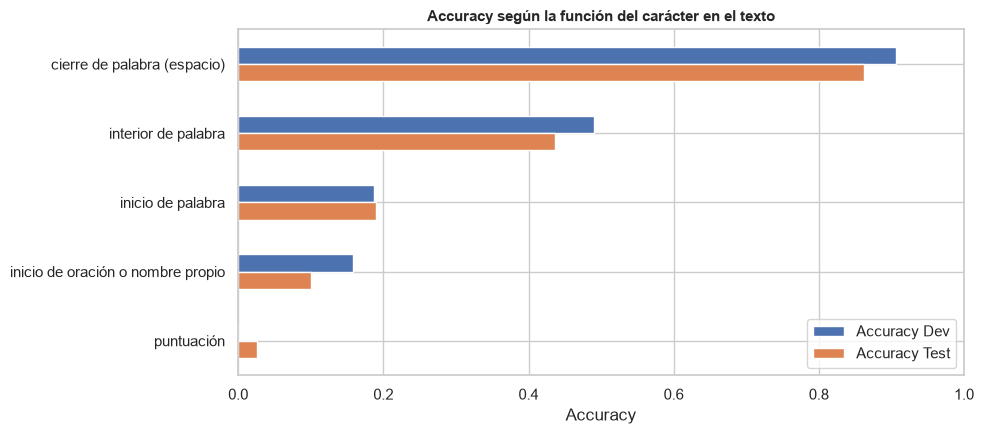

In [9]:
# ==============================================================================
# 4.3 SUBGRUPOS POR FUNCIÓN EN EL TEXTO (categorías de la versión de Thiago)
# ==============================================================================
def funcion_en_texto(ctx, ch):
    previo = ctx[-1]
    if ch in "\n.,;:!?—-\"'":
        return "puntuación"
    if ch == " ":
        return "cierre de palabra (espacio)"
    if previo in " \n—\"'" and ch.isalpha():
        return "inicio de oración o nombre propio" if ch.isupper() else "inicio de palabra"
    if ch.isupper():
        return "mayúscula intermedia"
    return "interior de palabra"

ORDEN_FUNCION = ["cierre de palabra (espacio)", "interior de palabra", "inicio de palabra",
                 "inicio de oración o nombre propio", "mayúscula intermedia", "puntuación"]
func_test = np.array([funcion_en_texto(x, ch) for x, ch in zip(X_test, y_test)])
func_dev = np.array([funcion_en_texto(x, ch) for x, ch in zip(X_dev, y_dev)])
presentes = [g for g in ORDEN_FUNCION if (func_test == g).any()]

# Perplejidad del grupo: exp de la entropía cruzada media de sus ventanas (5 semillas)
df_func = pd.DataFrame({
    "Casos en Test": [int((func_test == g).sum()) for g in presentes],
    "% del Test": [round((func_test == g).mean() * 100, 1) for g in presentes],
    "Accuracy Dev": [aciertos_dev[:, func_dev == g].mean() for g in presentes],
    "Accuracy Test": [aciertos_test[:, func_test == g].mean() for g in presentes],
    "Perplejidad Test": [float(np.exp(-np.mean(np.log(p_real_test[:, func_test == g] + 1e-12)))) for g in presentes],
}, index=presentes).round(4)
display(df_func)

fig, ax = plt.subplots(figsize=(10, 4.5))
df_func[["Accuracy Dev", "Accuracy Test"]].plot.barh(ax=ax)
ax.set_xlim(0, 1)
ax.set_xlabel("Accuracy")
ax.invert_yaxis()
ax.set_title("Accuracy según la función del carácter en el texto", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.**
- **El mismo patrón que encontró Thiago con otra partición y otro modelo.** Cerrar una palabra es fácil ($86,28\%$; en su versión, $91,25\%$), completarla es intermedio ($43,59\%$ contra $44,49\%$) y empezarla es difícil ($18,94\%$ contra $18,33\%$). Que dos enfoques distintos den casi los mismos números indica que la dificultad está en el texto, no en un detalle de nuestro modelo.
- **El primer carácter de cada palabra es el grupo crítico:** es el $15,8\%$ de Test y la perplejidad sube a $17,19$, contra $7,09$ en el interior de la palabra.
- **Mayúsculas y puntuación casi no se aciertan** ($10,00\%$ y $2,64\%$), con perplejidades de $116,55$ y $62,96$: cuando falla, el modelo le había dado muy poca probabilidad al carácter real.

### 4.4 Riesgos en un sistema real y mitigación
Un modelo así se usaría para autocompletar o generar texto. Los riesgos que muestran nuestros resultados:
1. **Fuera de su dominio rinde peor.** Aprendió el inglés de un solo cuento de 1923; con texto actual, otro idioma u otro registro, el *data mismatch* bajaría la accuracy. Entre Dev y Test, que son partes del mismo cuento, ya cae $4,37$ pp.
2. **Reproduce el sesgo del texto.** Con 52 menciones masculinas contra 10 femeninas, al generar texto tendería a continuar en masculino y en el registro de Lovecraft.
3. **Falla justo en lo más sensible:** nombres propios (mayúsculas) y puntuación, que es donde un error cambia el sentido de una frase.

**Mitigación:**
- Entrenar con un corpus más grande y variado, y documentar de dónde sale (autores, épocas, registro).
- Medir el desempeño por subgrupo antes de usarlo, como en la sección 4.2, y no aplicarlo a otro dominio sin volver a evaluarlo.
- Si genera texto: muestreo *top-k* o *nucleus* (*top-p*) con temperatura controlada, para no elegir caracteres improbables que rompen la ortografía ni caer en repeticiones; filtros de diccionario y de contenido antes de mostrar el resultado; revisión humana y un aviso claro de que imita el estilo de un autor de 1923 (propuestas de la versión de Thiago).

---
# 5. Consigna 4.5.4: Conclusiones

### Aprendizajes más importantes
1. **La partición decide si los números valen.** Las ventanas con stride 1 se solapan en 39 caracteres; sin la partición por bloques, Dev y Test hubieran compartido texto con Train.
2. **La mayor mejora vino primero:** del baseline al MLP, $+7,88$ pp en Dev. Embeddings y LSTM sumaron $+1,36$ pp más.
3. **Cuándo parar importa tanto como la arquitectura.** R4 es la misma LSTM que R1 cortada a tiempo: igual accuracy, mucho mejor perplejidad y la mitad del tiempo.
4. **Con pocos datos, el contexto largo no se aprovecha:** la LSTM de 40 caracteres quedó siempre por debajo de la de 5.
5. **Lo pre-entrenado ayuda cuando la unidad tiene significado:** GloVe mejoró la predicción de palabras.
6. **Test confirma que el modelo generaliza, pero menos de lo que decía Dev:** $45,70\%$ contra $50,07\%$.
7. **El límite son los datos:** sumar un segundo cuento a Train sube R4 $4,09$ pp en Dev, más que cualquier cambio de arquitectura.

### Lo más desafiante y cómo se resolvió
- **Diferencias del tamaño del ruido.** Muchas mejoras eran de décimas de punto. Lo resolvimos con 5 semillas por modelo y media ± desvío, y comparando cada mejora con el desvío.
- **Tiempo de entrenamiento sin GPU.** La LSTM de 40 caracteres tardaba casi 10 minutos por semilla. Lo resolvimos con Early Stopping y guardando los resultados de R2 para no reentrenarlo.
- **La perplejidad con L1/L2.** En su versión, Thiago detectó que con L1/L2 la `val_loss` de Keras suma la penalización de los pesos, así que la perplejidad calculada con ella sale inflada; la recalculó solo con la entropía cruzada para comparar modelos en igualdad de condiciones.
- **Unificar el trabajo del grupo.** En paralelo probamos otra partición y otra métrica, y una versión con más cuentos. El notebook final usa una sola partición para que todas las cifras sean comparables, y la idea de más cuentos se midió sobre ella como experimento.

### Limitaciones y qué haríamos diferente
- **Un solo cuento**, de unos 20.000 caracteres: es la limitación principal, como muestra el experimento con *The Call of Cthulhu*.
- **Dev de 8 bloques:** la brecha con Test muestra que no estima con precisión. Con más tiempo, usaríamos validación cruzada por bloques.
- **Test solo para el ganador:** no sabemos si el orden entre los modelos se mantiene fuera de Dev.
- **Con más tiempo:** rehacer las Etapas 2 y 3 con varios cuentos en Train y graficar la curva de aprendizaje; probar la LSTM de 40 caracteres con más datos y GPU; y hacer la Etapa 4 (optativa), por ejemplo un VAE sobre ventanas de caracteres.

In [10]:
# ==============================================================================
# 5.1 PERSISTENCIA DE LOS RESULTADOS DE LA ETAPA 5
# ==============================================================================
with open(PROC / "resultados_etapa5.json", "w", encoding="utf-8") as f:
    json.dump({"ganador": GANADOR, "config": CFG_GANADOR, "corridas": corridas,
               "dev_acc_mean": float(df_test["dev_acc"].mean()), "test_acc_mean": float(df_test["test_acc"].mean()),
               "test_acc_std": float(df_test["test_acc"].std()),
               "subgrupos": {"tipo": df_tipo.to_dict(), "frecuencia": df_frec.to_dict(), "funcion": df_func.to_dict()}},
              f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_etapa5.json")

Resultados guardados en data/processed/resultados_etapa5.json
